If runtime restarted, rerun only:

Cell 1  → Mount Drive + imports + folders

Cell 2  → Dataset path

Cell 3  → Class names + class mapping

Cell 6  → Load saved train/val/test splits

Cell 7  → Dataset class + create_dataloaders function


In [ ]:
# ============================================================
# CELL 1: MOUNT DRIVE + IMPORT LIBRARIES + GLOBAL VARIABLES
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ----------------------------
# Reproducibility
# ----------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ----------------------------
# Device
# ----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Libraries imported successfully.")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Use Runtime > Change runtime type > T4 GPU before model training.")

# ----------------------------
# Permanent project folders
# ----------------------------
PROJECT_DIR = Path("/content/drive/MyDrive/Ovarian_Research_Project")

SPLIT_DIR = PROJECT_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "models"
RESULT_DIR = PROJECT_DIR / "results"
FIGURE_DIR = PROJECT_DIR / "figures"

for folder in [PROJECT_DIR, SPLIT_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("\nProject folder ready:")
print("PROJECT_DIR:", PROJECT_DIR)
print("SPLIT_DIR:", SPLIT_DIR)
print("MODEL_DIR:", MODEL_DIR)
print("RESULT_DIR:", RESULT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Libraries imported successfully.
PyTorch version: 2.11.0+cpu
CUDA available: False
Device: cpu
GPU not available. Use Runtime > Change runtime type > T4 GPU before model training.

Project folder ready:
PROJECT_DIR: /content/drive/MyDrive/Ovarian_Research_Project
SPLIT_DIR: /content/drive/MyDrive/Ovarian_Research_Project/splits
MODEL_DIR: /content/drive/MyDrive/Ovarian_Research_Project/models
RESULT_DIR: /content/drive/MyDrive/Ovarian_Research_Project/results
FIGURE_DIR: /content/drive/MyDrive/Ovarian_Research_Project/figures


In [ ]:
# ============================================================
# CELL 2: SET DATASET PATH
# ============================================================

# Your dataset should be in Google Drive like:
# /content/drive/MyDrive/Ovarian_US

possible_data_dirs = [
    Path("/content/drive/MyDrive/Ovarian_US"),
    Path("/content/drive/MyDrive/Research/Ovarian_US"),
    Path("/content/Mydrive/MyDrive/Ovarian_US")  # fallback for your older mount style
]

DATA_DIR = None

for path in possible_data_dirs:
    if path.exists():
        DATA_DIR = path
        break

if DATA_DIR is None:
    raise FileNotFoundError(
        "Dataset folder not found. Please update DATA_DIR manually. "
        "Expected folder: /content/drive/MyDrive/Ovarian_US"
    )

print("Dataset folder found.")
print("DATA_DIR:", DATA_DIR)

Dataset folder found.
DATA_DIR: /content/drive/MyDrive/Ovarian_US


In [ ]:
# ============================================================
# CELL 3: READ CLASSES, COUNT IMAGES, CREATE IMAGE DATAFRAME
# ============================================================

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_names = sorted([
    folder.name for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

NUM_CLASSES = len(class_names)

print("Classes found:")
for cls in class_names:
    print("-", cls)
print("\nTotal classes:", NUM_CLASSES)

# Class mapping
class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
idx_to_class = {idx: class_name for class_name, idx in class_to_idx.items()}

print("\nClass mapping:")
print(class_to_idx)

# Count images and create dataframe
records = []
class_counts = {}

for class_name in class_names:
    class_path = DATA_DIR / class_name

    image_files = [
        file for file in class_path.iterdir()
        if file.is_file() and file.suffix.lower() in valid_extensions
    ]

    class_counts[class_name] = len(image_files)

    for file in image_files:
        records.append({
            "image_path": str(file),
            "label": class_name,
            "label_id": class_to_idx[class_name]
        })

df = pd.DataFrame(records)

count_df = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Image Count": list(class_counts.values())
})

print("\nClass distribution:")
display(count_df)

print("\nTotal images found:", len(df))
display(df.head())

Classes found:
- complex_cyst
- dominant_follicle
- healthy
- poly_cyst
- simple_cyst

Total classes: 5

Class mapping:
{'complex_cyst': 0, 'dominant_follicle': 1, 'healthy': 2, 'poly_cyst': 3, 'simple_cyst': 4}

Class distribution:


,Class,Image Count
0,complex_cyst,1368
1,dominant_follicle,1296
2,healthy,1464
3,poly_cyst,1422
4,simple_cyst,1326



Total images found: 6876


,image_path,label,label_id
0,/content/drive/MyDrive/Ovarian_US/complex_cyst...,complex_cyst,0
1,/content/drive/MyDrive/Ovarian_US/complex_cyst...,complex_cyst,0
2,/content/drive/MyDrive/Ovarian_US/complex_cyst...,complex_cyst,0
3,/content/drive/MyDrive/Ovarian_US/complex_cyst...,complex_cyst,0
4,/content/drive/MyDrive/Ovarian_US/complex_cyst...,complex_cyst,0


In [ ]:
# ============================================================
# DAY 1 - CELL 5: COUNT IMAGES IN EACH CLASS
# ============================================================

valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_counts = {}

for class_name in class_names:
    class_path = DATA_DIR / class_name

    image_files = [
        file for file in class_path.iterdir()
        if file.is_file() and file.suffix.lower() in valid_extensions
    ]

    class_counts[class_name] = len(image_files)

count_df = pd.DataFrame({
    "Class": list(class_counts.keys()),
    "Image Count": list(class_counts.values())
})

print("Class distribution:")
display(count_df)

print("\nTotal images:", count_df["Image Count"].sum())

Class distribution:


,Class,Image Count
0,complex_cyst,1368
1,dominant_follicle,1296
2,healthy,1464
3,poly_cyst,1422
4,simple_cyst,1326



Total images: 6876


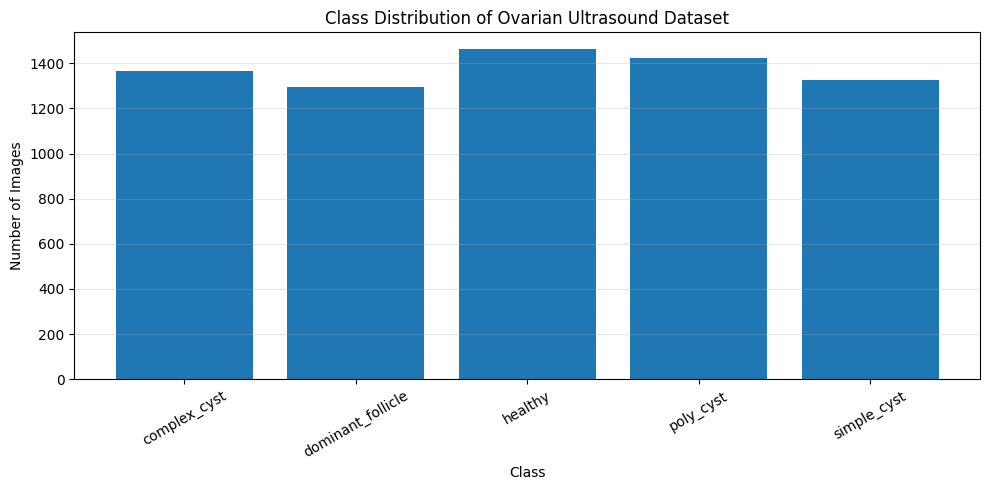

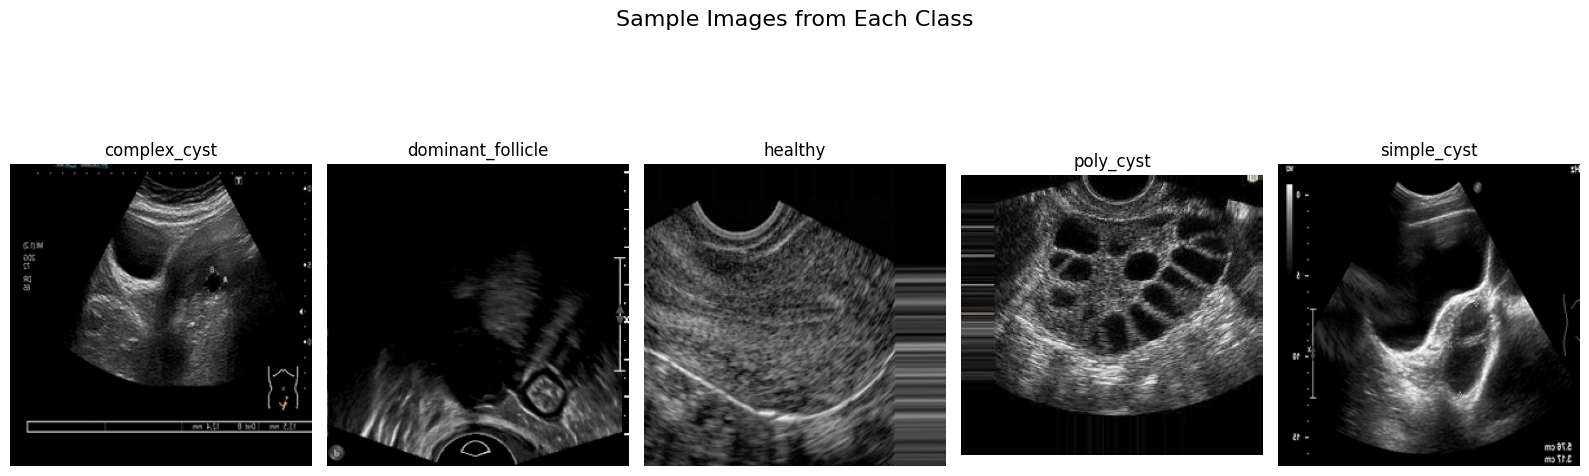

Figures saved in: /content/drive/MyDrive/Ovarian_Research_Project/figures


In [ ]:
# ============================================================
# CELL 4: PLOT CLASS DISTRIBUTION + SHOW SAMPLE IMAGES
# ============================================================

plt.figure(figsize=(10, 5))
plt.bar(count_df["Class"], count_df["Image Count"])
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Class Distribution of Ovarian Ultrasound Dataset")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# Show one sample image from each class
plt.figure(figsize=(16, 6))

for i, class_name in enumerate(class_names):
    class_images = df[df["label"] == class_name]["image_path"].tolist()
    sample_path = random.choice(class_images)
    image = Image.open(sample_path).convert("RGB")

    plt.subplot(1, len(class_names), i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.suptitle("Sample Images from Each Class", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "sample_images_each_class.png", dpi=300, bbox_inches="tight")
plt.show()

print("Figures saved in:", FIGURE_DIR)

In [ ]:
# ============================================================
# CELL 5: FAST CORRUPTED IMAGE CHECK
# ============================================================
# Full corrupted image checking can take 30+ minutes on Google Drive.
# This faster version checks a random sample. Increase SAMPLE_CHECK_SIZE if needed.

SAMPLE_CHECK_SIZE = min(200, len(df))

sample_df = df.sample(n=SAMPLE_CHECK_SIZE, random_state=SEED)
corrupted_images = []

for img_path in sample_df["image_path"]:
    try:
        img = Image.open(img_path)
        img.verify()
    except Exception:
        corrupted_images.append(img_path)

print("Random sample checked:", SAMPLE_CHECK_SIZE)
print("Corrupted images found in sample:", len(corrupted_images))

if len(corrupted_images) > 0:
    print("First few corrupted paths:")
    print(corrupted_images[:5])
else:
    print("No corrupted images found in random sample.")

Random sample checked: 200
Corrupted images found in sample: 0
No corrupted images found in random sample.


In [ ]:
# ============================================================
# CELL 6: CREATE OR LOAD STRATIFIED TRAIN/VAL/TEST SPLITS
# ============================================================

def repair_image_paths(split_df, current_data_dir):
    """
    If CSV was saved with old Colab path, repair it to current DATA_DIR.
    This prevents errors after changing mount path.
    """
    split_df = split_df.copy()

    if len(split_df) == 0:
        return split_df

    first_path = Path(split_df.loc[0, "image_path"])

    if first_path.exists():
        return split_df

    old_prefixes = [
        "/content/Mydrive/MyDrive/Ovarian_US",
        "/content/drive/MyDrive/Ovarian_US",
        "/content/drive/MyDrive/Research/Ovarian_US"
    ]

    current_prefix = str(current_data_dir)

    def fix_path(p):
        p = str(p)
        for old in old_prefixes:
            if p.startswith(old):
                return p.replace(old, current_prefix)
        return p

    split_df["image_path"] = split_df["image_path"].apply(fix_path)
    return split_df


train_csv = SPLIT_DIR / "train.csv"
val_csv = SPLIT_DIR / "val.csv"
test_csv = SPLIT_DIR / "test.csv"

if train_csv.exists() and val_csv.exists() and test_csv.exists():
    print("Saved split files found. Loading existing splits...")

    train_df = pd.read_csv(train_csv)
    val_df = pd.read_csv(val_csv)
    test_df = pd.read_csv(test_csv)

    train_df = repair_image_paths(train_df, DATA_DIR)
    val_df = repair_image_paths(val_df, DATA_DIR)
    test_df = repair_image_paths(test_df, DATA_DIR)

    # Save repaired paths if needed
    train_df.to_csv(train_csv, index=False)
    val_df.to_csv(val_csv, index=False)
    test_df.to_csv(test_csv, index=False)

else:
    print("No saved split found. Creating new stratified split...")

    train_df, temp_df = train_test_split(
        df,
        test_size=0.30,
        stratify=df["label"],
        random_state=SEED
    )

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        stratify=temp_df["label"],
        random_state=SEED
    )

    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    train_df.to_csv(train_csv, index=False)
    val_df.to_csv(val_csv, index=False)
    test_df.to_csv(test_csv, index=False)

    print("New splits saved successfully.")

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total after split:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining distribution:")
display(train_df["label"].value_counts().sort_index())

print("\nValidation distribution:")
display(val_df["label"].value_counts().sort_index())

print("\nTesting distribution:")
display(test_df["label"].value_counts().sort_index())

# Final path check
print("\nFirst train image exists:", Path(train_df.loc[0, "image_path"]).exists())
print("Splits saved at:", SPLIT_DIR)

Saved split files found. Loading existing splits...

Split sizes:
Train: 4813
Validation: 1031
Test: 1032
Total after split: 6876

Training distribution:


,count
label,
complex_cyst,958
dominant_follicle,907
healthy,1025
poly_cyst,995
simple_cyst,928



Validation distribution:


,count
label,
complex_cyst,205
dominant_follicle,195
healthy,219
poly_cyst,213
simple_cyst,199



Testing distribution:


,count
label,
complex_cyst,205
dominant_follicle,194
healthy,220
poly_cyst,214
simple_cyst,199



First train image exists: True
Splits saved at: /content/drive/MyDrive/Ovarian_Research_Project/splits


In [ ]:
# ============================================================
# CELL 7: PYTORCH DATASET CLASS + DATALOADER FUNCTION
# ============================================================

class OvarianUltrasoundDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        image_path = self.dataframe.loc[index, "image_path"]
        label = int(self.dataframe.loc[index, "label_id"])

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


def create_dataloaders(img_size=224, batch_size=32, num_workers=2, augment=True):
    """Create train, validation, and test DataLoaders."""

    if augment:
        train_transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=10),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])
    else:
        train_transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    val_test_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    train_dataset = OvarianUltrasoundDataset(train_df, transform=train_transform)
    val_dataset = OvarianUltrasoundDataset(val_df, transform=val_test_transform)
    test_dataset = OvarianUltrasoundDataset(test_df, transform=val_test_transform)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available()
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader, test_loader

# **ANN Baseline**

In [ ]:
# ============================================================
# CELL 8: CREATE ANN DATALOADERS AND CHECK ONE BATCH
# ============================================================

# For ANN, 128x128 is used because ANN flattens the image.
# 224x224 makes too many input features and becomes slower.

ANN_IMG_SIZE = 128
BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader, val_loader, test_loader = create_dataloaders(
    img_size=ANN_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("ANN DataLoaders created successfully.")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

ANN DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 128, 128])
Label batch shape: torch.Size([32])
First 10 labels: tensor([0, 2, 1, 1, 4, 1, 0, 2, 0, 3])


In [ ]:
# ============================================================
# CELL 9: DEFINE ANN BASELINE MODEL
# ============================================================

class ANNBaseline(nn.Module):
    def __init__(self, img_size=128, num_classes=5):
        super(ANNBaseline, self).__init__()

        self.img_size = img_size
        self.flatten = nn.Flatten()

        self.network = nn.Sequential(
            nn.Linear(3 * img_size * img_size, 512),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.network(x)
        return x


model = ANNBaseline(img_size=ANN_IMG_SIZE, num_classes=NUM_CLASSES).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model)
print("\nTotal parameters:", total_params)
print("Trainable parameters:", trainable_params)

ANNBaseline(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=49152, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=128, out_features=5, bias=True)
  )
)

Total parameters: 25331205
Trainable parameters: 25331205


In [ ]:
# ============================================================
# CELL 10: LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels

print("Training functions ready.")

Training functions ready.


In [ ]:
# ============================================================
# CELL 11: TRAIN ANN WITH CHECKPOINT SAVE AND RESUME
# ============================================================

MODEL_NAME = "ann_baseline"
EPOCHS = 10 if torch.cuda.is_available() else 5

# Set True only if you want to delete old checkpoint and train from start.
RESET_TRAINING = False

best_model_path = MODEL_DIR / f"{MODEL_NAME}_best.pth"
checkpoint_path = MODEL_DIR / f"{MODEL_NAME}_checkpoint.pth"
history_path = RESULT_DIR / f"{MODEL_NAME}_training_history.csv"

# ------------------------------------------------------------
# Optional reset: delete old checkpoint, best model, and history
# ------------------------------------------------------------
if RESET_TRAINING:
    if checkpoint_path.exists():
        checkpoint_path.unlink()
        print("Old checkpoint deleted.")

    if best_model_path.exists():
        best_model_path.unlink()
        print("Old best model deleted.")

    if history_path.exists():
        history_path.unlink()
        print("Old training history deleted.")

    print("Starting fresh training.")

best_val_acc = 0.0
start_epoch = 0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# ------------------------------------------------------------
# Resume from checkpoint if available
# ------------------------------------------------------------
if checkpoint_path.exists():
    checkpoint = torch.load(checkpoint_path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    start_epoch = checkpoint["epoch"]
    best_val_acc = checkpoint["best_val_acc"]
    train_losses = checkpoint["train_losses"]
    val_losses = checkpoint["val_losses"]
    train_accuracies = checkpoint["train_accuracies"]
    val_accuracies = checkpoint["val_accuracies"]

    print("Checkpoint found.")
    print("Resuming from epoch:", start_epoch)
    print("Best validation accuracy so far:", best_val_acc)
else:
    print("No checkpoint found. Starting fresh.")

print("\nStarting ANN training...")
print("Epochs:", EPOCHS)
print("Device:", device)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
if start_epoch >= EPOCHS:
    print("Training already completed for the selected number of epochs.")
else:
    for epoch in range(start_epoch, EPOCHS):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        val_loss, val_acc, _, _ = validate_model(
            model, val_loader, criterion, device
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        # Save best model only when validation accuracy improves
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), best_model_path)

            print("Best ANN model saved.")
            print("Best Validation Accuracy:", best_val_acc)

        # Save latest checkpoint every epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_acc": best_val_acc,
            "train_losses": train_losses,
            "val_losses": val_losses,
            "train_accuracies": train_accuracies,
            "val_accuracies": val_accuracies,
            "img_size": ANN_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx
        }, checkpoint_path)

        # Save training history after every epoch
        history_df = pd.DataFrame({
            "epoch": list(range(1, len(train_losses) + 1)),
            "train_loss": train_losses,
            "val_loss": val_losses,
            "train_accuracy": train_accuracies,
            "val_accuracy": val_accuracies
        })

        history_df.to_csv(history_path, index=False)

        print("Checkpoint saved:", checkpoint_path)
        print("Training history saved:", history_path)
        print("-" * 50)

print("\nANN training completed.")
print("Best validation accuracy:", best_val_acc)
print("Best model path:", best_model_path)
print("Checkpoint path:", checkpoint_path)
print("Training history path:", history_path)

No checkpoint found. Starting fresh.

Starting ANN training...
Epochs: 10
Device: cuda
Epoch [1/10]
Train Loss: 1.3306 | Train Acc: 42.66%
Val Loss:   0.8689 | Val Acc:   65.47%
Best ANN model saved.
Best Validation Accuracy: 65.47041707080504
Checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/ann_baseline_checkpoint.pth
Training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/ann_baseline_training_history.csv
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.8532 | Train Acc: 64.47%
Val Loss:   0.5900 | Val Acc:   74.39%
Best ANN model saved.
Best Validation Accuracy: 74.39379243452959
Checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/ann_baseline_checkpoint.pth
Training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/ann_baseline_training_history.csv
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.6287 | Train Acc: 72.20%
Val Loss:   0.4

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,1.330597,0.868883,42.655309,65.470417
1,2,0.853250,0.590044,64.471224,74.393792
2,3,0.628654,0.485169,72.200291,80.504365
3,4,0.557008,0.431890,74.402659,81.183317
4,5,0.499689,0.377188,76.812799,80.989331
5,6,0.479465,0.404961,76.979015,77.982541
6,7,0.438934,0.332195,78.786620,86.129971
7,8,0.432408,0.316004,79.763141,82.444229
8,9,0.413114,0.310385,80.573447,82.153249
9,10,0.397574,0.279664,80.594224,89.330747


Training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/ann_baseline_training_history.csv


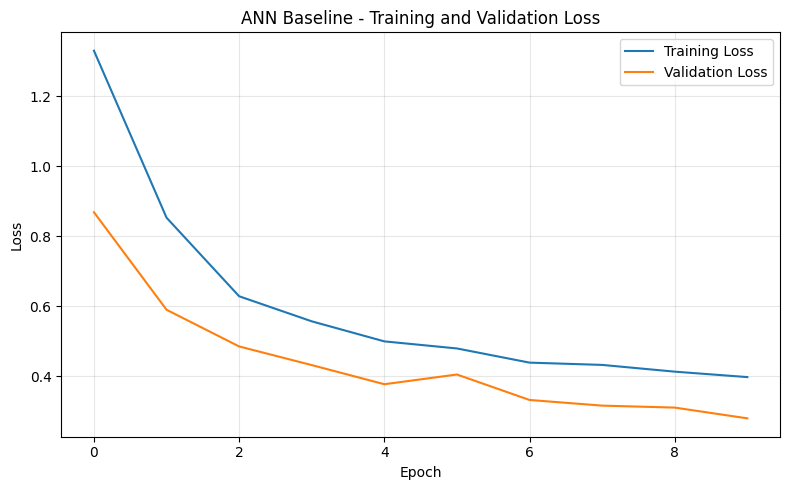

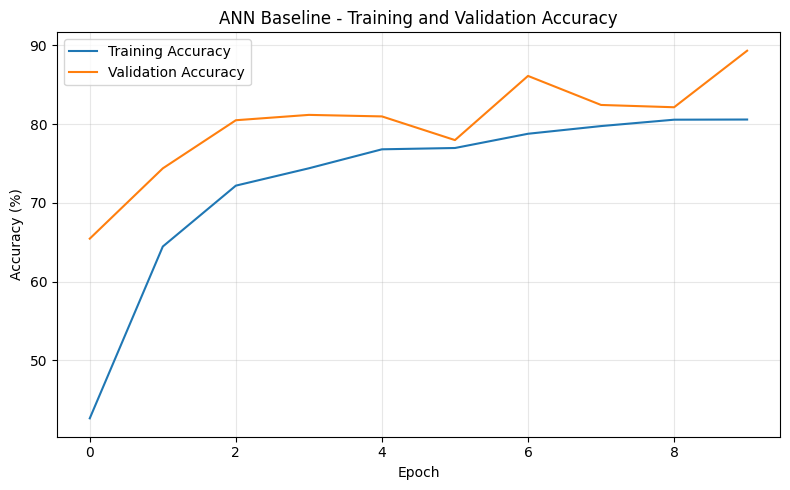

Loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/ann_baseline_loss_curve.png
Accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/ann_baseline_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 12: SAVE AND PLOT TRAINING CURVES
# ============================================================

# Use the same MODEL_NAME-based filename as Cell 11
history_path = RESULT_DIR / f"{MODEL_NAME}_training_history.csv"

history_df = pd.DataFrame({
    "epoch": list(range(1, len(train_losses) + 1)),
    "train_loss": train_losses,
    "val_loss": val_losses,
    "train_accuracy": train_accuracies,
    "val_accuracy": val_accuracies
})

history_df.to_csv(history_path, index=False)

display(history_df)
print("Training history saved at:", history_path)

loss_curve_path = FIGURE_DIR / f"{MODEL_NAME}_loss_curve.png"
accuracy_curve_path = FIGURE_DIR / f"{MODEL_NAME}_accuracy_curve.png"

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Baseline - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ANN Baseline - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("Loss curve saved at:", loss_curve_path)
print("Accuracy curve saved at:", accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 13: TEST ANN MODEL
# ============================================================

if not best_model_path.exists():
    raise FileNotFoundError("Best ANN model not found. Please train the model first.")

model.load_state_dict(torch.load(best_model_path, map_location=device))

test_loss, test_acc, test_preds, test_labels = validate_model(
    model, test_loader, criterion, device
)

print("ANN Test Loss:", round(test_loss, 4))
print("ANN Test Accuracy:", round(test_acc, 2), "%")

ANN Test Loss: 0.2753
ANN Test Accuracy: 90.5 %


Classification Report - ANN Baseline
                   precision    recall  f1-score   support

     complex_cyst       0.78      0.79      0.78       205
dominant_follicle       0.97      0.99      0.98       194
          healthy       1.00      1.00      1.00       220
        poly_cyst       0.99      0.99      0.99       214
      simple_cyst       0.78      0.74      0.76       199

         accuracy                           0.91      1032
        macro avg       0.90      0.90      0.90      1032
     weighted avg       0.90      0.91      0.90      1032

Classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/ann_classification_report.txt


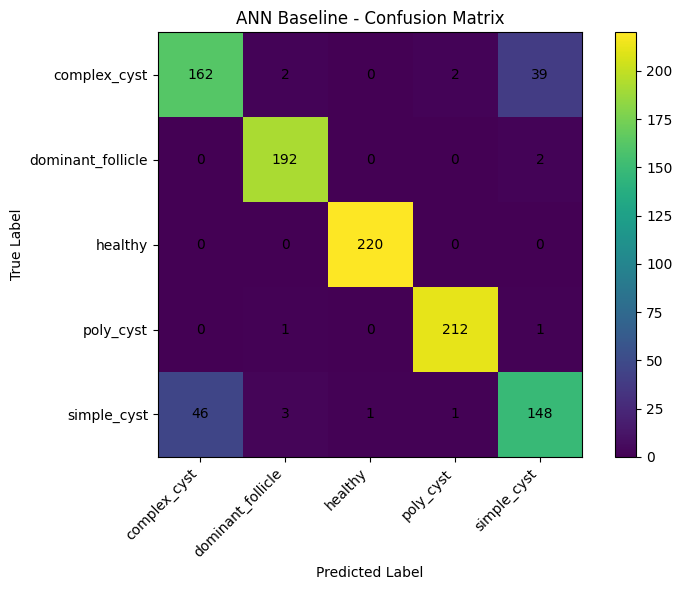

Confusion matrix saved in: /content/drive/MyDrive/Ovarian_Research_Project/figures


In [ ]:
# ============================================================
# CELL 14: CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - ANN Baseline")
report_text = classification_report(
    test_labels,
    test_preds,
    target_names=class_names,
    zero_division=0
)
print(report_text)

# Save text report
report_path = RESULT_DIR / "ann_classification_report.txt"
with open(report_path, "w") as f:
    f.write(report_text)

print("Classification report saved at:", report_path)

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(8, 6))
plt.imshow(cm)
plt.title("ANN Baseline - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(ticks=np.arange(len(class_names)), labels=class_names, rotation=45, ha="right")
plt.yticks(ticks=np.arange(len(class_names)), labels=class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ann_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print("Confusion matrix saved in:", FIGURE_DIR)

In [ ]:
# ============================================================
# CELL 15: SAVE ANN RESULT SUMMARY
# ============================================================

ann_accuracy = accuracy_score(test_labels, test_preds)
ann_precision = precision_score(test_labels, test_preds, average="weighted", zero_division=0)
ann_recall = recall_score(test_labels, test_preds, average="weighted", zero_division=0)
ann_f1 = f1_score(test_labels, test_preds, average="weighted", zero_division=0)

ann_results = pd.DataFrame([{
    "Model": "ANN Baseline",
    "Image Size": f"{ANN_IMG_SIZE}x{ANN_IMG_SIZE}",
    "Test Accuracy": ann_accuracy,
    "Precision": ann_precision,
    "Recall": ann_recall,
    "F1 Score": ann_f1,
    "Best Validation Accuracy": best_val_acc / 100,
    "Total Parameters": total_params,
    "Trainable Parameters": trainable_params,
    "Epochs Completed": len(train_losses),
    "Batch Size": BATCH_SIZE
}])

ann_results_path = RESULT_DIR / "ann_baseline_results.csv"
ann_results.to_csv(ann_results_path, index=False)

display(ann_results)

print("ANN results saved at:", ann_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size
0,ANN Baseline,128x128,0.905039,0.903889,0.905039,0.904356,0.893307,25331205,25331205,10,32


ANN results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/ann_baseline_results.csv


In [ ]:
# ============================================================
# VERIFY ALL ANN FILES SAVED IN GOOGLE DRIVE
# ============================================================

print("PROJECT_DIR:", PROJECT_DIR)
print("MODEL_DIR:", MODEL_DIR)
print("RESULT_DIR:", RESULT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)

files_to_check = {
    "ANN best model": MODEL_DIR / f"{MODEL_NAME}_best.pth",
    "ANN checkpoint": MODEL_DIR / f"{MODEL_NAME}_checkpoint.pth",
    "ANN training history": RESULT_DIR / f"{MODEL_NAME}_training_history.csv",
    "ANN result summary": RESULT_DIR / "ann_baseline_results.csv",
    "ANN model details": RESULT_DIR / "ann_model_details.csv",
    "ANN classification report": RESULT_DIR / "ann_classification_report.txt",
    "ANN loss curve": FIGURE_DIR / f"{MODEL_NAME}_loss_curve.png",
    "ANN accuracy curve": FIGURE_DIR / f"{MODEL_NAME}_accuracy_curve.png",
    "ANN confusion matrix": FIGURE_DIR / "ann_confusion_matrix.png",
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

PROJECT_DIR: /content/drive/MyDrive/Ovarian_Research_Project
MODEL_DIR: /content/drive/MyDrive/Ovarian_Research_Project/models
RESULT_DIR: /content/drive/MyDrive/Ovarian_Research_Project/results
FIGURE_DIR: /content/drive/MyDrive/Ovarian_Research_Project/figures
ANN best model: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/ann_baseline_best.pth
ANN checkpoint: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/ann_baseline_checkpoint.pth
ANN training history: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/ann_baseline_training_history.csv
ANN result summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/ann_baseline_results.csv
ANN model details: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/ann_model_details.csv
ANN classification report: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/ann_classification_report.txt
ANN loss curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/fi

In [ ]:
# ============================================================
# SAVE ANN MODEL DETAILS FOR REPORT
# ============================================================

ann_model_details = {
    "Model Name": "ANN Baseline",
    "Model Type": "Artificial Neural Network",
    "Input Image Size": f"{ANN_IMG_SIZE}x{ANN_IMG_SIZE}",
    "Input Shape": f"3 x {ANN_IMG_SIZE} x {ANN_IMG_SIZE}",
    "Number of Classes": len(class_names),
    "Classes": ", ".join(class_names),
    "Batch Size": BATCH_SIZE,
    "Epochs Completed": len(train_losses),
    "Optimizer": "Adam",
    "Loss Function": "CrossEntropyLoss",
    "Total Parameters": total_params,
    "Trainable Parameters": trainable_params,
    "Best Validation Accuracy": best_val_acc,
    "Best Model Path": str(best_model_path),
    "Checkpoint Path": str(checkpoint_path),
    "Training History Path": str(history_path),
    "Result Summary Path": str(RESULT_DIR / "ann_baseline_results.csv")
}

ann_model_details_df = pd.DataFrame([ann_model_details])

ann_model_details_path = RESULT_DIR / "ann_model_details.csv"
ann_model_details_df.to_csv(ann_model_details_path, index=False)

display(ann_model_details_df)

print("ANN model details saved at:", ann_model_details_path)

,Model Name,Model Type,Input Image Size,Input Shape,Number of Classes,Classes,Batch Size,Epochs Completed,Optimizer,Loss Function,Total Parameters,Trainable Parameters,Best Validation Accuracy,Best Model Path,Checkpoint Path,Training History Path,Result Summary Path
0,ANN Baseline,Artificial Neural Network,128x128,3 x 128 x 128,5,"complex_cyst, dominant_follicle, healthy, poly...",32,10,Adam,CrossEntropyLoss,25331205,25331205,89.330747,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...


ANN model details saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/ann_model_details.csv


### CNN BASELINE

In [ ]:
# ============================================================
# CELL 16: CREATE CNN BASELINE DATALOADERS AND CHECK ONE BATCH
# ============================================================

# CNN uses 224x224 because CNNs learn spatial features from images.
# This is standard for image classification experiments.

CNN_MODEL_NAME = "cnn_baseline"
CNN_IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

cnn_train_loader, cnn_val_loader, cnn_test_loader = create_dataloaders(
    img_size=CNN_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("CNN DataLoaders created successfully.")
print("Training batches:", len(cnn_train_loader))
print("Validation batches:", len(cnn_val_loader))
print("Testing batches:", len(cnn_test_loader))

images, labels = next(iter(cnn_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

CNN DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([0, 2, 1, 1, 4, 1, 0, 2, 0, 3])


In [ ]:
# ============================================================
# CELL 17: DEFINE CNN BASELINE MODEL
# ============================================================

class CNNBaseline(nn.Module):
    def __init__(self, num_classes=5):
        super(CNNBaseline, self).__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Fixed feature size for classifier
            nn.AdaptiveAvgPool2d((7, 7))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = CNNBaseline(num_classes=NUM_CLASSES).to(device)

cnn_total_params = sum(p.numel() for p in cnn_model.parameters())
cnn_trainable_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)

print(cnn_model)
print("\nCNN Total parameters:", cnn_total_params)
print("CNN Trainable parameters:", cnn_trainable_params)

CNNBaseline(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(7, 7))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_featur

In [ ]:
# ============================================================
# CELL 18: CNN LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

cnn_criterion = nn.CrossEntropyLoss()

cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.0001
)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels


print("CNN training functions ready.")

CNN training functions ready.


In [ ]:
# ============================================================
# CELL 19: TRAIN CNN BASELINE WITH CHECKPOINT SAVE AND RESUME
# ============================================================

EPOCHS = 10 if torch.cuda.is_available() else 5

# Set True only if you want to delete old CNN checkpoint and train from start.
RESET_CNN_TRAINING = False

cnn_best_model_path = MODEL_DIR / f"{CNN_MODEL_NAME}_best.pth"
cnn_checkpoint_path = MODEL_DIR / f"{CNN_MODEL_NAME}_checkpoint.pth"
cnn_history_path = RESULT_DIR / f"{CNN_MODEL_NAME}_training_history.csv"

# ------------------------------------------------------------
# Optional reset
# ------------------------------------------------------------
if RESET_CNN_TRAINING:
    if cnn_checkpoint_path.exists():
        cnn_checkpoint_path.unlink()
        print("Old CNN checkpoint deleted.")

    if cnn_best_model_path.exists():
        cnn_best_model_path.unlink()
        print("Old CNN best model deleted.")

    if cnn_history_path.exists():
        cnn_history_path.unlink()
        print("Old CNN training history deleted.")

    print("Starting fresh CNN training.")

cnn_best_val_acc = 0.0
cnn_start_epoch = 0

cnn_train_losses = []
cnn_val_losses = []
cnn_train_accuracies = []
cnn_val_accuracies = []

# ------------------------------------------------------------
# Resume from checkpoint if available
# ------------------------------------------------------------
if cnn_checkpoint_path.exists():
    checkpoint = torch.load(cnn_checkpoint_path, map_location=device)

    cnn_model.load_state_dict(checkpoint["model_state_dict"])
    cnn_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    cnn_start_epoch = checkpoint["epoch"]
    cnn_best_val_acc = checkpoint["best_val_acc"]
    cnn_train_losses = checkpoint["train_losses"]
    cnn_val_losses = checkpoint["val_losses"]
    cnn_train_accuracies = checkpoint["train_accuracies"]
    cnn_val_accuracies = checkpoint["val_accuracies"]

    print("CNN checkpoint found.")
    print("Resuming from epoch:", cnn_start_epoch)
    print("Best validation accuracy so far:", cnn_best_val_acc)
else:
    print("No CNN checkpoint found. Starting fresh.")

print("\nStarting CNN Baseline training...")
print("Epochs:", EPOCHS)
print("Device:", device)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
if cnn_start_epoch >= EPOCHS:
    print("CNN training already completed for the selected number of epochs.")
else:
    for epoch in range(cnn_start_epoch, EPOCHS):
        train_loss, train_acc = train_one_epoch(
            cnn_model,
            cnn_train_loader,
            cnn_criterion,
            cnn_optimizer,
            device
        )

        val_loss, val_acc, _, _ = validate_model(
            cnn_model,
            cnn_val_loader,
            cnn_criterion,
            device
        )

        cnn_train_losses.append(train_loss)
        cnn_val_losses.append(val_loss)
        cnn_train_accuracies.append(train_acc)
        cnn_val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        # Save best model only when validation accuracy improves
        if val_acc > cnn_best_val_acc:
            cnn_best_val_acc = val_acc
            torch.save(cnn_model.state_dict(), cnn_best_model_path)

            print("Best CNN model saved.")
            print("Best Validation Accuracy:", cnn_best_val_acc)

        # Save latest checkpoint every epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": cnn_model.state_dict(),
            "optimizer_state_dict": cnn_optimizer.state_dict(),
            "best_val_acc": cnn_best_val_acc,
            "train_losses": cnn_train_losses,
            "val_losses": cnn_val_losses,
            "train_accuracies": cnn_train_accuracies,
            "val_accuracies": cnn_val_accuracies,
            "img_size": CNN_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx
        }, cnn_checkpoint_path)

        # Save training history after every epoch
        cnn_history_df = pd.DataFrame({
            "epoch": list(range(1, len(cnn_train_losses) + 1)),
            "train_loss": cnn_train_losses,
            "val_loss": cnn_val_losses,
            "train_accuracy": cnn_train_accuracies,
            "val_accuracy": cnn_val_accuracies
        })

        cnn_history_df.to_csv(cnn_history_path, index=False)

        print("CNN checkpoint saved:", cnn_checkpoint_path)
        print("CNN training history saved:", cnn_history_path)
        print("-" * 50)

print("\nCNN Baseline training completed.")
print("Best validation accuracy:", cnn_best_val_acc)
print("Best model path:", cnn_best_model_path)
print("Checkpoint path:", cnn_checkpoint_path)
print("Training history path:", cnn_history_path)

No CNN checkpoint found. Starting fresh.

Starting CNN Baseline training...
Epochs: 10
Device: cuda
Epoch [1/10]
Train Loss: 0.7670 | Train Acc: 69.19%
Val Loss:   0.3027 | Val Acc:   90.20%
Best CNN model saved.
Best Validation Accuracy: 90.20368574199806
CNN checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/cnn_baseline_checkpoint.pth
CNN training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_baseline_training_history.csv
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.3275 | Train Acc: 86.04%
Val Loss:   0.2082 | Val Acc:   93.60%
Best CNN model saved.
Best Validation Accuracy: 93.5984481086324
CNN checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/cnn_baseline_checkpoint.pth
CNN training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_baseline_training_history.csv
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.2481 | Train

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.766956,0.302734,69.187617,90.203686
1,2,0.327479,0.208205,86.037814,93.598448
2,3,0.248080,0.169607,90.214004,94.083414
3,4,0.205040,0.150946,92.520258,94.374394
4,5,0.180804,0.134269,93.372117,94.471387
5,6,0.157223,0.126492,94.078537,94.471387
6,7,0.144758,0.116352,94.286308,94.665373
7,8,0.126643,0.113785,95.117390,94.762367
8,9,0.117689,0.104337,95.408269,95.247333
9,10,0.113776,0.097604,95.055059,95.926285


CNN training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_baseline_training_history.csv


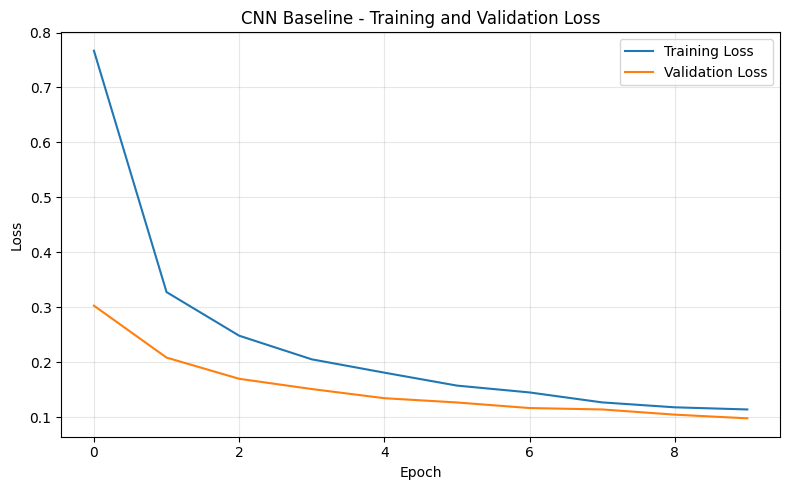

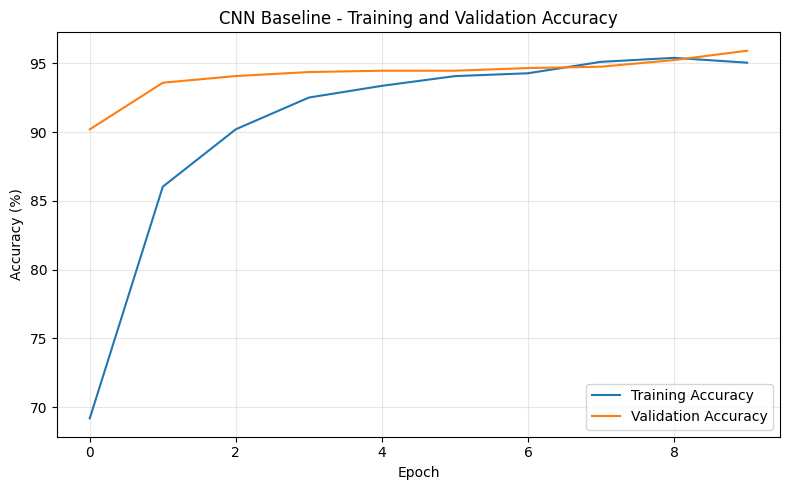

CNN loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_baseline_loss_curve.png
CNN accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_baseline_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 20: SAVE AND PLOT CNN TRAINING CURVES
# ============================================================

cnn_history_df = pd.DataFrame({
    "epoch": list(range(1, len(cnn_train_losses) + 1)),
    "train_loss": cnn_train_losses,
    "val_loss": cnn_val_losses,
    "train_accuracy": cnn_train_accuracies,
    "val_accuracy": cnn_val_accuracies
})

cnn_history_df.to_csv(cnn_history_path, index=False)

display(cnn_history_df)
print("CNN training history saved at:", cnn_history_path)

cnn_loss_curve_path = FIGURE_DIR / f"{CNN_MODEL_NAME}_loss_curve.png"
cnn_accuracy_curve_path = FIGURE_DIR / f"{CNN_MODEL_NAME}_accuracy_curve.png"

plt.figure(figsize=(8, 5))
plt.plot(cnn_train_losses, label="Training Loss")
plt.plot(cnn_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Baseline - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(cnn_loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(cnn_train_accuracies, label="Training Accuracy")
plt.plot(cnn_val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Baseline - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(cnn_accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("CNN loss curve saved at:", cnn_loss_curve_path)
print("CNN accuracy curve saved at:", cnn_accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 21: TEST CNN BASELINE MODEL
# ============================================================

if not cnn_best_model_path.exists():
    raise FileNotFoundError("Best CNN model not found. Please train the CNN model first.")

cnn_model.load_state_dict(torch.load(cnn_best_model_path, map_location=device))

cnn_test_loss, cnn_test_acc, cnn_test_preds, cnn_test_labels = validate_model(
    cnn_model,
    cnn_test_loader,
    cnn_criterion,
    device
)

print("CNN Test Loss:", round(cnn_test_loss, 4))
print("CNN Test Accuracy:", round(cnn_test_acc, 2), "%")

CNN Test Loss: 0.0689
CNN Test Accuracy: 96.32 %


Classification Report - CNN Baseline
                   precision    recall  f1-score   support

     complex_cyst       0.87      0.95      0.91       205
dominant_follicle       1.00      1.00      1.00       194
          healthy       1.00      1.00      1.00       220
        poly_cyst       1.00      1.00      1.00       214
      simple_cyst       0.94      0.86      0.90       199

         accuracy                           0.96      1032
        macro avg       0.96      0.96      0.96      1032
     weighted avg       0.96      0.96      0.96      1032

CNN classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_baseline_classification_report.txt


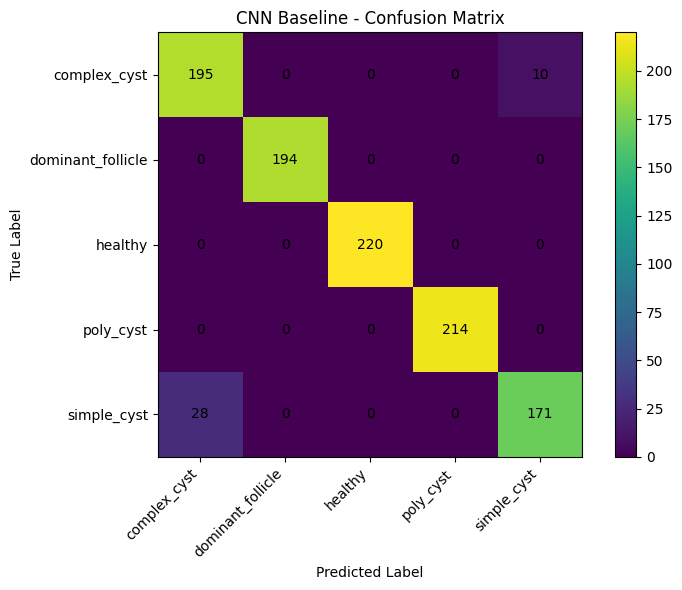

CNN confusion matrix saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_baseline_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 22: CNN CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - CNN Baseline")

cnn_report_text = classification_report(
    cnn_test_labels,
    cnn_test_preds,
    target_names=class_names,
    zero_division=0
)

print(cnn_report_text)

cnn_report_path = RESULT_DIR / f"{CNN_MODEL_NAME}_classification_report.txt"

with open(cnn_report_path, "w") as f:
    f.write(cnn_report_text)

print("CNN classification report saved at:", cnn_report_path)

# Confusion matrix
cnn_cm = confusion_matrix(cnn_test_labels, cnn_test_preds)

cnn_confusion_matrix_path = FIGURE_DIR / f"{CNN_MODEL_NAME}_confusion_matrix.png"

plt.figure(figsize=(8, 6))
plt.imshow(cnn_cm)
plt.title("CNN Baseline - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(ticks=np.arange(len(class_names)), labels=class_names, rotation=45, ha="right")
plt.yticks(ticks=np.arange(len(class_names)), labels=class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cnn_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(cnn_confusion_matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("CNN confusion matrix saved at:", cnn_confusion_matrix_path)

In [ ]:
# ============================================================
# CELL 23: SAVE CNN RESULT SUMMARY
# ============================================================

cnn_accuracy = accuracy_score(cnn_test_labels, cnn_test_preds)
cnn_precision = precision_score(cnn_test_labels, cnn_test_preds, average="weighted", zero_division=0)
cnn_recall = recall_score(cnn_test_labels, cnn_test_preds, average="weighted", zero_division=0)
cnn_f1 = f1_score(cnn_test_labels, cnn_test_preds, average="weighted", zero_division=0)

cnn_results = pd.DataFrame([{
    "Model": "CNN Baseline",
    "Image Size": f"{CNN_IMG_SIZE}x{CNN_IMG_SIZE}",
    "Test Accuracy": cnn_accuracy,
    "Precision": cnn_precision,
    "Recall": cnn_recall,
    "F1 Score": cnn_f1,
    "Best Validation Accuracy": cnn_best_val_acc / 100,
    "Total Parameters": cnn_total_params,
    "Trainable Parameters": cnn_trainable_params,
    "Epochs Completed": len(cnn_train_losses),
    "Batch Size": BATCH_SIZE
}])

cnn_results_path = RESULT_DIR / f"{CNN_MODEL_NAME}_results.csv"
cnn_results.to_csv(cnn_results_path, index=False)

display(cnn_results)

print("CNN results saved at:", cnn_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size
0,CNN Baseline,224x224,0.963178,0.964405,0.963178,0.96308,0.959263,1733125,1733125,10,32


CNN results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_baseline_results.csv


In [ ]:
# ============================================================
# CELL 25: SAVE CNN MODEL DETAILS FOR REPORT
# ============================================================

cnn_model_details = {
    "Model Name": "CNN Baseline",
    "Model Type": "Custom Convolutional Neural Network",
    "Input Image Size": f"{CNN_IMG_SIZE}x{CNN_IMG_SIZE}",
    "Input Shape": f"3 x {CNN_IMG_SIZE} x {CNN_IMG_SIZE}",
    "Number of Classes": len(class_names),
    "Classes": ", ".join(class_names),
    "Batch Size": BATCH_SIZE,
    "Epochs Completed": len(cnn_train_losses),
    "Optimizer": "Adam",
    "Loss Function": "CrossEntropyLoss",
    "Total Parameters": cnn_total_params,
    "Trainable Parameters": cnn_trainable_params,
    "Best Validation Accuracy": cnn_best_val_acc,
    "Best Model Path": str(cnn_best_model_path),
    "Checkpoint Path": str(cnn_checkpoint_path),
    "Training History Path": str(cnn_history_path),
    "Result Summary Path": str(cnn_results_path)
}

cnn_model_details_df = pd.DataFrame([cnn_model_details])

cnn_model_details_path = RESULT_DIR / f"{CNN_MODEL_NAME}_model_details.csv"
cnn_model_details_df.to_csv(cnn_model_details_path, index=False)

display(cnn_model_details_df)

print("CNN model details saved at:", cnn_model_details_path)

,Model Name,Model Type,Input Image Size,Input Shape,Number of Classes,Classes,Batch Size,Epochs Completed,Optimizer,Loss Function,Total Parameters,Trainable Parameters,Best Validation Accuracy,Best Model Path,Checkpoint Path,Training History Path,Result Summary Path
0,CNN Baseline,Custom Convolutional Neural Network,224x224,3 x 224 x 224,5,"complex_cyst, dominant_follicle, healthy, poly...",32,10,Adam,CrossEntropyLoss,1733125,1733125,95.926285,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...


CNN model details saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_baseline_model_details.csv


## CNN Deeper / CNN-2 Code

In [ ]:
# ============================================================
# CELL 26: CREATE CNN DEEPER DATALOADERS AND CHECK ONE BATCH
# ============================================================

CNN_DEEPER_MODEL_NAME = "cnn_deeper"

CNN_DEEPER_IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

cnn_deeper_train_loader, cnn_deeper_val_loader, cnn_deeper_test_loader = create_dataloaders(
    img_size=CNN_DEEPER_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("CNN Deeper DataLoaders created successfully.")
print("Training batches:", len(cnn_deeper_train_loader))
print("Validation batches:", len(cnn_deeper_val_loader))
print("Testing batches:", len(cnn_deeper_test_loader))

images, labels = next(iter(cnn_deeper_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

CNN Deeper DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([0, 2, 1, 1, 4, 1, 0, 2, 0, 3])


In [ ]:
# ============================================================
# CELL 27: DEFINE CNN DEEPER MODEL
# ============================================================

class CNNDeeper(nn.Module):
    def __init__(self, num_classes=5):
        super(CNNDeeper, self).__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 5
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2, stride=2),

            # Fixed output feature size
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(512 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_deeper_model = CNNDeeper(num_classes=NUM_CLASSES).to(device)

cnn_deeper_total_params = sum(p.numel() for p in cnn_deeper_model.parameters())
cnn_deeper_trainable_params = sum(p.numel() for p in cnn_deeper_model.parameters() if p.requires_grad)

print(cnn_deeper_model)
print("\nCNN Deeper Total parameters:", cnn_deeper_total_params)
print("CNN Deeper Trainable parameters:", cnn_deeper_trainable_params)

CNNDeeper(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU()
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1,

In [ ]:
# ============================================================
# CELL 28: CNN DEEPER LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

cnn_deeper_criterion = nn.CrossEntropyLoss()

cnn_deeper_optimizer = optim.Adam(
    cnn_deeper_model.parameters(),
    lr=0.0001
)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels


print("CNN Deeper loss, optimizer, training and validation functions ready.")

CNN Deeper loss, optimizer, training and validation functions ready.


In [ ]:
# ============================================================
# CELL 29: TRAIN CNN DEEPER WITH CHECKPOINT SAVE AND RESUME
# ============================================================

EPOCHS = 10 if torch.cuda.is_available() else 5

# Keep False normally.
# Set True only if you want to delete old CNN Deeper checkpoint and start again.
RESET_CNN_DEEPER_TRAINING = False

cnn_deeper_best_model_path = MODEL_DIR / f"{CNN_DEEPER_MODEL_NAME}_best.pth"
cnn_deeper_checkpoint_path = MODEL_DIR / f"{CNN_DEEPER_MODEL_NAME}_checkpoint.pth"
cnn_deeper_history_path = RESULT_DIR / f"{CNN_DEEPER_MODEL_NAME}_training_history.csv"

# ------------------------------------------------------------
# Optional reset
# ------------------------------------------------------------
if RESET_CNN_DEEPER_TRAINING:
    if cnn_deeper_checkpoint_path.exists():
        cnn_deeper_checkpoint_path.unlink()
        print("Old CNN Deeper checkpoint deleted.")

    if cnn_deeper_best_model_path.exists():
        cnn_deeper_best_model_path.unlink()
        print("Old CNN Deeper best model deleted.")

    if cnn_deeper_history_path.exists():
        cnn_deeper_history_path.unlink()
        print("Old CNN Deeper training history deleted.")

    print("Starting fresh CNN Deeper training.")

cnn_deeper_best_val_acc = 0.0
cnn_deeper_start_epoch = 0

cnn_deeper_train_losses = []
cnn_deeper_val_losses = []
cnn_deeper_train_accuracies = []
cnn_deeper_val_accuracies = []

# ------------------------------------------------------------
# Resume from checkpoint if available
# ------------------------------------------------------------
if cnn_deeper_checkpoint_path.exists():
    checkpoint = torch.load(cnn_deeper_checkpoint_path, map_location=device)

    cnn_deeper_model.load_state_dict(checkpoint["model_state_dict"])
    cnn_deeper_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    cnn_deeper_start_epoch = checkpoint["epoch"]
    cnn_deeper_best_val_acc = checkpoint["best_val_acc"]

    cnn_deeper_train_losses = checkpoint["train_losses"]
    cnn_deeper_val_losses = checkpoint["val_losses"]
    cnn_deeper_train_accuracies = checkpoint["train_accuracies"]
    cnn_deeper_val_accuracies = checkpoint["val_accuracies"]

    print("CNN Deeper checkpoint found.")
    print("Resuming from epoch:", cnn_deeper_start_epoch)
    print("Best validation accuracy so far:", cnn_deeper_best_val_acc)
else:
    print("No CNN Deeper checkpoint found. Starting fresh.")

print("\nStarting CNN Deeper training...")
print("Epochs:", EPOCHS)
print("Device:", device)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
if cnn_deeper_start_epoch >= EPOCHS:
    print("CNN Deeper training already completed for the selected number of epochs.")
else:
    for epoch in range(cnn_deeper_start_epoch, EPOCHS):

        train_loss, train_acc = train_one_epoch(
            cnn_deeper_model,
            cnn_deeper_train_loader,
            cnn_deeper_criterion,
            cnn_deeper_optimizer,
            device
        )

        val_loss, val_acc, _, _ = validate_model(
            cnn_deeper_model,
            cnn_deeper_val_loader,
            cnn_deeper_criterion,
            device
        )

        cnn_deeper_train_losses.append(train_loss)
        cnn_deeper_val_losses.append(val_loss)
        cnn_deeper_train_accuracies.append(train_acc)
        cnn_deeper_val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        # Save best model
        if val_acc > cnn_deeper_best_val_acc:
            cnn_deeper_best_val_acc = val_acc
            torch.save(cnn_deeper_model.state_dict(), cnn_deeper_best_model_path)

            print("Best CNN Deeper model saved.")
            print("Best Validation Accuracy:", cnn_deeper_best_val_acc)

        # Save checkpoint every epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": cnn_deeper_model.state_dict(),
            "optimizer_state_dict": cnn_deeper_optimizer.state_dict(),
            "best_val_acc": cnn_deeper_best_val_acc,
            "train_losses": cnn_deeper_train_losses,
            "val_losses": cnn_deeper_val_losses,
            "train_accuracies": cnn_deeper_train_accuracies,
            "val_accuracies": cnn_deeper_val_accuracies,
            "img_size": CNN_DEEPER_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx
        }, cnn_deeper_checkpoint_path)

        # Save training history every epoch
        cnn_deeper_history_df = pd.DataFrame({
            "epoch": list(range(1, len(cnn_deeper_train_losses) + 1)),
            "train_loss": cnn_deeper_train_losses,
            "val_loss": cnn_deeper_val_losses,
            "train_accuracy": cnn_deeper_train_accuracies,
            "val_accuracy": cnn_deeper_val_accuracies
        })

        cnn_deeper_history_df.to_csv(cnn_deeper_history_path, index=False)

        print("CNN Deeper checkpoint saved:", cnn_deeper_checkpoint_path)
        print("CNN Deeper training history saved:", cnn_deeper_history_path)
        print("-" * 50)

print("\nCNN Deeper training completed.")
print("Best validation accuracy:", cnn_deeper_best_val_acc)
print("Best model path:", cnn_deeper_best_model_path)
print("Checkpoint path:", cnn_deeper_checkpoint_path)
print("Training history path:", cnn_deeper_history_path)

CNN Deeper checkpoint found.
Resuming from epoch: 2
Best validation accuracy so far: 92.82250242483026

Starting CNN Deeper training...
Epochs: 10
Device: cuda
Epoch [3/10]
Train Loss: 0.1392 | Train Acc: 95.22%
Val Loss:   0.0800 | Val Acc:   96.41%
Best CNN Deeper model saved.
Best Validation Accuracy: 96.41125121241514
CNN Deeper checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/cnn_deeper_checkpoint.pth
CNN Deeper training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_training_history.csv
--------------------------------------------------
Epoch [4/10]
Train Loss: 0.1004 | Train Acc: 96.72%
Val Loss:   1.6645 | Val Acc:   76.43%
CNN Deeper checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/cnn_deeper_checkpoint.pth
CNN Deeper training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_training_history.csv
--------------------------------------------------
Epoch [5/10]
Trai

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.518327,0.199499,79.763141,92.822502
1,2,0.181680,0.392471,93.517557,86.614937
2,3,0.139183,0.080018,95.221276,96.411251
3,4,0.100397,1.664494,96.717224,76.430650
4,5,0.072450,0.041966,97.527530,98.448109
5,6,0.039631,0.036540,98.628714,98.254122
6,7,0.032805,0.623652,98.878039,89.039767
7,8,0.032712,0.099029,98.815707,97.381183
8,9,0.025544,0.042040,99.168918,98.157129
9,10,0.019634,0.006215,99.272803,99.806014


CNN Deeper training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_training_history.csv


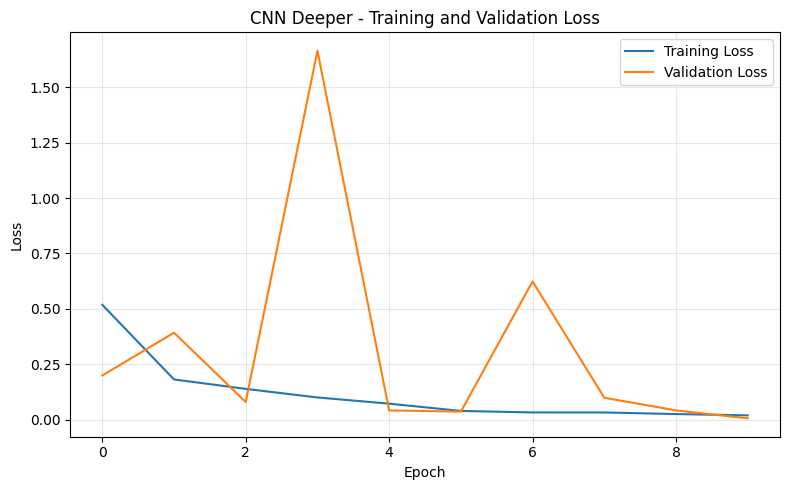

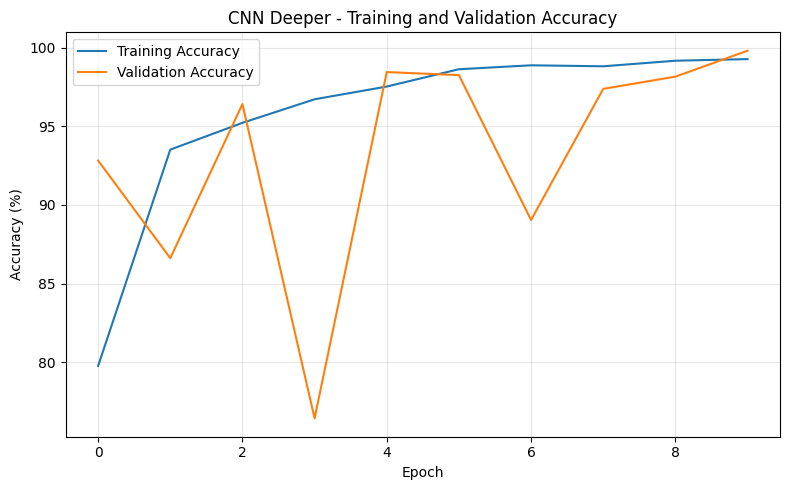

CNN Deeper loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_deeper_loss_curve.png
CNN Deeper accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_deeper_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 30: SAVE AND PLOT CNN DEEPER TRAINING CURVES
# ============================================================

cnn_deeper_history_df = pd.DataFrame({
    "epoch": list(range(1, len(cnn_deeper_train_losses) + 1)),
    "train_loss": cnn_deeper_train_losses,
    "val_loss": cnn_deeper_val_losses,
    "train_accuracy": cnn_deeper_train_accuracies,
    "val_accuracy": cnn_deeper_val_accuracies
})

cnn_deeper_history_df.to_csv(cnn_deeper_history_path, index=False)

display(cnn_deeper_history_df)

print("CNN Deeper training history saved at:", cnn_deeper_history_path)

cnn_deeper_loss_curve_path = FIGURE_DIR / f"{CNN_DEEPER_MODEL_NAME}_loss_curve.png"
cnn_deeper_accuracy_curve_path = FIGURE_DIR / f"{CNN_DEEPER_MODEL_NAME}_accuracy_curve.png"

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(cnn_deeper_train_losses, label="Training Loss")
plt.plot(cnn_deeper_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Deeper - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(cnn_deeper_loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(cnn_deeper_train_accuracies, label="Training Accuracy")
plt.plot(cnn_deeper_val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Deeper - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(cnn_deeper_accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("CNN Deeper loss curve saved at:", cnn_deeper_loss_curve_path)
print("CNN Deeper accuracy curve saved at:", cnn_deeper_accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 31: TEST CNN DEEPER MODEL
# ============================================================

if not cnn_deeper_best_model_path.exists():
    raise FileNotFoundError("Best CNN Deeper model not found. Please train the CNN Deeper model first.")

cnn_deeper_model.load_state_dict(
    torch.load(cnn_deeper_best_model_path, map_location=device)
)

cnn_deeper_test_loss, cnn_deeper_test_acc, cnn_deeper_test_preds, cnn_deeper_test_labels = validate_model(
    cnn_deeper_model,
    cnn_deeper_test_loader,
    cnn_deeper_criterion,
    device
)

print("CNN Deeper Test Loss:", round(cnn_deeper_test_loss, 4))
print("CNN Deeper Test Accuracy:", round(cnn_deeper_test_acc, 2), "%")

CNN Deeper Test Loss: 0.0065
CNN Deeper Test Accuracy: 99.9 %


Classification Report - CNN Deeper
                   precision    recall  f1-score   support

     complex_cyst       1.00      1.00      1.00       205
dominant_follicle       1.00      1.00      1.00       194
          healthy       1.00      1.00      1.00       220
        poly_cyst       1.00      1.00      1.00       214
      simple_cyst       1.00      0.99      1.00       199

         accuracy                           1.00      1032
        macro avg       1.00      1.00      1.00      1032
     weighted avg       1.00      1.00      1.00      1032

CNN Deeper classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_classification_report.txt


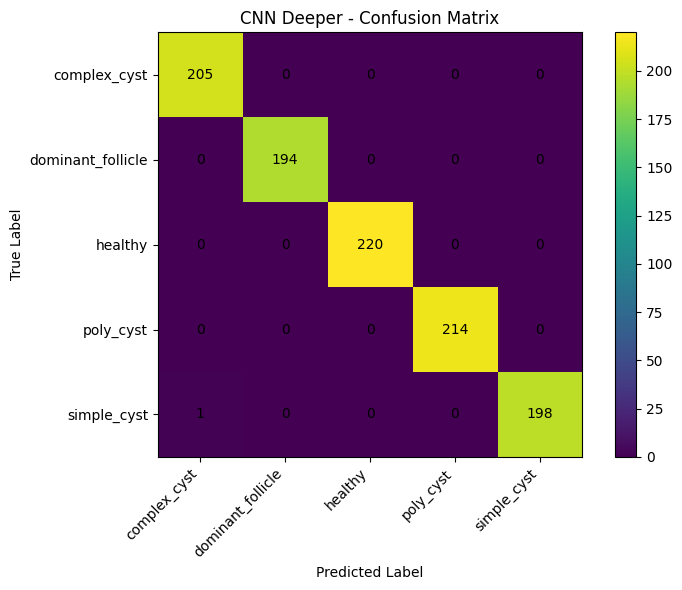

CNN Deeper confusion matrix saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_deeper_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 32: CNN DEEPER CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - CNN Deeper")

cnn_deeper_report_text = classification_report(
    cnn_deeper_test_labels,
    cnn_deeper_test_preds,
    target_names=class_names,
    zero_division=0
)

print(cnn_deeper_report_text)

cnn_deeper_report_path = RESULT_DIR / f"{CNN_DEEPER_MODEL_NAME}_classification_report.txt"

with open(cnn_deeper_report_path, "w") as f:
    f.write("Classification Report - CNN Deeper\n")
    f.write(cnn_deeper_report_text)

print("CNN Deeper classification report saved at:", cnn_deeper_report_path)

# Confusion matrix
cnn_deeper_cm = confusion_matrix(
    cnn_deeper_test_labels,
    cnn_deeper_test_preds
)

cnn_deeper_confusion_matrix_path = FIGURE_DIR / f"{CNN_DEEPER_MODEL_NAME}_confusion_matrix.png"

plt.figure(figsize=(8, 6))
plt.imshow(cnn_deeper_cm)
plt.title("CNN Deeper - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(
    ticks=np.arange(len(class_names)),
    labels=class_names,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(class_names)),
    labels=class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cnn_deeper_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(cnn_deeper_confusion_matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("CNN Deeper confusion matrix saved at:", cnn_deeper_confusion_matrix_path)

In [ ]:
# ============================================================
# CELL 33: SAVE CNN DEEPER RESULT SUMMARY
# ============================================================

cnn_deeper_accuracy = accuracy_score(
    cnn_deeper_test_labels,
    cnn_deeper_test_preds
)

cnn_deeper_precision = precision_score(
    cnn_deeper_test_labels,
    cnn_deeper_test_preds,
    average="weighted",
    zero_division=0
)

cnn_deeper_recall = recall_score(
    cnn_deeper_test_labels,
    cnn_deeper_test_preds,
    average="weighted",
    zero_division=0
)

cnn_deeper_f1 = f1_score(
    cnn_deeper_test_labels,
    cnn_deeper_test_preds,
    average="weighted",
    zero_division=0
)

cnn_deeper_results = pd.DataFrame([{
    "Model": "CNN Deeper",
    "Image Size": f"{CNN_DEEPER_IMG_SIZE}x{CNN_DEEPER_IMG_SIZE}",
    "Test Accuracy": cnn_deeper_accuracy,
    "Precision": cnn_deeper_precision,
    "Recall": cnn_deeper_recall,
    "F1 Score": cnn_deeper_f1,
    "Best Validation Accuracy": cnn_deeper_best_val_acc / 100,
    "Total Parameters": cnn_deeper_total_params,
    "Trainable Parameters": cnn_deeper_trainable_params,
    "Epochs Completed": len(cnn_deeper_train_losses),
    "Batch Size": BATCH_SIZE
}])

cnn_deeper_results_path = RESULT_DIR / f"{CNN_DEEPER_MODEL_NAME}_results.csv"

cnn_deeper_results.to_csv(cnn_deeper_results_path, index=False)

display(cnn_deeper_results)

print("CNN Deeper results saved at:", cnn_deeper_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size
0,CNN Deeper,224x224,0.999031,0.999036,0.999031,0.999031,0.99806,6682789,6682789,10,32


CNN Deeper results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_results.csv


In [ ]:
# ============================================================
# CELL 34: VERIFY ALL CNN DEEPER FILES SAVED IN GOOGLE DRIVE
# ============================================================

files_to_check = {
    "CNN Deeper best model": MODEL_DIR / f"{CNN_DEEPER_MODEL_NAME}_best.pth",
    "CNN Deeper checkpoint": MODEL_DIR / f"{CNN_DEEPER_MODEL_NAME}_checkpoint.pth",
    "CNN Deeper training history": RESULT_DIR / f"{CNN_DEEPER_MODEL_NAME}_training_history.csv",
    "CNN Deeper result summary": RESULT_DIR / f"{CNN_DEEPER_MODEL_NAME}_results.csv",
    "CNN Deeper classification report": RESULT_DIR / f"{CNN_DEEPER_MODEL_NAME}_classification_report.txt",
    "CNN Deeper loss curve": FIGURE_DIR / f"{CNN_DEEPER_MODEL_NAME}_loss_curve.png",
    "CNN Deeper accuracy curve": FIGURE_DIR / f"{CNN_DEEPER_MODEL_NAME}_accuracy_curve.png",
    "CNN Deeper confusion matrix": FIGURE_DIR / f"{CNN_DEEPER_MODEL_NAME}_confusion_matrix.png",
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

CNN Deeper best model: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/cnn_deeper_best.pth
CNN Deeper checkpoint: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/cnn_deeper_checkpoint.pth
CNN Deeper training history: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_training_history.csv
CNN Deeper result summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_results.csv
CNN Deeper classification report: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_classification_report.txt
CNN Deeper loss curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_deeper_loss_curve.png
CNN Deeper accuracy curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_deeper_accuracy_curve.png
CNN Deeper confusion matrix: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/cnn_deeper_confusion_matrix.png


# **LENET 5 MODEL CNN CODE**

In [ ]:
# ============================================================
# CELL 36: CREATE LENET DATALOADERS AND CHECK ONE BATCH
# ============================================================

LENET_MODEL_NAME = "lenet"

LENET_IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

lenet_train_loader, lenet_val_loader, lenet_test_loader = create_dataloaders(
    img_size=LENET_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("LeNet DataLoaders created successfully.")
print("Training batches:", len(lenet_train_loader))
print("Validation batches:", len(lenet_val_loader))
print("Testing batches:", len(lenet_test_loader))

images, labels = next(iter(lenet_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

LeNet DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([0, 2, 1, 1, 4, 1, 0, 2, 0, 3])


In [ ]:
# ============================================================
# CELL 37: DEFINE LENET MODEL
# ============================================================

class LeNet(nn.Module):
    def __init__(self, num_classes=5):
        super(LeNet, self).__init__()

        self.features = nn.Sequential(
            # Convolution Block 1
            nn.Conv2d(3, 6, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            # Convolution Block 2
            nn.Conv2d(6, 16, kernel_size=5),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),

            # This keeps the classic LeNet classifier size stable
            nn.AdaptiveAvgPool2d((5, 5))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(16 * 5 * 5, 120),
            nn.Tanh(),

            nn.Linear(120, 84),
            nn.Tanh(),

            nn.Linear(84, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


lenet_model = LeNet(num_classes=NUM_CLASSES).to(device)

lenet_total_params = sum(p.numel() for p in lenet_model.parameters())
lenet_trainable_params = sum(p.numel() for p in lenet_model.parameters() if p.requires_grad)

print(lenet_model)
print("\nLeNet Total parameters:", lenet_total_params)
print("LeNet Trainable parameters:", lenet_trainable_params)

LeNet(
  (features): Sequential(
    (0): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): AdaptiveAvgPool2d(output_size=(5, 5))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): Tanh()
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): Tanh()
    (5): Linear(in_features=84, out_features=5, bias=True)
  )
)

LeNet Total parameters: 61581
LeNet Trainable parameters: 61581


In [ ]:
# ============================================================
# CELL 38: LENET LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

lenet_criterion = nn.CrossEntropyLoss()

lenet_optimizer = optim.Adam(
    lenet_model.parameters(),
    lr=0.0001
)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels


print("LeNet loss, optimizer, training and validation functions ready.")

LeNet loss, optimizer, training and validation functions ready.


In [ ]:
# ============================================================
# CELL 39: TRAIN LENET WITH CHECKPOINT SAVE AND RESUME
# ============================================================

EPOCHS = 10 if torch.cuda.is_available() else 5

# Keep False normally.
# Set True only if you want to delete old LeNet checkpoint and start again.
RESET_LENET_TRAINING = False

lenet_best_model_path = MODEL_DIR / f"{LENET_MODEL_NAME}_best.pth"
lenet_checkpoint_path = MODEL_DIR / f"{LENET_MODEL_NAME}_checkpoint.pth"
lenet_history_path = RESULT_DIR / f"{LENET_MODEL_NAME}_training_history.csv"

# ------------------------------------------------------------
# Optional reset
# ------------------------------------------------------------
if RESET_LENET_TRAINING:
    if lenet_checkpoint_path.exists():
        lenet_checkpoint_path.unlink()
        print("Old LeNet checkpoint deleted.")

    if lenet_best_model_path.exists():
        lenet_best_model_path.unlink()
        print("Old LeNet best model deleted.")

    if lenet_history_path.exists():
        lenet_history_path.unlink()
        print("Old LeNet training history deleted.")

    print("Starting fresh LeNet training.")

lenet_best_val_acc = 0.0
lenet_start_epoch = 0

lenet_train_losses = []
lenet_val_losses = []
lenet_train_accuracies = []
lenet_val_accuracies = []

# ------------------------------------------------------------
# Resume from checkpoint if available
# ------------------------------------------------------------
if lenet_checkpoint_path.exists():
    checkpoint = torch.load(lenet_checkpoint_path, map_location=device)

    lenet_model.load_state_dict(checkpoint["model_state_dict"])
    lenet_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    lenet_start_epoch = checkpoint["epoch"]
    lenet_best_val_acc = checkpoint["best_val_acc"]

    lenet_train_losses = checkpoint["train_losses"]
    lenet_val_losses = checkpoint["val_losses"]
    lenet_train_accuracies = checkpoint["train_accuracies"]
    lenet_val_accuracies = checkpoint["val_accuracies"]

    print("LeNet checkpoint found.")
    print("Resuming from epoch:", lenet_start_epoch)
    print("Best validation accuracy so far:", lenet_best_val_acc)
else:
    print("No LeNet checkpoint found. Starting fresh.")

print("\nStarting LeNet training...")
print("Epochs:", EPOCHS)
print("Device:", device)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
if lenet_start_epoch >= EPOCHS:
    print("LeNet training already completed for the selected number of epochs.")
else:
    for epoch in range(lenet_start_epoch, EPOCHS):

        train_loss, train_acc = train_one_epoch(
            lenet_model,
            lenet_train_loader,
            lenet_criterion,
            lenet_optimizer,
            device
        )

        val_loss, val_acc, _, _ = validate_model(
            lenet_model,
            lenet_val_loader,
            lenet_criterion,
            device
        )

        lenet_train_losses.append(train_loss)
        lenet_val_losses.append(val_loss)
        lenet_train_accuracies.append(train_acc)
        lenet_val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        # Save best model
        if val_acc > lenet_best_val_acc:
            lenet_best_val_acc = val_acc
            torch.save(lenet_model.state_dict(), lenet_best_model_path)

            print("Best LeNet model saved.")
            print("Best Validation Accuracy:", lenet_best_val_acc)

        # Save checkpoint every epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": lenet_model.state_dict(),
            "optimizer_state_dict": lenet_optimizer.state_dict(),
            "best_val_acc": lenet_best_val_acc,
            "train_losses": lenet_train_losses,
            "val_losses": lenet_val_losses,
            "train_accuracies": lenet_train_accuracies,
            "val_accuracies": lenet_val_accuracies,
            "img_size": LENET_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx
        }, lenet_checkpoint_path)

        # Save training history every epoch
        lenet_history_df = pd.DataFrame({
            "epoch": list(range(1, len(lenet_train_losses) + 1)),
            "train_loss": lenet_train_losses,
            "val_loss": lenet_val_losses,
            "train_accuracy": lenet_train_accuracies,
            "val_accuracy": lenet_val_accuracies
        })

        lenet_history_df.to_csv(lenet_history_path, index=False)

        print("LeNet checkpoint saved:", lenet_checkpoint_path)
        print("LeNet training history saved:", lenet_history_path)
        print("-" * 50)

print("\nLeNet training completed.")
print("Best validation accuracy:", lenet_best_val_acc)
print("Best model path:", lenet_best_model_path)
print("Checkpoint path:", lenet_checkpoint_path)
print("Training history path:", lenet_history_path)

No LeNet checkpoint found. Starting fresh.

Starting LeNet training...
Epochs: 10
Device: cuda
Epoch [1/10]
Train Loss: 1.4587 | Train Acc: 41.93%
Val Loss:   1.1773 | Val Acc:   57.71%
Best LeNet model saved.
Best Validation Accuracy: 57.710960232783705
LeNet checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/lenet_checkpoint.pth
LeNet training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_training_history.csv
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.9381 | Train Acc: 61.08%
Val Loss:   0.7866 | Val Acc:   65.57%
Best LeNet model saved.
Best Validation Accuracy: 65.56741028128032
LeNet checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/lenet_checkpoint.pth
LeNet training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_training_history.csv
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.7040 | Train Acc: 70.14%
Val Lo

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,1.458743,1.177310,41.928111,57.710960
1,2,0.938096,0.786607,61.084563,65.567410
2,3,0.703985,0.625365,70.143362,73.423860
3,4,0.582906,0.551876,74.776647,75.169738
4,5,0.527607,0.487331,77.124455,78.370514
5,6,0.486707,0.458623,78.391855,78.758487
6,7,0.456268,0.497581,79.264492,76.915616
7,8,0.436783,0.409688,79.555371,79.825412
8,9,0.420719,0.409247,80.116352,80.116392
9,10,0.404111,0.386811,80.303345,81.086324


LeNet training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_training_history.csv


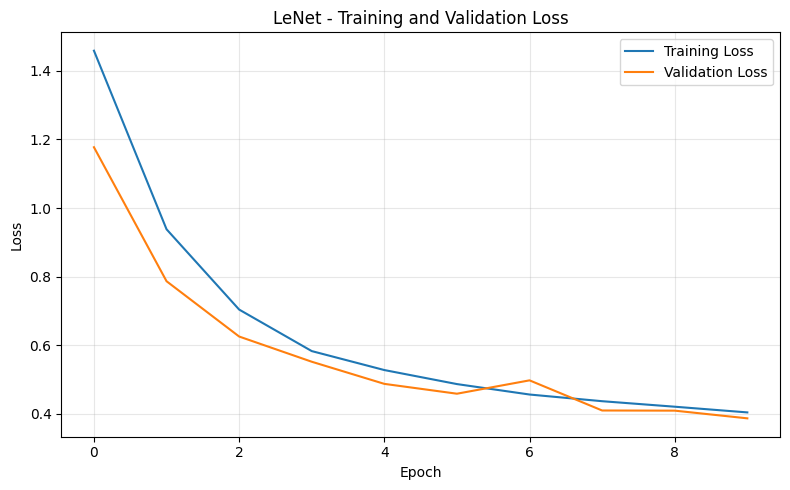

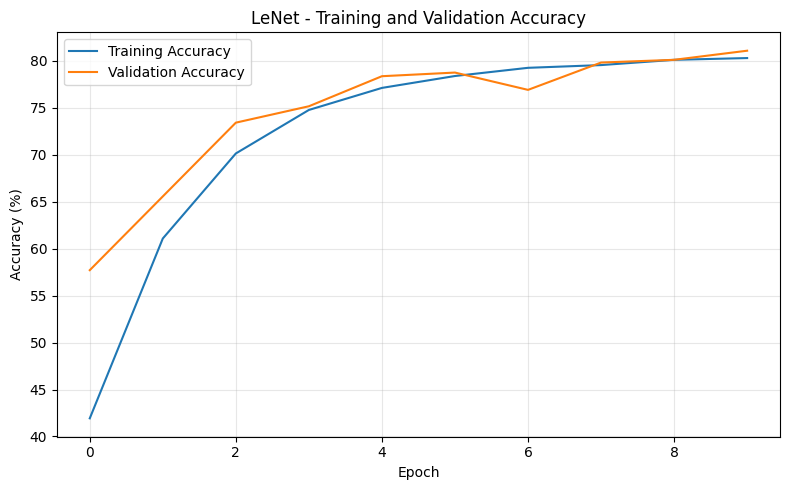

LeNet loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/lenet_loss_curve.png
LeNet accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/lenet_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 40: SAVE AND PLOT LENET TRAINING CURVES
# ============================================================

lenet_history_df = pd.DataFrame({
    "epoch": list(range(1, len(lenet_train_losses) + 1)),
    "train_loss": lenet_train_losses,
    "val_loss": lenet_val_losses,
    "train_accuracy": lenet_train_accuracies,
    "val_accuracy": lenet_val_accuracies
})

lenet_history_df.to_csv(lenet_history_path, index=False)

display(lenet_history_df)

print("LeNet training history saved at:", lenet_history_path)

lenet_loss_curve_path = FIGURE_DIR / f"{LENET_MODEL_NAME}_loss_curve.png"
lenet_accuracy_curve_path = FIGURE_DIR / f"{LENET_MODEL_NAME}_accuracy_curve.png"

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(lenet_train_losses, label="Training Loss")
plt.plot(lenet_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LeNet - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(lenet_loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(lenet_train_accuracies, label="Training Accuracy")
plt.plot(lenet_val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("LeNet - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(lenet_accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("LeNet loss curve saved at:", lenet_loss_curve_path)
print("LeNet accuracy curve saved at:", lenet_accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 41: TEST LENET MODEL
# ============================================================

if not lenet_best_model_path.exists():
    raise FileNotFoundError("Best LeNet model not found. Please train the LeNet model first.")

lenet_model.load_state_dict(
    torch.load(lenet_best_model_path, map_location=device)
)

lenet_test_loss, lenet_test_acc, lenet_test_preds, lenet_test_labels = validate_model(
    lenet_model,
    lenet_test_loader,
    lenet_criterion,
    device
)

print("LeNet Test Loss:", round(lenet_test_loss, 4))
print("LeNet Test Accuracy:", round(lenet_test_acc, 2), "%")

LeNet Test Loss: 0.3854
LeNet Test Accuracy: 81.4 %


Classification Report - LeNet
                   precision    recall  f1-score   support

     complex_cyst       0.56      0.76      0.65       205
dominant_follicle       0.88      0.95      0.92       194
          healthy       1.00      0.99      0.99       220
        poly_cyst       0.98      0.99      0.98       214
      simple_cyst       0.63      0.36      0.46       199

         accuracy                           0.81      1032
        macro avg       0.81      0.81      0.80      1032
     weighted avg       0.82      0.81      0.80      1032

LeNet classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_classification_report.txt


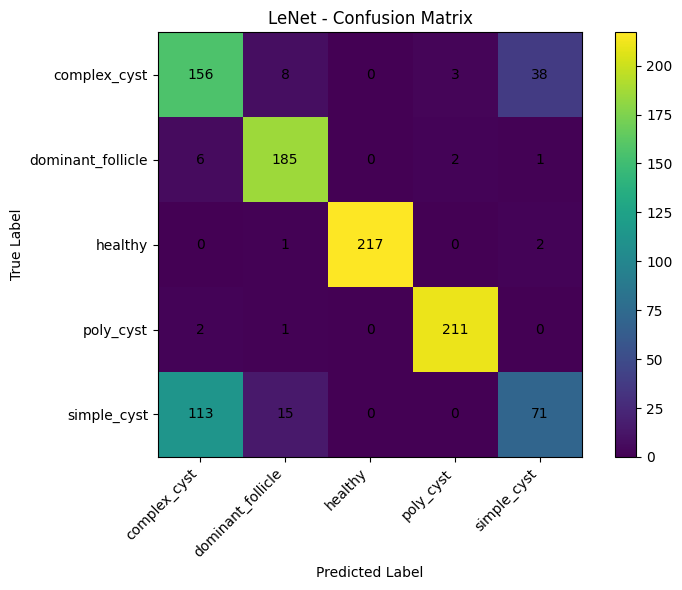

LeNet confusion matrix saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/lenet_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 42: LENET CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - LeNet")

lenet_report_text = classification_report(
    lenet_test_labels,
    lenet_test_preds,
    target_names=class_names,
    zero_division=0
)

print(lenet_report_text)

lenet_report_path = RESULT_DIR / f"{LENET_MODEL_NAME}_classification_report.txt"

with open(lenet_report_path, "w") as f:
    f.write("Classification Report - LeNet\n")
    f.write(lenet_report_text)

print("LeNet classification report saved at:", lenet_report_path)

# Confusion matrix
lenet_cm = confusion_matrix(
    lenet_test_labels,
    lenet_test_preds
)

lenet_confusion_matrix_path = FIGURE_DIR / f"{LENET_MODEL_NAME}_confusion_matrix.png"

plt.figure(figsize=(8, 6))
plt.imshow(lenet_cm)
plt.title("LeNet - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(
    ticks=np.arange(len(class_names)),
    labels=class_names,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(class_names)),
    labels=class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, lenet_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(lenet_confusion_matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("LeNet confusion matrix saved at:", lenet_confusion_matrix_path)

In [ ]:
# ============================================================
# CELL 43: SAVE LENET RESULT SUMMARY
# ============================================================

lenet_accuracy = accuracy_score(
    lenet_test_labels,
    lenet_test_preds
)

lenet_precision = precision_score(
    lenet_test_labels,
    lenet_test_preds,
    average="weighted",
    zero_division=0
)

lenet_recall = recall_score(
    lenet_test_labels,
    lenet_test_preds,
    average="weighted",
    zero_division=0
)

lenet_f1 = f1_score(
    lenet_test_labels,
    lenet_test_preds,
    average="weighted",
    zero_division=0
)

lenet_results = pd.DataFrame([{
    "Model": "LeNet",
    "Image Size": f"{LENET_IMG_SIZE}x{LENET_IMG_SIZE}",
    "Test Accuracy": lenet_accuracy,
    "Precision": lenet_precision,
    "Recall": lenet_recall,
    "F1 Score": lenet_f1,
    "Best Validation Accuracy": lenet_best_val_acc / 100,
    "Total Parameters": lenet_total_params,
    "Trainable Parameters": lenet_trainable_params,
    "Epochs Completed": len(lenet_train_losses),
    "Batch Size": BATCH_SIZE
}])

lenet_results_path = RESULT_DIR / f"{LENET_MODEL_NAME}_results.csv"

lenet_results.to_csv(lenet_results_path, index=False)

display(lenet_results)

print("LeNet results saved at:", lenet_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size
0,LeNet,224x224,0.813953,0.815459,0.813953,0.804012,0.810863,61581,61581,10,32


LeNet results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_results.csv


In [ ]:
# ============================================================
# CELL 44: VERIFY ALL LENET FILES SAVED IN GOOGLE DRIVE
# ============================================================

files_to_check = {
    "LeNet best model": MODEL_DIR / f"{LENET_MODEL_NAME}_best.pth",
    "LeNet checkpoint": MODEL_DIR / f"{LENET_MODEL_NAME}_checkpoint.pth",
    "LeNet training history": RESULT_DIR / f"{LENET_MODEL_NAME}_training_history.csv",
    "LeNet result summary": RESULT_DIR / f"{LENET_MODEL_NAME}_results.csv",
    "LeNet classification report": RESULT_DIR / f"{LENET_MODEL_NAME}_classification_report.txt",
    "LeNet loss curve": FIGURE_DIR / f"{LENET_MODEL_NAME}_loss_curve.png",
    "LeNet accuracy curve": FIGURE_DIR / f"{LENET_MODEL_NAME}_accuracy_curve.png",
    "LeNet confusion matrix": FIGURE_DIR / f"{LENET_MODEL_NAME}_confusion_matrix.png",
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

LeNet best model: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/lenet_best.pth
LeNet checkpoint: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/lenet_checkpoint.pth
LeNet training history: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_training_history.csv
LeNet result summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_results.csv
LeNet classification report: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_classification_report.txt
LeNet loss curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/lenet_loss_curve.png
LeNet accuracy curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/lenet_accuracy_curve.png
LeNet confusion matrix: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/lenet_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 45: SAVE LENET MODEL DETAILS FOR REPORT
# ============================================================

lenet_model_details = {
    "Model Name": "LeNet",
    "Model Type": "Classic CNN Architecture / Adapted LeNet-5",
    "Input Image Size": f"{LENET_IMG_SIZE}x{LENET_IMG_SIZE}",
    "Input Shape": f"3 x {LENET_IMG_SIZE} x {LENET_IMG_SIZE}",
    "Number of Classes": len(class_names),
    "Classes": ", ".join(class_names),
    "Batch Size": BATCH_SIZE,
    "Epochs Completed": len(lenet_train_losses),
    "Optimizer": "Adam",
    "Loss Function": "CrossEntropyLoss",
    "Total Parameters": lenet_total_params,
    "Trainable Parameters": lenet_trainable_params,
    "Best Validation Accuracy": lenet_best_val_acc,
    "Best Model Path": str(lenet_best_model_path),
    "Checkpoint Path": str(lenet_checkpoint_path),
    "Training History Path": str(lenet_history_path),
    "Result Summary Path": str(lenet_results_path)
}

lenet_model_details_df = pd.DataFrame([lenet_model_details])

lenet_model_details_path = RESULT_DIR / f"{LENET_MODEL_NAME}_model_details.csv"

lenet_model_details_df.to_csv(
    lenet_model_details_path,
    index=False
)

display(lenet_model_details_df)

print("LeNet model details saved at:", lenet_model_details_path)

,Model Name,Model Type,Input Image Size,Input Shape,Number of Classes,Classes,Batch Size,Epochs Completed,Optimizer,Loss Function,Total Parameters,Trainable Parameters,Best Validation Accuracy,Best Model Path,Checkpoint Path,Training History Path,Result Summary Path
0,LeNet,Classic CNN Architecture / Adapted LeNet-5,224x224,3 x 224 x 224,5,"complex_cyst, dominant_follicle, healthy, poly...",32,10,Adam,CrossEntropyLoss,61581,61581,81.086324,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...


LeNet model details saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_model_details.csv


# **VGG 16 CNN CODE**

In [ ]:
# ============================================================
# CELL 46: CREATE VGG16 DATALOADERS AND CHECK ONE BATCH
# ============================================================

VGG16_MODEL_NAME = "vgg16"

VGG16_IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

vgg16_train_loader, vgg16_val_loader, vgg16_test_loader = create_dataloaders(
    img_size=VGG16_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("VGG16 DataLoaders created successfully.")
print("Training batches:", len(vgg16_train_loader))
print("Validation batches:", len(vgg16_val_loader))
print("Testing batches:", len(vgg16_test_loader))

images, labels = next(iter(vgg16_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

VGG16 DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([0, 2, 1, 1, 4, 1, 0, 2, 0, 3])


In [ ]:
# ============================================================
# CELL 47: DEFINE VGG16 TRANSFER LEARNING MODEL
# ============================================================

from torchvision import models

# Load pretrained VGG16 model
try:
    vgg16_weights = models.VGG16_Weights.DEFAULT
    vgg16_model = models.vgg16(weights=vgg16_weights)
    print("Pretrained VGG16 weights loaded successfully.")
except Exception as e:
    print("Pretrained weights could not be loaded. Using VGG16 without pretrained weights.")
    print("Reason:", e)
    vgg16_model = models.vgg16(weights=None)

# Freeze convolutional feature extractor for faster transfer learning
for param in vgg16_model.features.parameters():
    param.requires_grad = False

# Replace final classification layer for 5 ovarian classes
in_features = vgg16_model.classifier[6].in_features
vgg16_model.classifier[6] = nn.Linear(in_features, NUM_CLASSES)

vgg16_model = vgg16_model.to(device)

vgg16_total_params = sum(p.numel() for p in vgg16_model.parameters())
vgg16_trainable_params = sum(p.numel() for p in vgg16_model.parameters() if p.requires_grad)

print(vgg16_model)
print("\nVGG16 Total parameters:", vgg16_total_params)
print("VGG16 Trainable parameters:", vgg16_trainable_params)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 102MB/s]


Pretrained VGG16 weights loaded successfully.
VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(

In [ ]:
# ============================================================
# CELL 48: VGG16 LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

vgg16_criterion = nn.CrossEntropyLoss()

vgg16_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, vgg16_model.parameters()),
    lr=0.0001
)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels


print("VGG16 loss, optimizer, training and validation functions ready.")

VGG16 loss, optimizer, training and validation functions ready.


In [ ]:
# ============================================================
# CELL 49: TRAIN VGG16 WITH CHECKPOINT SAVE AND RESUME
# ============================================================

EPOCHS = 10 if torch.cuda.is_available() else 5

# Keep False normally.
# Set True only if you want to delete old VGG16 checkpoint and start again.
RESET_VGG16_TRAINING = False

vgg16_best_model_path = MODEL_DIR / f"{VGG16_MODEL_NAME}_best.pth"
vgg16_checkpoint_path = MODEL_DIR / f"{VGG16_MODEL_NAME}_checkpoint.pth"
vgg16_history_path = RESULT_DIR / f"{VGG16_MODEL_NAME}_training_history.csv"

# ------------------------------------------------------------
# Optional reset
# ------------------------------------------------------------
if RESET_VGG16_TRAINING:
    if vgg16_checkpoint_path.exists():
        vgg16_checkpoint_path.unlink()
        print("Old VGG16 checkpoint deleted.")

    if vgg16_best_model_path.exists():
        vgg16_best_model_path.unlink()
        print("Old VGG16 best model deleted.")

    if vgg16_history_path.exists():
        vgg16_history_path.unlink()
        print("Old VGG16 training history deleted.")

    print("Starting fresh VGG16 training.")

vgg16_best_val_acc = 0.0
vgg16_start_epoch = 0

vgg16_train_losses = []
vgg16_val_losses = []
vgg16_train_accuracies = []
vgg16_val_accuracies = []

# ------------------------------------------------------------
# Resume from checkpoint if available
# ------------------------------------------------------------
if vgg16_checkpoint_path.exists():
    checkpoint = torch.load(vgg16_checkpoint_path, map_location=device)

    vgg16_model.load_state_dict(checkpoint["model_state_dict"])
    vgg16_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    vgg16_start_epoch = checkpoint["epoch"]
    vgg16_best_val_acc = checkpoint["best_val_acc"]

    vgg16_train_losses = checkpoint["train_losses"]
    vgg16_val_losses = checkpoint["val_losses"]
    vgg16_train_accuracies = checkpoint["train_accuracies"]
    vgg16_val_accuracies = checkpoint["val_accuracies"]

    print("VGG16 checkpoint found.")
    print("Resuming from epoch:", vgg16_start_epoch)
    print("Best validation accuracy so far:", vgg16_best_val_acc)
else:
    print("No VGG16 checkpoint found. Starting fresh.")

print("\nStarting VGG16 training...")
print("Epochs:", EPOCHS)
print("Device:", device)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
if vgg16_start_epoch >= EPOCHS:
    print("VGG16 training already completed for the selected number of epochs.")
else:
    for epoch in range(vgg16_start_epoch, EPOCHS):

        train_loss, train_acc = train_one_epoch(
            vgg16_model,
            vgg16_train_loader,
            vgg16_criterion,
            vgg16_optimizer,
            device
        )

        val_loss, val_acc, _, _ = validate_model(
            vgg16_model,
            vgg16_val_loader,
            vgg16_criterion,
            device
        )

        vgg16_train_losses.append(train_loss)
        vgg16_val_losses.append(val_loss)
        vgg16_train_accuracies.append(train_acc)
        vgg16_val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        # Save best model
        if val_acc > vgg16_best_val_acc:
            vgg16_best_val_acc = val_acc
            torch.save(vgg16_model.state_dict(), vgg16_best_model_path)

            print("Best VGG16 model saved.")
            print("Best Validation Accuracy:", vgg16_best_val_acc)

        # Save checkpoint every epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": vgg16_model.state_dict(),
            "optimizer_state_dict": vgg16_optimizer.state_dict(),
            "best_val_acc": vgg16_best_val_acc,
            "train_losses": vgg16_train_losses,
            "val_losses": vgg16_val_losses,
            "train_accuracies": vgg16_train_accuracies,
            "val_accuracies": vgg16_val_accuracies,
            "img_size": VGG16_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "pretrained": True,
            "feature_extractor_frozen": True
        }, vgg16_checkpoint_path)

        # Save training history every epoch
        vgg16_history_df = pd.DataFrame({
            "epoch": list(range(1, len(vgg16_train_losses) + 1)),
            "train_loss": vgg16_train_losses,
            "val_loss": vgg16_val_losses,
            "train_accuracy": vgg16_train_accuracies,
            "val_accuracy": vgg16_val_accuracies
        })

        vgg16_history_df.to_csv(vgg16_history_path, index=False)

        print("VGG16 checkpoint saved:", vgg16_checkpoint_path)
        print("VGG16 training history saved:", vgg16_history_path)
        print("-" * 50)

print("\nVGG16 training completed.")
print("Best validation accuracy:", vgg16_best_val_acc)
print("Best model path:", vgg16_best_model_path)
print("Checkpoint path:", vgg16_checkpoint_path)
print("Training history path:", vgg16_history_path)

No VGG16 checkpoint found. Starting fresh.

Starting VGG16 training...
Epochs: 10
Device: cuda
Epoch [1/10]
Train Loss: 0.1783 | Train Acc: 92.92%
Val Loss:   0.0660 | Val Acc:   98.06%
Best VGG16 model saved.
Best Validation Accuracy: 98.06013579049467
VGG16 checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/vgg16_checkpoint.pth
VGG16 training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_training_history.csv
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.0381 | Train Acc: 98.48%
Val Loss:   0.0152 | Val Acc:   99.42%
Best VGG16 model saved.
Best Validation Accuracy: 99.4180407371484
VGG16 checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/vgg16_checkpoint.pth
VGG16 training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_training_history.csv
--------------------------------------------------
Epoch [3/10]
Train Loss: 0.0360 | Train Acc: 98.63%
Val Loss

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.178256,0.066014,92.915022,98.060136
1,2,0.038144,0.015244,98.483274,99.418041
2,3,0.036009,0.005234,98.628714,99.903007
3,4,0.019215,0.006304,99.418242,99.806014
4,5,0.031012,0.003155,99.002701,99.903007
5,6,0.014854,0.003939,99.480573,99.612027
6,7,0.016248,0.003428,99.418242,99.709020
7,8,0.021148,0.050002,99.314357,98.836081
8,9,0.023391,0.013060,99.314357,99.418041
9,10,0.007030,0.001350,99.709121,100.000000


VGG16 training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_training_history.csv


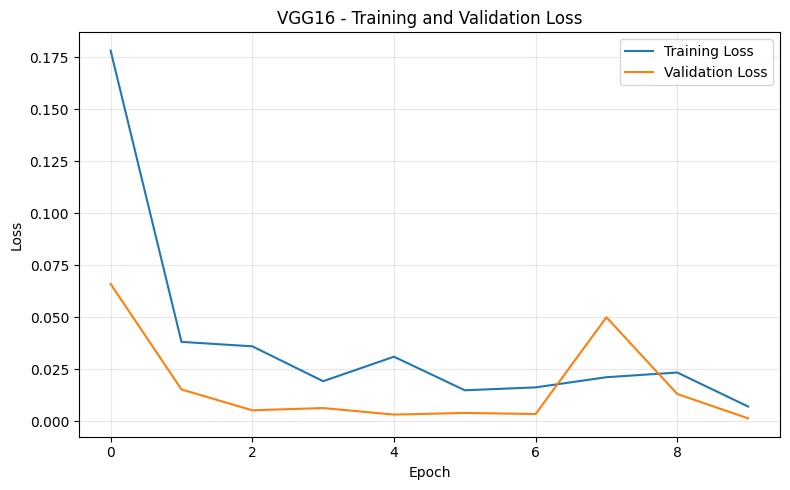

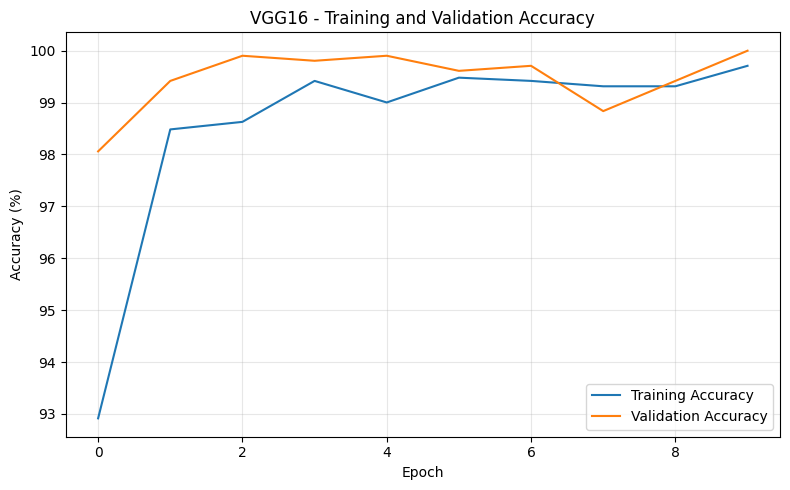

VGG16 loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/vgg16_loss_curve.png
VGG16 accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/vgg16_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 50: SAVE AND PLOT VGG16 TRAINING CURVES
# ============================================================

vgg16_history_df = pd.DataFrame({
    "epoch": list(range(1, len(vgg16_train_losses) + 1)),
    "train_loss": vgg16_train_losses,
    "val_loss": vgg16_val_losses,
    "train_accuracy": vgg16_train_accuracies,
    "val_accuracy": vgg16_val_accuracies
})

vgg16_history_df.to_csv(vgg16_history_path, index=False)

display(vgg16_history_df)

print("VGG16 training history saved at:", vgg16_history_path)

vgg16_loss_curve_path = FIGURE_DIR / f"{VGG16_MODEL_NAME}_loss_curve.png"
vgg16_accuracy_curve_path = FIGURE_DIR / f"{VGG16_MODEL_NAME}_accuracy_curve.png"

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(vgg16_train_losses, label="Training Loss")
plt.plot(vgg16_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(vgg16_loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(vgg16_train_accuracies, label="Training Accuracy")
plt.plot(vgg16_val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("VGG16 - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(vgg16_accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("VGG16 loss curve saved at:", vgg16_loss_curve_path)
print("VGG16 accuracy curve saved at:", vgg16_accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 51: TEST VGG16 MODEL
# ============================================================

if not vgg16_best_model_path.exists():
    raise FileNotFoundError("Best VGG16 model not found. Please train the VGG16 model first.")

vgg16_model.load_state_dict(
    torch.load(vgg16_best_model_path, map_location=device)
)

vgg16_test_loss, vgg16_test_acc, vgg16_test_preds, vgg16_test_labels = validate_model(
    vgg16_model,
    vgg16_test_loader,
    vgg16_criterion,
    device
)

print("VGG16 Test Loss:", round(vgg16_test_loss, 4))
print("VGG16 Test Accuracy:", round(vgg16_test_acc, 2), "%")

VGG16 Test Loss: 0.0
VGG16 Test Accuracy: 100.0 %


Classification Report - VGG16
                   precision    recall  f1-score   support

     complex_cyst       1.00      1.00      1.00       205
dominant_follicle       1.00      1.00      1.00       194
          healthy       1.00      1.00      1.00       220
        poly_cyst       1.00      1.00      1.00       214
      simple_cyst       1.00      1.00      1.00       199

         accuracy                           1.00      1032
        macro avg       1.00      1.00      1.00      1032
     weighted avg       1.00      1.00      1.00      1032

VGG16 classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_classification_report.txt


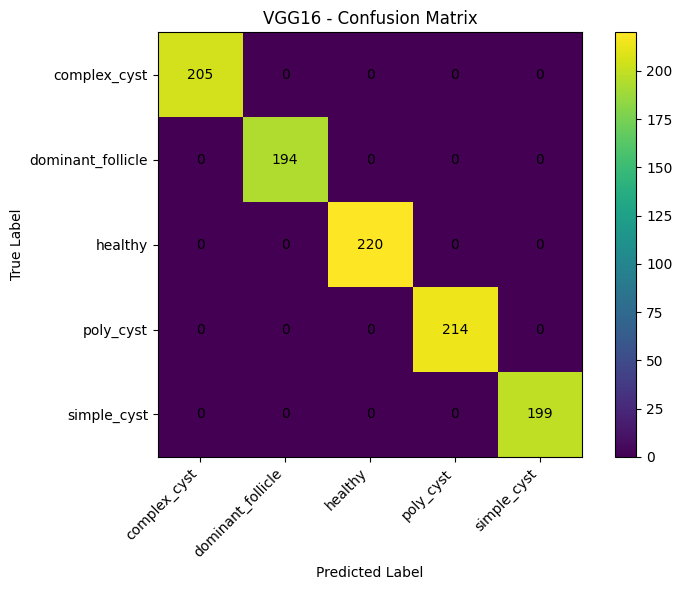

VGG16 confusion matrix saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/vgg16_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 52: VGG16 CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - VGG16")

vgg16_report_text = classification_report(
    vgg16_test_labels,
    vgg16_test_preds,
    target_names=class_names,
    zero_division=0
)

print(vgg16_report_text)

vgg16_report_path = RESULT_DIR / f"{VGG16_MODEL_NAME}_classification_report.txt"

with open(vgg16_report_path, "w") as f:
    f.write("Classification Report - VGG16\n")
    f.write(vgg16_report_text)

print("VGG16 classification report saved at:", vgg16_report_path)

# Confusion matrix
vgg16_cm = confusion_matrix(
    vgg16_test_labels,
    vgg16_test_preds
)

vgg16_confusion_matrix_path = FIGURE_DIR / f"{VGG16_MODEL_NAME}_confusion_matrix.png"

plt.figure(figsize=(8, 6))
plt.imshow(vgg16_cm)
plt.title("VGG16 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(
    ticks=np.arange(len(class_names)),
    labels=class_names,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(class_names)),
    labels=class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, vgg16_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(vgg16_confusion_matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("VGG16 confusion matrix saved at:", vgg16_confusion_matrix_path)

In [ ]:
# ============================================================
# CELL 53: SAVE VGG16 RESULT SUMMARY
# ============================================================

vgg16_accuracy = accuracy_score(
    vgg16_test_labels,
    vgg16_test_preds
)

vgg16_precision = precision_score(
    vgg16_test_labels,
    vgg16_test_preds,
    average="weighted",
    zero_division=0
)

vgg16_recall = recall_score(
    vgg16_test_labels,
    vgg16_test_preds,
    average="weighted",
    zero_division=0
)

vgg16_f1 = f1_score(
    vgg16_test_labels,
    vgg16_test_preds,
    average="weighted",
    zero_division=0
)

vgg16_results = pd.DataFrame([{
    "Model": "VGG16",
    "Image Size": f"{VGG16_IMG_SIZE}x{VGG16_IMG_SIZE}",
    "Test Accuracy": vgg16_accuracy,
    "Precision": vgg16_precision,
    "Recall": vgg16_recall,
    "F1 Score": vgg16_f1,
    "Best Validation Accuracy": vgg16_best_val_acc / 100,
    "Total Parameters": vgg16_total_params,
    "Trainable Parameters": vgg16_trainable_params,
    "Epochs Completed": len(vgg16_train_losses),
    "Batch Size": BATCH_SIZE,
    "Pretrained": True,
    "Feature Extractor Frozen": True
}])

vgg16_results_path = RESULT_DIR / f"{VGG16_MODEL_NAME}_results.csv"

vgg16_results.to_csv(vgg16_results_path, index=False)

display(vgg16_results)

print("VGG16 results saved at:", vgg16_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size,Pretrained,Feature Extractor Frozen
0,VGG16,224x224,1.0,1.0,1.0,1.0,1.0,134281029,119566341,10,32,True,True


VGG16 results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_results.csv


In [ ]:
# ============================================================
# CELL 54: VERIFY ALL VGG16 FILES SAVED IN GOOGLE DRIVE
# ============================================================

files_to_check = {
    "VGG16 best model": MODEL_DIR / f"{VGG16_MODEL_NAME}_best.pth",
    "VGG16 checkpoint": MODEL_DIR / f"{VGG16_MODEL_NAME}_checkpoint.pth",
    "VGG16 training history": RESULT_DIR / f"{VGG16_MODEL_NAME}_training_history.csv",
    "VGG16 result summary": RESULT_DIR / f"{VGG16_MODEL_NAME}_results.csv",
    "VGG16 classification report": RESULT_DIR / f"{VGG16_MODEL_NAME}_classification_report.txt",
    "VGG16 loss curve": FIGURE_DIR / f"{VGG16_MODEL_NAME}_loss_curve.png",
    "VGG16 accuracy curve": FIGURE_DIR / f"{VGG16_MODEL_NAME}_accuracy_curve.png",
    "VGG16 confusion matrix": FIGURE_DIR / f"{VGG16_MODEL_NAME}_confusion_matrix.png",
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

VGG16 best model: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/vgg16_best.pth
VGG16 checkpoint: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/vgg16_checkpoint.pth
VGG16 training history: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_training_history.csv
VGG16 result summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_results.csv
VGG16 classification report: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_classification_report.txt
VGG16 loss curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/vgg16_loss_curve.png
VGG16 accuracy curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/vgg16_accuracy_curve.png
VGG16 confusion matrix: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/vgg16_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 55: SAVE VGG16 MODEL DETAILS FOR REPORT
# ============================================================

vgg16_model_details = {
    "Model Name": "VGG16",
    "Model Type": "Transfer Learning CNN Architecture",
    "Input Image Size": f"{VGG16_IMG_SIZE}x{VGG16_IMG_SIZE}",
    "Input Shape": f"3 x {VGG16_IMG_SIZE} x {VGG16_IMG_SIZE}",
    "Number of Classes": len(class_names),
    "Classes": ", ".join(class_names),
    "Batch Size": BATCH_SIZE,
    "Epochs Completed": len(vgg16_train_losses),
    "Optimizer": "Adam",
    "Loss Function": "CrossEntropyLoss",
    "Pretrained": True,
    "Feature Extractor Frozen": True,
    "Total Parameters": vgg16_total_params,
    "Trainable Parameters": vgg16_trainable_params,
    "Best Validation Accuracy": vgg16_best_val_acc,
    "Best Model Path": str(vgg16_best_model_path),
    "Checkpoint Path": str(vgg16_checkpoint_path),
    "Training History Path": str(vgg16_history_path),
    "Result Summary Path": str(vgg16_results_path)
}

vgg16_model_details_df = pd.DataFrame([vgg16_model_details])

vgg16_model_details_path = RESULT_DIR / f"{VGG16_MODEL_NAME}_model_details.csv"

vgg16_model_details_df.to_csv(
    vgg16_model_details_path,
    index=False
)

display(vgg16_model_details_df)

print("VGG16 model details saved at:", vgg16_model_details_path)

,Model Name,Model Type,Input Image Size,Input Shape,Number of Classes,Classes,Batch Size,Epochs Completed,Optimizer,Loss Function,Pretrained,Feature Extractor Frozen,Total Parameters,Trainable Parameters,Best Validation Accuracy,Best Model Path,Checkpoint Path,Training History Path,Result Summary Path
0,VGG16,Transfer Learning CNN Architecture,224x224,3 x 224 x 224,5,"complex_cyst, dominant_follicle, healthy, poly...",32,10,Adam,CrossEntropyLoss,True,True,134281029,119566341,100.0,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...


VGG16 model details saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_model_details.csv


# CHECKING OVERLAP

The exact same image file is not repeated in train, validation, or test sets.

So there is no direct file leakage.

This is good and important because now we can say:

The high accuracy is not because the exact same file path exists in both training and testing data.

In [ ]:
# ============================================================
# QUICK CHECK: TRAIN / VAL / TEST FILE PATH OVERLAP
# ============================================================

print("Train columns:", train_df.columns)

possible_path_columns = ["image_path", "path", "filepath", "file_path", "image"]

path_col = None

for col in possible_path_columns:
    if col in train_df.columns:
        path_col = col
        break

if path_col is None:
    raise ValueError("Path column not found. Check dataframe columns printed above.")

train_paths = set(train_df[path_col].astype(str))
val_paths = set(val_df[path_col].astype(str))
test_paths = set(test_df[path_col].astype(str))

train_val_overlap = len(train_paths.intersection(val_paths))
train_test_overlap = len(train_paths.intersection(test_paths))
val_test_overlap = len(val_paths.intersection(test_paths))

print("Train-Val overlap:", train_val_overlap)
print("Train-Test overlap:", train_test_overlap)
print("Val-Test overlap:", val_test_overlap)

if train_val_overlap == 0 and train_test_overlap == 0 and val_test_overlap == 0:
    print("Good: No direct file path overlap found.")
else:
    print("Warning: File path overlap found. Splits need correction.")

Train columns: Index(['image_path', 'label', 'label_id'], dtype='object')
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
Good: No direct file path overlap found.


### **ResNet50**

In [ ]:
# ============================================================
# CELL 56: CREATE RESNET50 DATALOADERS AND CHECK ONE BATCH
# ============================================================

RESNET50_MODEL_NAME = "resnet50"

RESNET50_IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

resnet50_train_loader, resnet50_val_loader, resnet50_test_loader = create_dataloaders(
    img_size=RESNET50_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("ResNet50 DataLoaders created successfully.")
print("Training batches:", len(resnet50_train_loader))
print("Validation batches:", len(resnet50_val_loader))
print("Testing batches:", len(resnet50_test_loader))

images, labels = next(iter(resnet50_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

ResNet50 DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([4, 2, 2, 2, 4, 4, 2, 0, 4, 4])


In [ ]:
# ============================================================
# CELL 57: DEFINE RESNET50 TRANSFER LEARNING MODEL
# ============================================================

from torchvision import models

# Load pretrained ResNet50 model
try:
    resnet50_weights = models.ResNet50_Weights.DEFAULT
    resnet50_model = models.resnet50(weights=resnet50_weights)
    print("Pretrained ResNet50 weights loaded successfully.")
except Exception as e:
    print("Pretrained weights could not be loaded. Using ResNet50 without pretrained weights.")
    print("Reason:", e)
    resnet50_model = models.resnet50(weights=None)

# Freeze pretrained layers for faster transfer learning
for param in resnet50_model.parameters():
    param.requires_grad = False

# Replace final fully connected layer for 5 ovarian classes
in_features = resnet50_model.fc.in_features
resnet50_model.fc = nn.Linear(in_features, NUM_CLASSES)

resnet50_model = resnet50_model.to(device)

resnet50_total_params = sum(p.numel() for p in resnet50_model.parameters())
resnet50_trainable_params = sum(p.numel() for p in resnet50_model.parameters() if p.requires_grad)

print(resnet50_model)
print("\nResNet50 Total parameters:", resnet50_total_params)
print("ResNet50 Trainable parameters:", resnet50_trainable_params)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 160MB/s]


Pretrained ResNet50 weights loaded successfully.
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0)

In [ ]:
# ============================================================
# CELL 58: RESNET50 LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

resnet50_criterion = nn.CrossEntropyLoss()

resnet50_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, resnet50_model.parameters()),
    lr=0.0001
)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels


print("ResNet50 loss, optimizer, training and validation functions ready.")

ResNet50 loss, optimizer, training and validation functions ready.


In [ ]:
# ============================================================
# CELL 59: TRAIN RESNET50 WITH CHECKPOINT SAVE AND RESUME
# ============================================================

EPOCHS = 10 if torch.cuda.is_available() else 5

# Keep False normally.
# Set True only if you want to delete old ResNet50 checkpoint and start again.
RESET_RESNET50_TRAINING = False

resnet50_best_model_path = MODEL_DIR / f"{RESNET50_MODEL_NAME}_best.pth"
resnet50_checkpoint_path = MODEL_DIR / f"{RESNET50_MODEL_NAME}_checkpoint.pth"
resnet50_history_path = RESULT_DIR / f"{RESNET50_MODEL_NAME}_training_history.csv"

# ------------------------------------------------------------
# Optional reset
# ------------------------------------------------------------
if RESET_RESNET50_TRAINING:
    if resnet50_checkpoint_path.exists():
        resnet50_checkpoint_path.unlink()
        print("Old ResNet50 checkpoint deleted.")

    if resnet50_best_model_path.exists():
        resnet50_best_model_path.unlink()
        print("Old ResNet50 best model deleted.")

    if resnet50_history_path.exists():
        resnet50_history_path.unlink()
        print("Old ResNet50 training history deleted.")

    print("Starting fresh ResNet50 training.")

resnet50_best_val_acc = 0.0
resnet50_start_epoch = 0

resnet50_train_losses = []
resnet50_val_losses = []
resnet50_train_accuracies = []
resnet50_val_accuracies = []

# ------------------------------------------------------------
# Resume from checkpoint if available
# ------------------------------------------------------------
if resnet50_checkpoint_path.exists():
    checkpoint = torch.load(resnet50_checkpoint_path, map_location=device)

    resnet50_model.load_state_dict(checkpoint["model_state_dict"])
    resnet50_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    resnet50_start_epoch = checkpoint["epoch"]
    resnet50_best_val_acc = checkpoint["best_val_acc"]

    resnet50_train_losses = checkpoint["train_losses"]
    resnet50_val_losses = checkpoint["val_losses"]
    resnet50_train_accuracies = checkpoint["train_accuracies"]
    resnet50_val_accuracies = checkpoint["val_accuracies"]

    print("ResNet50 checkpoint found.")
    print("Resuming from epoch:", resnet50_start_epoch)
    print("Best validation accuracy so far:", resnet50_best_val_acc)
else:
    print("No ResNet50 checkpoint found. Starting fresh.")

print("\nStarting ResNet50 training...")
print("Epochs:", EPOCHS)
print("Device:", device)

# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------
if resnet50_start_epoch >= EPOCHS:
    print("ResNet50 training already completed for the selected number of epochs.")
else:
    for epoch in range(resnet50_start_epoch, EPOCHS):

        train_loss, train_acc = train_one_epoch(
            resnet50_model,
            resnet50_train_loader,
            resnet50_criterion,
            resnet50_optimizer,
            device
        )

        val_loss, val_acc, _, _ = validate_model(
            resnet50_model,
            resnet50_val_loader,
            resnet50_criterion,
            device
        )

        resnet50_train_losses.append(train_loss)
        resnet50_val_losses.append(val_loss)
        resnet50_train_accuracies.append(train_acc)
        resnet50_val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        # Save best model
        if val_acc > resnet50_best_val_acc:
            resnet50_best_val_acc = val_acc
            torch.save(resnet50_model.state_dict(), resnet50_best_model_path)

            print("Best ResNet50 model saved.")
            print("Best Validation Accuracy:", resnet50_best_val_acc)

        # Save checkpoint every epoch
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": resnet50_model.state_dict(),
            "optimizer_state_dict": resnet50_optimizer.state_dict(),
            "best_val_acc": resnet50_best_val_acc,
            "train_losses": resnet50_train_losses,
            "val_losses": resnet50_val_losses,
            "train_accuracies": resnet50_train_accuracies,
            "val_accuracies": resnet50_val_accuracies,
            "img_size": RESNET50_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "pretrained": True,
            "feature_extractor_frozen": True
        }, resnet50_checkpoint_path)

        # Save training history every epoch
        resnet50_history_df = pd.DataFrame({
            "epoch": list(range(1, len(resnet50_train_losses) + 1)),
            "train_loss": resnet50_train_losses,
            "val_loss": resnet50_val_losses,
            "train_accuracy": resnet50_train_accuracies,
            "val_accuracy": resnet50_val_accuracies
        })

        resnet50_history_df.to_csv(resnet50_history_path, index=False)

        print("ResNet50 checkpoint saved:", resnet50_checkpoint_path)
        print("ResNet50 training history saved:", resnet50_history_path)
        print("-" * 50)

print("\nResNet50 training completed.")
print("Best validation accuracy:", resnet50_best_val_acc)
print("Best model path:", resnet50_best_model_path)
print("Checkpoint path:", resnet50_checkpoint_path)
print("Training history path:", resnet50_history_path)

No ResNet50 checkpoint found. Starting fresh.

Starting ResNet50 training...
Epochs: 10
Device: cuda
Epoch [1/10]
Train Loss: 1.3106 | Train Acc: 68.54%
Val Loss:   1.0960 | Val Acc:   86.13%
Best ResNet50 model saved.
Best Validation Accuracy: 86.12997090203686
ResNet50 checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/resnet50_checkpoint.pth
ResNet50 training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_training_history.csv
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.8911 | Train Acc: 88.18%
Val Loss:   0.7865 | Val Acc:   90.79%
Best ResNet50 model saved.
Best Validation Accuracy: 90.78564500484966
ResNet50 checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/resnet50_checkpoint.pth
ResNet50 training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_training_history.csv
--------------------------------------------------
Epoch [3/10]
Train Loss

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,1.310615,1.095991,68.543528,86.129971
1,2,0.891090,0.786519,88.177852,90.785645
2,3,0.670702,0.662024,90.712653,91.755577
3,4,0.530253,0.503639,92.250156,92.628516
4,5,0.453694,0.415541,92.499481,93.986421
5,6,0.407925,0.397225,92.915022,93.889428
6,7,0.362041,0.339045,93.517557,94.180407
7,8,0.333139,0.320968,93.766881,94.277401
8,9,0.308441,0.308636,93.933098,94.665373
9,10,0.287329,0.293163,93.933098,93.986421


ResNet50 training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_training_history.csv


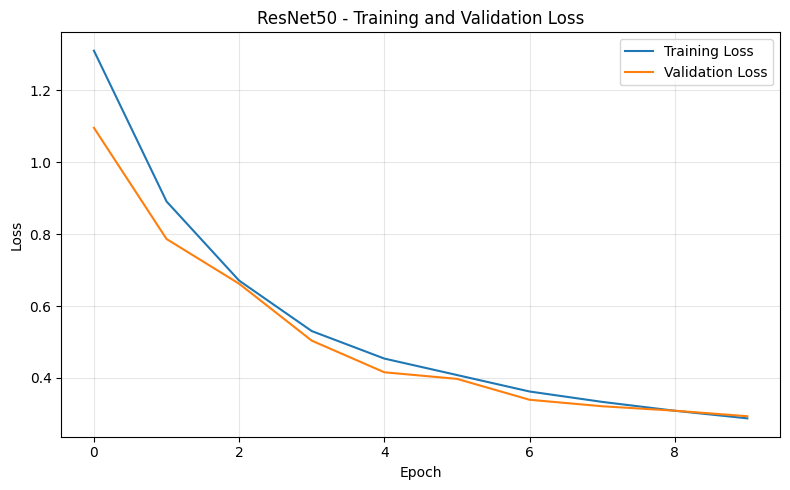

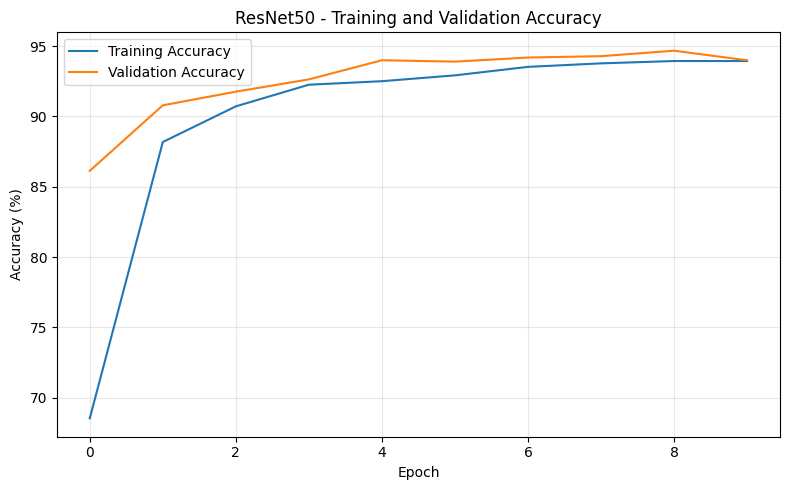

ResNet50 loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/resnet50_loss_curve.png
ResNet50 accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/resnet50_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 60: SAVE AND PLOT RESNET50 TRAINING CURVES
# ============================================================

resnet50_history_df = pd.DataFrame({
    "epoch": list(range(1, len(resnet50_train_losses) + 1)),
    "train_loss": resnet50_train_losses,
    "val_loss": resnet50_val_losses,
    "train_accuracy": resnet50_train_accuracies,
    "val_accuracy": resnet50_val_accuracies
})

resnet50_history_df.to_csv(resnet50_history_path, index=False)

display(resnet50_history_df)

print("ResNet50 training history saved at:", resnet50_history_path)

resnet50_loss_curve_path = FIGURE_DIR / f"{RESNET50_MODEL_NAME}_loss_curve.png"
resnet50_accuracy_curve_path = FIGURE_DIR / f"{RESNET50_MODEL_NAME}_accuracy_curve.png"

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(resnet50_train_losses, label="Training Loss")
plt.plot(resnet50_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(resnet50_loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(resnet50_train_accuracies, label="Training Accuracy")
plt.plot(resnet50_val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(resnet50_accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("ResNet50 loss curve saved at:", resnet50_loss_curve_path)
print("ResNet50 accuracy curve saved at:", resnet50_accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 61: TEST RESNET50 MODEL
# ============================================================

if not resnet50_best_model_path.exists():
    raise FileNotFoundError("Best ResNet50 model not found. Please train the ResNet50 model first.")

resnet50_model.load_state_dict(
    torch.load(resnet50_best_model_path, map_location=device)
)

resnet50_test_loss, resnet50_test_acc, resnet50_test_preds, resnet50_test_labels = validate_model(
    resnet50_model,
    resnet50_test_loader,
    resnet50_criterion,
    device
)

print("ResNet50 Test Loss:", round(resnet50_test_loss, 4))
print("ResNet50 Test Accuracy:", round(resnet50_test_acc, 2), "%")

ResNet50 Test Loss: 0.2869
ResNet50 Test Accuracy: 95.45 %


Classification Report - ResNet50
                   precision    recall  f1-score   support

     complex_cyst       0.86      0.93      0.89       205
dominant_follicle       0.99      1.00      1.00       194
          healthy       1.00      1.00      1.00       220
        poly_cyst       1.00      1.00      1.00       214
      simple_cyst       0.93      0.84      0.88       199

         accuracy                           0.95      1032
        macro avg       0.95      0.95      0.95      1032
     weighted avg       0.96      0.95      0.95      1032

ResNet50 classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_classification_report.txt


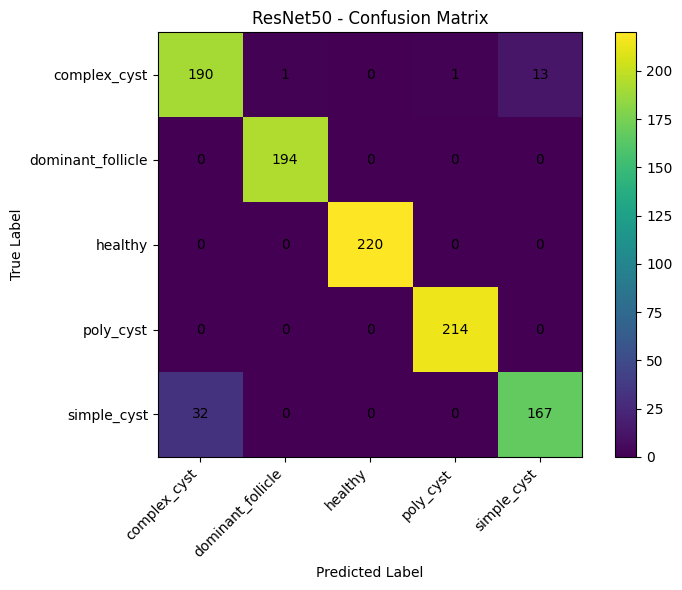

ResNet50 confusion matrix saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/resnet50_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 62: RESNET50 CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - ResNet50")

resnet50_report_text = classification_report(
    resnet50_test_labels,
    resnet50_test_preds,
    target_names=class_names,
    zero_division=0
)

print(resnet50_report_text)

resnet50_report_path = RESULT_DIR / f"{RESNET50_MODEL_NAME}_classification_report.txt"

with open(resnet50_report_path, "w") as f:
    f.write("Classification Report - ResNet50\n")
    f.write(resnet50_report_text)

print("ResNet50 classification report saved at:", resnet50_report_path)

# Confusion matrix
resnet50_cm = confusion_matrix(
    resnet50_test_labels,
    resnet50_test_preds
)

resnet50_confusion_matrix_path = FIGURE_DIR / f"{RESNET50_MODEL_NAME}_confusion_matrix.png"

plt.figure(figsize=(8, 6))
plt.imshow(resnet50_cm)
plt.title("ResNet50 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(
    ticks=np.arange(len(class_names)),
    labels=class_names,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(class_names)),
    labels=class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, resnet50_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(resnet50_confusion_matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("ResNet50 confusion matrix saved at:", resnet50_confusion_matrix_path)

In [ ]:
# ============================================================
# CELL 63: SAVE RESNET50 RESULT SUMMARY
# ============================================================

resnet50_accuracy = accuracy_score(
    resnet50_test_labels,
    resnet50_test_preds
)

resnet50_precision = precision_score(
    resnet50_test_labels,
    resnet50_test_preds,
    average="weighted",
    zero_division=0
)

resnet50_recall = recall_score(
    resnet50_test_labels,
    resnet50_test_preds,
    average="weighted",
    zero_division=0
)

resnet50_f1 = f1_score(
    resnet50_test_labels,
    resnet50_test_preds,
    average="weighted",
    zero_division=0
)

resnet50_results = pd.DataFrame([{
    "Model": "ResNet50",
    "Image Size": f"{RESNET50_IMG_SIZE}x{RESNET50_IMG_SIZE}",
    "Test Accuracy": resnet50_accuracy,
    "Precision": resnet50_precision,
    "Recall": resnet50_recall,
    "F1 Score": resnet50_f1,
    "Best Validation Accuracy": resnet50_best_val_acc / 100,
    "Total Parameters": resnet50_total_params,
    "Trainable Parameters": resnet50_trainable_params,
    "Epochs Completed": len(resnet50_train_losses),
    "Batch Size": BATCH_SIZE,
    "Pretrained": True,
    "Feature Extractor Frozen": True
}])

resnet50_results_path = RESULT_DIR / f"{RESNET50_MODEL_NAME}_results.csv"

resnet50_results.to_csv(resnet50_results_path, index=False)

display(resnet50_results)

print("ResNet50 results saved at:", resnet50_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size,Pretrained,Feature Extractor Frozen
0,ResNet50,224x224,0.954457,0.955512,0.954457,0.954273,0.946654,23518277,10245,10,32,True,True


ResNet50 results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_results.csv


In [ ]:
# ============================================================
# CELL 64: VERIFY ALL RESNET50 FILES SAVED IN GOOGLE DRIVE
# ============================================================

files_to_check = {
    "ResNet50 best model": MODEL_DIR / f"{RESNET50_MODEL_NAME}_best.pth",
    "ResNet50 checkpoint": MODEL_DIR / f"{RESNET50_MODEL_NAME}_checkpoint.pth",
    "ResNet50 training history": RESULT_DIR / f"{RESNET50_MODEL_NAME}_training_history.csv",
    "ResNet50 result summary": RESULT_DIR / f"{RESNET50_MODEL_NAME}_results.csv",
    "ResNet50 classification report": RESULT_DIR / f"{RESNET50_MODEL_NAME}_classification_report.txt",
    "ResNet50 loss curve": FIGURE_DIR / f"{RESNET50_MODEL_NAME}_loss_curve.png",
    "ResNet50 accuracy curve": FIGURE_DIR / f"{RESNET50_MODEL_NAME}_accuracy_curve.png",
    "ResNet50 confusion matrix": FIGURE_DIR / f"{RESNET50_MODEL_NAME}_confusion_matrix.png",
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

ResNet50 best model: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/resnet50_best.pth
ResNet50 checkpoint: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/resnet50_checkpoint.pth
ResNet50 training history: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_training_history.csv
ResNet50 result summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_results.csv
ResNet50 classification report: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_classification_report.txt
ResNet50 loss curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/resnet50_loss_curve.png
ResNet50 accuracy curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/resnet50_accuracy_curve.png
ResNet50 confusion matrix: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/resnet50_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 65: SAVE RESNET50 MODEL DETAILS FOR REPORT
# ============================================================

resnet50_model_details = {
    "Model Name": "ResNet50",
    "Model Type": "Transfer Learning CNN Architecture",
    "Input Image Size": f"{RESNET50_IMG_SIZE}x{RESNET50_IMG_SIZE}",
    "Input Shape": f"3 x {RESNET50_IMG_SIZE} x {RESNET50_IMG_SIZE}",
    "Number of Classes": len(class_names),
    "Classes": ", ".join(class_names),
    "Batch Size": BATCH_SIZE,
    "Epochs Completed": len(resnet50_train_losses),
    "Optimizer": "Adam",
    "Loss Function": "CrossEntropyLoss",
    "Pretrained": True,
    "Feature Extractor Frozen": True,
    "Total Parameters": resnet50_total_params,
    "Trainable Parameters": resnet50_trainable_params,
    "Best Validation Accuracy": resnet50_best_val_acc,
    "Best Model Path": str(resnet50_best_model_path),
    "Checkpoint Path": str(resnet50_checkpoint_path),
    "Training History Path": str(resnet50_history_path),
    "Result Summary Path": str(resnet50_results_path)
}

resnet50_model_details_df = pd.DataFrame([resnet50_model_details])

resnet50_model_details_path = RESULT_DIR / f"{RESNET50_MODEL_NAME}_model_details.csv"

resnet50_model_details_df.to_csv(
    resnet50_model_details_path,
    index=False
)

display(resnet50_model_details_df)

print("ResNet50 model details saved at:", resnet50_model_details_path)

,Model Name,Model Type,Input Image Size,Input Shape,Number of Classes,Classes,Batch Size,Epochs Completed,Optimizer,Loss Function,Pretrained,Feature Extractor Frozen,Total Parameters,Trainable Parameters,Best Validation Accuracy,Best Model Path,Checkpoint Path,Training History Path,Result Summary Path
0,ResNet50,Transfer Learning CNN Architecture,224x224,3 x 224 x 224,5,"complex_cyst, dominant_follicle, healthy, poly...",32,10,Adam,CrossEntropyLoss,True,True,23518277,10245,94.665373,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...


ResNet50 model details saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_model_details.csv


# **EfficientNet-B3**

In [ ]:
# ============================================================
# CELL 66: CREATE EFFICIENTNET-B3 DATALOADERS AND CHECK ONE BATCH
# ============================================================

EFFICIENTNET_B3_MODEL_NAME = "efficientnet_b3"

EFFICIENTNET_B3_IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

efficientnet_b3_train_loader, efficientnet_b3_val_loader, efficientnet_b3_test_loader = create_dataloaders(
    img_size=EFFICIENTNET_B3_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("EfficientNet-B3 DataLoaders created successfully.")
print("Training batches:", len(efficientnet_b3_train_loader))
print("Validation batches:", len(efficientnet_b3_val_loader))
print("Testing batches:", len(efficientnet_b3_test_loader))

images, labels = next(iter(efficientnet_b3_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

EfficientNet-B3 DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([0, 2, 1, 1, 4, 1, 0, 2, 0, 3])


In [ ]:
# ============================================================
# CELL 67: DEFINE EFFICIENTNET-B3 TRANSFER LEARNING MODEL
# ============================================================

from torchvision import models

efficientnet_b3_pretrained_loaded = False

try:
    efficientnet_b3_weights = models.EfficientNet_B3_Weights.DEFAULT
    efficientnet_b3_model = models.efficientnet_b3(weights=efficientnet_b3_weights)
    efficientnet_b3_pretrained_loaded = True
    print("Pretrained EfficientNet-B3 weights loaded successfully.")

except Exception as e:
    print("Pretrained weights could not be loaded. Using EfficientNet-B3 without pretrained weights.")
    print("Reason:", e)
    efficientnet_b3_model = models.efficientnet_b3(weights=None)

# Freeze all feature layers first
for param in efficientnet_b3_model.features.parameters():
    param.requires_grad = False

# Unfreeze last feature blocks for better medical image fine-tuning
if efficientnet_b3_pretrained_loaded:
    for param in efficientnet_b3_model.features[-2:].parameters():
        param.requires_grad = True
else:
    for param in efficientnet_b3_model.parameters():
        param.requires_grad = True

# Replace classifier for 5 ovarian ultrasound classes
in_features = efficientnet_b3_model.classifier[1].in_features
efficientnet_b3_model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

efficientnet_b3_model = efficientnet_b3_model.to(device)

efficientnet_b3_total_params = sum(p.numel() for p in efficientnet_b3_model.parameters())
efficientnet_b3_trainable_params = sum(p.numel() for p in efficientnet_b3_model.parameters() if p.requires_grad)

print(efficientnet_b3_model)
print("\nEfficientNet-B3 Total parameters:", efficientnet_b3_total_params)
print("EfficientNet-B3 Trainable parameters:", efficientnet_b3_trainable_params)
print("Pretrained loaded:", efficientnet_b3_pretrained_loaded)
print("Fine-tuning strategy: Last feature blocks + classifier")

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 143MB/s]


Pretrained EfficientNet-B3 weights loaded successfully.
EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
            (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activatio

In [ ]:
# ============================================================
# CELL 68: EFFICIENTNET-B3 LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

efficientnet_b3_criterion = nn.CrossEntropyLoss()

efficientnet_b3_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, efficientnet_b3_model.parameters()),
    lr=0.0001
)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels


print("EfficientNet-B3 loss, optimizer, training and validation functions ready.")

EfficientNet-B3 loss, optimizer, training and validation functions ready.


In [ ]:
# ============================================================
# CELL 69: TRAIN EFFICIENTNET-B3 WITH CHECKPOINT SAVE AND RESUME
# ============================================================

EPOCHS = 10 if torch.cuda.is_available() else 5

RESET_EFFICIENTNET_B3_TRAINING = False

efficientnet_b3_best_model_path = MODEL_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_best.pth"
efficientnet_b3_checkpoint_path = MODEL_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_checkpoint.pth"
efficientnet_b3_history_path = RESULT_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_training_history.csv"

if RESET_EFFICIENTNET_B3_TRAINING:
    if efficientnet_b3_checkpoint_path.exists():
        efficientnet_b3_checkpoint_path.unlink()
        print("Old EfficientNet-B3 checkpoint deleted.")

    if efficientnet_b3_best_model_path.exists():
        efficientnet_b3_best_model_path.unlink()
        print("Old EfficientNet-B3 best model deleted.")

    if efficientnet_b3_history_path.exists():
        efficientnet_b3_history_path.unlink()
        print("Old EfficientNet-B3 training history deleted.")

    print("Starting fresh EfficientNet-B3 training.")

efficientnet_b3_best_val_acc = 0.0
efficientnet_b3_start_epoch = 0

efficientnet_b3_train_losses = []
efficientnet_b3_val_losses = []
efficientnet_b3_train_accuracies = []
efficientnet_b3_val_accuracies = []

if efficientnet_b3_checkpoint_path.exists():
    checkpoint = torch.load(efficientnet_b3_checkpoint_path, map_location=device)

    efficientnet_b3_model.load_state_dict(checkpoint["model_state_dict"])
    efficientnet_b3_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    efficientnet_b3_start_epoch = checkpoint["epoch"]
    efficientnet_b3_best_val_acc = checkpoint["best_val_acc"]

    efficientnet_b3_train_losses = checkpoint["train_losses"]
    efficientnet_b3_val_losses = checkpoint["val_losses"]
    efficientnet_b3_train_accuracies = checkpoint["train_accuracies"]
    efficientnet_b3_val_accuracies = checkpoint["val_accuracies"]

    print("EfficientNet-B3 checkpoint found.")
    print("Resuming from epoch:", efficientnet_b3_start_epoch)
    print("Best validation accuracy so far:", efficientnet_b3_best_val_acc)
else:
    print("No EfficientNet-B3 checkpoint found. Starting fresh.")

print("\nStarting EfficientNet-B3 training...")
print("Epochs:", EPOCHS)
print("Device:", device)

if efficientnet_b3_start_epoch >= EPOCHS:
    print("EfficientNet-B3 training already completed for the selected number of epochs.")
else:
    for epoch in range(efficientnet_b3_start_epoch, EPOCHS):

        train_loss, train_acc = train_one_epoch(
            efficientnet_b3_model,
            efficientnet_b3_train_loader,
            efficientnet_b3_criterion,
            efficientnet_b3_optimizer,
            device
        )

        val_loss, val_acc, _, _ = validate_model(
            efficientnet_b3_model,
            efficientnet_b3_val_loader,
            efficientnet_b3_criterion,
            device
        )

        efficientnet_b3_train_losses.append(train_loss)
        efficientnet_b3_val_losses.append(val_loss)
        efficientnet_b3_train_accuracies.append(train_acc)
        efficientnet_b3_val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        if val_acc > efficientnet_b3_best_val_acc:
            efficientnet_b3_best_val_acc = val_acc
            torch.save(efficientnet_b3_model.state_dict(), efficientnet_b3_best_model_path)

            print("Best EfficientNet-B3 model saved.")
            print("Best Validation Accuracy:", efficientnet_b3_best_val_acc)

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": efficientnet_b3_model.state_dict(),
            "optimizer_state_dict": efficientnet_b3_optimizer.state_dict(),
            "best_val_acc": efficientnet_b3_best_val_acc,
            "train_losses": efficientnet_b3_train_losses,
            "val_losses": efficientnet_b3_val_losses,
            "train_accuracies": efficientnet_b3_train_accuracies,
            "val_accuracies": efficientnet_b3_val_accuracies,
            "img_size": EFFICIENTNET_B3_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "pretrained": efficientnet_b3_pretrained_loaded,
            "fine_tuning_strategy": "last_feature_blocks_and_classifier"
        }, efficientnet_b3_checkpoint_path)

        efficientnet_b3_history_df = pd.DataFrame({
            "epoch": list(range(1, len(efficientnet_b3_train_losses) + 1)),
            "train_loss": efficientnet_b3_train_losses,
            "val_loss": efficientnet_b3_val_losses,
            "train_accuracy": efficientnet_b3_train_accuracies,
            "val_accuracy": efficientnet_b3_val_accuracies
        })

        efficientnet_b3_history_df.to_csv(efficientnet_b3_history_path, index=False)

        print("EfficientNet-B3 checkpoint saved:", efficientnet_b3_checkpoint_path)
        print("EfficientNet-B3 training history saved:", efficientnet_b3_history_path)
        print("-" * 50)

print("\nEfficientNet-B3 training completed.")
print("Best validation accuracy:", efficientnet_b3_best_val_acc)
print("Best model path:", efficientnet_b3_best_model_path)
print("Checkpoint path:", efficientnet_b3_checkpoint_path)
print("Training history path:", efficientnet_b3_history_path)

No EfficientNet-B3 checkpoint found. Starting fresh.

Starting EfficientNet-B3 training...
Epochs: 10
Device: cuda
Epoch [1/10]
Train Loss: 0.6350 | Train Acc: 83.92%
Val Loss:   0.2093 | Val Acc:   93.79%
Best EfficientNet-B3 model saved.
Best Validation Accuracy: 93.79243452958293
EfficientNet-B3 checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/efficientnet_b3_checkpoint.pth
EfficientNet-B3 training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_training_history.csv
--------------------------------------------------
Epoch [2/10]
Train Loss: 0.1763 | Train Acc: 94.58%
Val Loss:   0.1130 | Val Acc:   95.83%
Best EfficientNet-B3 model saved.
Best Validation Accuracy: 95.82929194956353
EfficientNet-B3 checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/efficientnet_b3_checkpoint.pth
EfficientNet-B3 training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_training_hi

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.635008,0.209344,83.918554,93.792435
1,2,0.176256,0.112971,94.577187,95.829292
2,3,0.107267,0.066913,96.322460,97.284190
3,4,0.074331,0.043150,97.839186,98.545102
4,5,0.065455,0.032974,97.797631,98.545102
5,6,0.052024,0.019100,98.379389,99.418041
6,7,0.037400,0.014699,98.711822,99.515034
7,8,0.033859,0.008854,98.940370,99.806014
8,9,0.032071,0.007698,99.002701,99.806014
9,10,0.029055,0.003790,99.127363,99.903007


EfficientNet-B3 training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_training_history.csv


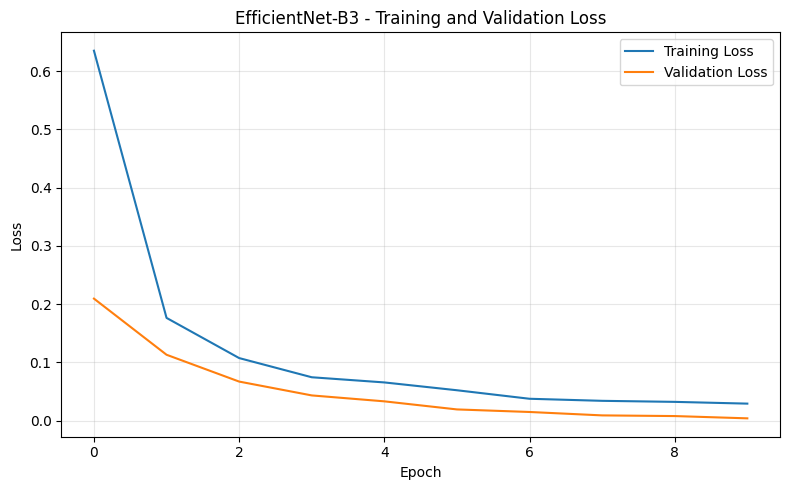

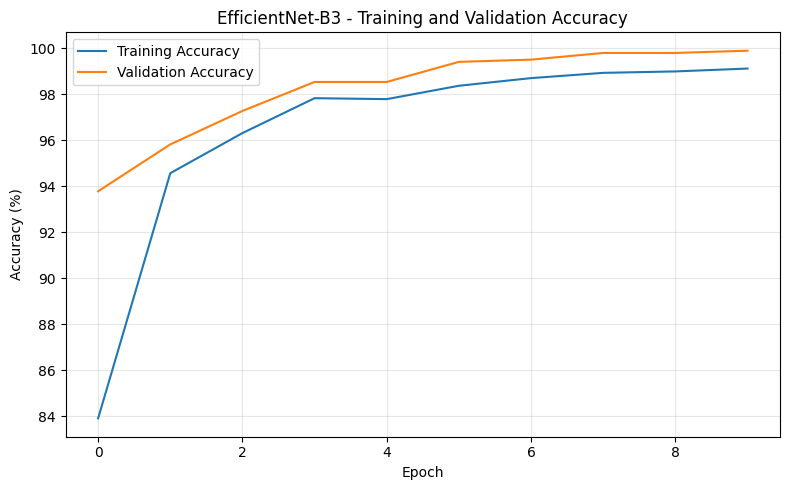

EfficientNet-B3 loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/efficientnet_b3_loss_curve.png
EfficientNet-B3 accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/efficientnet_b3_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 70: SAVE AND PLOT EFFICIENTNET-B3 TRAINING CURVES
# ============================================================

efficientnet_b3_history_df = pd.DataFrame({
    "epoch": list(range(1, len(efficientnet_b3_train_losses) + 1)),
    "train_loss": efficientnet_b3_train_losses,
    "val_loss": efficientnet_b3_val_losses,
    "train_accuracy": efficientnet_b3_train_accuracies,
    "val_accuracy": efficientnet_b3_val_accuracies
})

efficientnet_b3_history_df.to_csv(efficientnet_b3_history_path, index=False)

display(efficientnet_b3_history_df)

print("EfficientNet-B3 training history saved at:", efficientnet_b3_history_path)

efficientnet_b3_loss_curve_path = FIGURE_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_loss_curve.png"
efficientnet_b3_accuracy_curve_path = FIGURE_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_accuracy_curve.png"

plt.figure(figsize=(8, 5))
plt.plot(efficientnet_b3_train_losses, label="Training Loss")
plt.plot(efficientnet_b3_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B3 - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(efficientnet_b3_loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(efficientnet_b3_train_accuracies, label="Training Accuracy")
plt.plot(efficientnet_b3_val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("EfficientNet-B3 - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(efficientnet_b3_accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("EfficientNet-B3 loss curve saved at:", efficientnet_b3_loss_curve_path)
print("EfficientNet-B3 accuracy curve saved at:", efficientnet_b3_accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 71: TEST EFFICIENTNET-B3 MODEL
# ============================================================

if not efficientnet_b3_best_model_path.exists():
    raise FileNotFoundError("Best EfficientNet-B3 model not found. Please train the EfficientNet-B3 model first.")

efficientnet_b3_model.load_state_dict(
    torch.load(efficientnet_b3_best_model_path, map_location=device)
)

efficientnet_b3_test_loss, efficientnet_b3_test_acc, efficientnet_b3_test_preds, efficientnet_b3_test_labels = validate_model(
    efficientnet_b3_model,
    efficientnet_b3_test_loader,
    efficientnet_b3_criterion,
    device
)

print("EfficientNet-B3 Test Loss:", round(efficientnet_b3_test_loss, 4))
print("EfficientNet-B3 Test Accuracy:", round(efficientnet_b3_test_acc, 2), "%")

EfficientNet-B3 Test Loss: 0.0031
EfficientNet-B3 Test Accuracy: 99.81 %


Classification Report - EfficientNet-B3
                   precision    recall  f1-score   support

     complex_cyst       0.99      1.00      1.00       205
dominant_follicle       1.00      1.00      1.00       194
          healthy       1.00      1.00      1.00       220
        poly_cyst       1.00      1.00      1.00       214
      simple_cyst       1.00      0.99      0.99       199

         accuracy                           1.00      1032
        macro avg       1.00      1.00      1.00      1032
     weighted avg       1.00      1.00      1.00      1032

EfficientNet-B3 classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_classification_report.txt


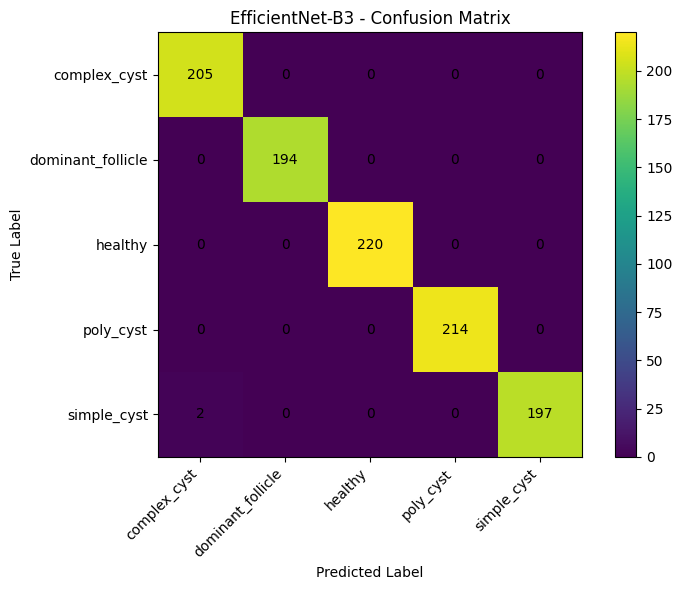

EfficientNet-B3 confusion matrix saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/efficientnet_b3_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 72: EFFICIENTNET-B3 CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - EfficientNet-B3")

efficientnet_b3_report_text = classification_report(
    efficientnet_b3_test_labels,
    efficientnet_b3_test_preds,
    target_names=class_names,
    zero_division=0
)

print(efficientnet_b3_report_text)

efficientnet_b3_report_path = RESULT_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_classification_report.txt"

with open(efficientnet_b3_report_path, "w") as f:
    f.write("Classification Report - EfficientNet-B3\n")
    f.write(efficientnet_b3_report_text)

print("EfficientNet-B3 classification report saved at:", efficientnet_b3_report_path)

efficientnet_b3_cm = confusion_matrix(
    efficientnet_b3_test_labels,
    efficientnet_b3_test_preds
)

efficientnet_b3_confusion_matrix_path = FIGURE_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_confusion_matrix.png"

plt.figure(figsize=(8, 6))
plt.imshow(efficientnet_b3_cm)
plt.title("EfficientNet-B3 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(
    ticks=np.arange(len(class_names)),
    labels=class_names,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(class_names)),
    labels=class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, efficientnet_b3_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(efficientnet_b3_confusion_matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("EfficientNet-B3 confusion matrix saved at:", efficientnet_b3_confusion_matrix_path)

In [ ]:
# ============================================================
# CELL 73: SAVE EFFICIENTNET-B3 RESULT SUMMARY
# ============================================================

efficientnet_b3_accuracy = accuracy_score(efficientnet_b3_test_labels, efficientnet_b3_test_preds)
efficientnet_b3_precision = precision_score(efficientnet_b3_test_labels, efficientnet_b3_test_preds, average="weighted", zero_division=0)
efficientnet_b3_recall = recall_score(efficientnet_b3_test_labels, efficientnet_b3_test_preds, average="weighted", zero_division=0)
efficientnet_b3_f1 = f1_score(efficientnet_b3_test_labels, efficientnet_b3_test_preds, average="weighted", zero_division=0)

efficientnet_b3_results = pd.DataFrame([{
    "Model": "EfficientNet-B3",
    "Image Size": f"{EFFICIENTNET_B3_IMG_SIZE}x{EFFICIENTNET_B3_IMG_SIZE}",
    "Test Accuracy": efficientnet_b3_accuracy,
    "Precision": efficientnet_b3_precision,
    "Recall": efficientnet_b3_recall,
    "F1 Score": efficientnet_b3_f1,
    "Best Validation Accuracy": efficientnet_b3_best_val_acc / 100,
    "Total Parameters": efficientnet_b3_total_params,
    "Trainable Parameters": efficientnet_b3_trainable_params,
    "Epochs Completed": len(efficientnet_b3_train_losses),
    "Batch Size": BATCH_SIZE,
    "Pretrained": efficientnet_b3_pretrained_loaded,
    "Fine-tuning Strategy": "Last feature blocks + classifier"
}])

efficientnet_b3_results_path = RESULT_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_results.csv"

efficientnet_b3_results.to_csv(efficientnet_b3_results_path, index=False)

display(efficientnet_b3_results)

print("EfficientNet-B3 results saved at:", efficientnet_b3_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size,Pretrained,Fine-tuning Strategy
0,EfficientNet-B3,224x224,0.998062,0.998081,0.998062,0.998062,0.99903,10703917,3884799,10,32,True,Last feature blocks + classifier


EfficientNet-B3 results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_results.csv


In [ ]:
# ============================================================
# CELL 74: VERIFY ALL EFFICIENTNET-B3 FILES SAVED IN GOOGLE DRIVE
# ============================================================

files_to_check = {
    "EfficientNet-B3 best model": MODEL_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_best.pth",
    "EfficientNet-B3 checkpoint": MODEL_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_checkpoint.pth",
    "EfficientNet-B3 training history": RESULT_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_training_history.csv",
    "EfficientNet-B3 result summary": RESULT_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_results.csv",
    "EfficientNet-B3 classification report": RESULT_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_classification_report.txt",
    "EfficientNet-B3 loss curve": FIGURE_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_loss_curve.png",
    "EfficientNet-B3 accuracy curve": FIGURE_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_accuracy_curve.png",
    "EfficientNet-B3 confusion matrix": FIGURE_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_confusion_matrix.png",
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

EfficientNet-B3 best model: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/efficientnet_b3_best.pth
EfficientNet-B3 checkpoint: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/efficientnet_b3_checkpoint.pth
EfficientNet-B3 training history: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_training_history.csv
EfficientNet-B3 result summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_results.csv
EfficientNet-B3 classification report: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_classification_report.txt
EfficientNet-B3 loss curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/efficientnet_b3_loss_curve.png
EfficientNet-B3 accuracy curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/efficientnet_b3_accuracy_curve.png
EfficientNet-B3 confusion matrix: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/effici

In [ ]:
# ============================================================
# CELL 75: SAVE EFFICIENTNET-B3 MODEL DETAILS FOR REPORT
# ============================================================

efficientnet_b3_model_details = {
    "Model Name": "EfficientNet-B3",
    "Model Type": "Transfer Learning CNN Architecture",
    "Input Image Size": f"{EFFICIENTNET_B3_IMG_SIZE}x{EFFICIENTNET_B3_IMG_SIZE}",
    "Input Shape": f"3 x {EFFICIENTNET_B3_IMG_SIZE} x {EFFICIENTNET_B3_IMG_SIZE}",
    "Number of Classes": len(class_names),
    "Classes": ", ".join(class_names),
    "Batch Size": BATCH_SIZE,
    "Epochs Completed": len(efficientnet_b3_train_losses),
    "Optimizer": "Adam",
    "Loss Function": "CrossEntropyLoss",
    "Pretrained": efficientnet_b3_pretrained_loaded,
    "Fine-tuning Strategy": "Last feature blocks + classifier",
    "Total Parameters": efficientnet_b3_total_params,
    "Trainable Parameters": efficientnet_b3_trainable_params,
    "Best Validation Accuracy": efficientnet_b3_best_val_acc,
    "Best Model Path": str(efficientnet_b3_best_model_path),
    "Checkpoint Path": str(efficientnet_b3_checkpoint_path),
    "Training History Path": str(efficientnet_b3_history_path),
    "Result Summary Path": str(efficientnet_b3_results_path)
}

efficientnet_b3_model_details_df = pd.DataFrame([efficientnet_b3_model_details])

efficientnet_b3_model_details_path = RESULT_DIR / f"{EFFICIENTNET_B3_MODEL_NAME}_model_details.csv"

efficientnet_b3_model_details_df.to_csv(
    efficientnet_b3_model_details_path,
    index=False
)

display(efficientnet_b3_model_details_df)

print("EfficientNet-B3 model details saved at:", efficientnet_b3_model_details_path)

,Model Name,Model Type,Input Image Size,Input Shape,Number of Classes,Classes,Batch Size,Epochs Completed,Optimizer,Loss Function,Pretrained,Fine-tuning Strategy,Total Parameters,Trainable Parameters,Best Validation Accuracy,Best Model Path,Checkpoint Path,Training History Path,Result Summary Path
0,EfficientNet-B3,Transfer Learning CNN Architecture,224x224,3 x 224 x 224,5,"complex_cyst, dominant_follicle, healthy, poly...",32,10,Adam,CrossEntropyLoss,True,Last feature blocks + classifier,10703917,3884799,99.903007,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...


EfficientNet-B3 model details saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_model_details.csv


# **Hybrid EfficientNet-B3 + Transformer**

EfficientNet-B3 → feature extractor

Transformer Encoder → learns global relationships

Classifier → predicts 5 ovarian classes

In [ ]:
# ============================================================
# CELL 76: CREATE HYBRID EFFICIENTNET-B3 + TRANSFORMER DATALOADERS
# ============================================================

HYBRID_MODEL_NAME = "hybrid_efficientnet_b3_transformer"

HYBRID_IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

hybrid_train_loader, hybrid_val_loader, hybrid_test_loader = create_dataloaders(
    img_size=HYBRID_IMG_SIZE,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    augment=True
)

print("Hybrid EfficientNet-B3 + Transformer DataLoaders created successfully.")
print("Training batches:", len(hybrid_train_loader))
print("Validation batches:", len(hybrid_val_loader))
print("Testing batches:", len(hybrid_test_loader))

images, labels = next(iter(hybrid_train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First 10 labels:", labels[:10])

Hybrid EfficientNet-B3 + Transformer DataLoaders created successfully.
Training batches: 151
Validation batches: 33
Testing batches: 33

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First 10 labels: tensor([0, 2, 1, 1, 4, 1, 0, 2, 0, 3])


In [ ]:
# ============================================================
# CELL 77: DEFINE HYBRID EFFICIENTNET-B3 + TRANSFORMER MODEL
# ============================================================

from torchvision import models

hybrid_pretrained_loaded = False

try:
    hybrid_weights = models.EfficientNet_B3_Weights.DEFAULT
    efficientnet_backbone = models.efficientnet_b3(weights=hybrid_weights)
    hybrid_pretrained_loaded = True
    print("Pretrained EfficientNet-B3 backbone loaded successfully.")
except Exception as e:
    print("Pretrained weights could not be loaded. Using EfficientNet-B3 backbone without pretrained weights.")
    print("Reason:", e)
    efficientnet_backbone = models.efficientnet_b3(weights=None)


class HybridEfficientNetB3Transformer(nn.Module):
    def __init__(
        self,
        efficientnet_model,
        num_classes=5,
        d_model=256,
        nhead=8,
        num_transformer_layers=2,
        dropout=0.3
    ):
        super(HybridEfficientNetB3Transformer, self).__init__()

        # EfficientNet feature extractor only
        self.feature_extractor = efficientnet_model.features

        # EfficientNet-B3 final feature channels = 1536
        self.feature_channels = 1536

        # Convert EfficientNet feature channels into Transformer dimension
        self.channel_projection = nn.Linear(self.feature_channels, d_model)

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=512,
            dropout=dropout,
            batch_first=True
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_transformer_layers
        )

        # Classification head
        self.classifier = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # Extract CNN feature maps
        x = self.feature_extractor(x)
        # Shape: [batch, channels, height, width]

        batch_size, channels, height, width = x.shape

        # Convert feature map to sequence tokens
        x = x.view(batch_size, channels, height * width)
        x = x.permute(0, 2, 1)
        # Shape: [batch, tokens, channels]

        # Project channels to transformer dimension
        x = self.channel_projection(x)
        # Shape: [batch, tokens, d_model]

        # Transformer encoding
        x = self.transformer_encoder(x)

        # Global average pooling over tokens
        x = x.mean(dim=1)

        # Classification
        x = self.classifier(x)

        return x


hybrid_model = HybridEfficientNetB3Transformer(
    efficientnet_model=efficientnet_backbone,
    num_classes=NUM_CLASSES,
    d_model=256,
    nhead=8,
    num_transformer_layers=2,
    dropout=0.3
)

# ------------------------------------------------------------
# Fine-tuning strategy
# ------------------------------------------------------------
# Freeze all EfficientNet feature layers first
for param in hybrid_model.feature_extractor.parameters():
    param.requires_grad = False

# Unfreeze last EfficientNet feature blocks for medical image adaptation
if hybrid_pretrained_loaded:
    for param in hybrid_model.feature_extractor[-2:].parameters():
        param.requires_grad = True
else:
    for param in hybrid_model.feature_extractor.parameters():
        param.requires_grad = True

hybrid_model = hybrid_model.to(device)

hybrid_total_params = sum(p.numel() for p in hybrid_model.parameters())
hybrid_trainable_params = sum(p.numel() for p in hybrid_model.parameters() if p.requires_grad)

print(hybrid_model)
print("\nHybrid Total parameters:", hybrid_total_params)
print("Hybrid Trainable parameters:", hybrid_trainable_params)
print("Pretrained loaded:", hybrid_pretrained_loaded)
print("Fine-tuning strategy: EfficientNet-B3 last blocks + Transformer + classifier")

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 165MB/s]


Pretrained EfficientNet-B3 backbone loaded successfully.
HybridEfficientNetB3Transformer(
  (feature_extractor): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
            (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)

In [ ]:
# ============================================================
# CELL 78: HYBRID LOSS, OPTIMIZER, TRAINING AND VALIDATION FUNCTIONS
# ============================================================

hybrid_criterion = nn.CrossEntropyLoss()

hybrid_optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, hybrid_model.parameters()),
    lr=0.0001
)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc


def validate_model(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc, all_preds, all_labels


print("Hybrid loss, optimizer, training and validation functions ready.")

Hybrid loss, optimizer, training and validation functions ready.


In [ ]:
# ============================================================
# CELL 79: TRAIN HYBRID EFFICIENTNET-B3 + TRANSFORMER MODEL
# ============================================================

EPOCHS = 10 if torch.cuda.is_available() else 5

RESET_HYBRID_TRAINING = False

hybrid_best_model_path = MODEL_DIR / f"{HYBRID_MODEL_NAME}_best.pth"
hybrid_checkpoint_path = MODEL_DIR / f"{HYBRID_MODEL_NAME}_checkpoint.pth"
hybrid_history_path = RESULT_DIR / f"{HYBRID_MODEL_NAME}_training_history.csv"

if RESET_HYBRID_TRAINING:
    if hybrid_checkpoint_path.exists():
        hybrid_checkpoint_path.unlink()
        print("Old Hybrid checkpoint deleted.")

    if hybrid_best_model_path.exists():
        hybrid_best_model_path.unlink()
        print("Old Hybrid best model deleted.")

    if hybrid_history_path.exists():
        hybrid_history_path.unlink()
        print("Old Hybrid training history deleted.")

    print("Starting fresh Hybrid training.")

hybrid_best_val_acc = 0.0
hybrid_start_epoch = 0

hybrid_train_losses = []
hybrid_val_losses = []
hybrid_train_accuracies = []
hybrid_val_accuracies = []

if hybrid_checkpoint_path.exists():
    checkpoint = torch.load(hybrid_checkpoint_path, map_location=device)

    hybrid_model.load_state_dict(checkpoint["model_state_dict"])
    hybrid_optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    hybrid_start_epoch = checkpoint["epoch"]
    hybrid_best_val_acc = checkpoint["best_val_acc"]

    hybrid_train_losses = checkpoint["train_losses"]
    hybrid_val_losses = checkpoint["val_losses"]
    hybrid_train_accuracies = checkpoint["train_accuracies"]
    hybrid_val_accuracies = checkpoint["val_accuracies"]

    print("Hybrid checkpoint found.")
    print("Resuming from epoch:", hybrid_start_epoch)
    print("Best validation accuracy so far:", hybrid_best_val_acc)
else:
    print("No Hybrid checkpoint found. Starting fresh.")

print("\nStarting Hybrid EfficientNet-B3 + Transformer training...")
print("Epochs:", EPOCHS)
print("Device:", device)

if hybrid_start_epoch >= EPOCHS:
    print("Hybrid training already completed for the selected number of epochs.")
else:
    for epoch in range(hybrid_start_epoch, EPOCHS):

        train_loss, train_acc = train_one_epoch(
            hybrid_model,
            hybrid_train_loader,
            hybrid_criterion,
            hybrid_optimizer,
            device
        )

        val_loss, val_acc, _, _ = validate_model(
            hybrid_model,
            hybrid_val_loader,
            hybrid_criterion,
            device
        )

        hybrid_train_losses.append(train_loss)
        hybrid_val_losses.append(val_loss)
        hybrid_train_accuracies.append(train_acc)
        hybrid_val_accuracies.append(val_acc)

        print(f"Epoch [{epoch+1}/{EPOCHS}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        if val_acc > hybrid_best_val_acc:
            hybrid_best_val_acc = val_acc
            torch.save(hybrid_model.state_dict(), hybrid_best_model_path)

            print("Best Hybrid model saved.")
            print("Best Validation Accuracy:", hybrid_best_val_acc)

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": hybrid_model.state_dict(),
            "optimizer_state_dict": hybrid_optimizer.state_dict(),
            "best_val_acc": hybrid_best_val_acc,
            "train_losses": hybrid_train_losses,
            "val_losses": hybrid_val_losses,
            "train_accuracies": hybrid_train_accuracies,
            "val_accuracies": hybrid_val_accuracies,
            "img_size": HYBRID_IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "class_names": class_names,
            "class_to_idx": class_to_idx,
            "pretrained": hybrid_pretrained_loaded,
            "cnn_backbone": "EfficientNet-B3",
            "transformer_layers": 2,
            "transformer_heads": 8,
            "d_model": 256,
            "fine_tuning_strategy": "EfficientNet-B3 last blocks + Transformer + classifier"
        }, hybrid_checkpoint_path)

        hybrid_history_df = pd.DataFrame({
            "epoch": list(range(1, len(hybrid_train_losses) + 1)),
            "train_loss": hybrid_train_losses,
            "val_loss": hybrid_val_losses,
            "train_accuracy": hybrid_train_accuracies,
            "val_accuracy": hybrid_val_accuracies
        })

        hybrid_history_df.to_csv(hybrid_history_path, index=False)

        print("Hybrid checkpoint saved:", hybrid_checkpoint_path)
        print("Hybrid training history saved:", hybrid_history_path)
        print("-" * 50)

print("\nHybrid training completed.")
print("Best validation accuracy:", hybrid_best_val_acc)
print("Best model path:", hybrid_best_model_path)
print("Checkpoint path:", hybrid_checkpoint_path)
print("Training history path:", hybrid_history_path)

No Hybrid checkpoint found. Starting fresh.

Starting Hybrid EfficientNet-B3 + Transformer training...
Epochs: 5
Device: cpu
Epoch [1/5]
Train Loss: 0.3992 | Train Acc: 86.99%
Val Loss:   0.1580 | Val Acc:   94.57%
Best Hybrid model saved.
Best Validation Accuracy: 94.56838021338507
Hybrid checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/hybrid_efficientnet_b3_transformer_checkpoint.pth
Hybrid training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_training_history.csv
--------------------------------------------------
Epoch [2/5]
Train Loss: 0.1377 | Train Acc: 95.26%
Val Loss:   0.1031 | Val Acc:   96.51%
Best Hybrid model saved.
Best Validation Accuracy: 96.5082444228904
Hybrid checkpoint saved: /content/drive/MyDrive/Ovarian_Research_Project/models/hybrid_efficientnet_b3_transformer_checkpoint.pth
Hybrid training history saved: /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientn

,epoch,train_loss,val_loss,train_accuracy,val_accuracy
0,1,0.399180,0.158035,86.993559,94.568380
1,2,0.137746,0.103116,95.262830,96.508244
2,3,0.080977,0.040996,97.319759,98.351115
3,4,0.054983,0.040760,98.192396,98.545102
4,5,0.050169,0.032089,98.317058,99.224054


Hybrid training history saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_training_history.csv


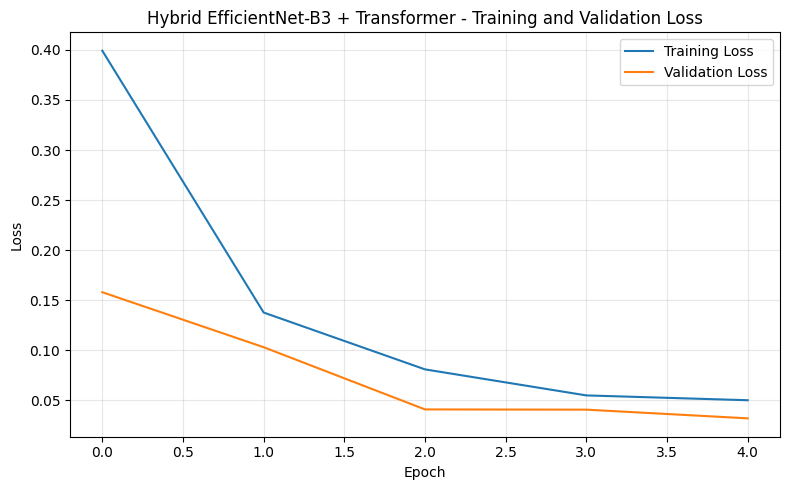

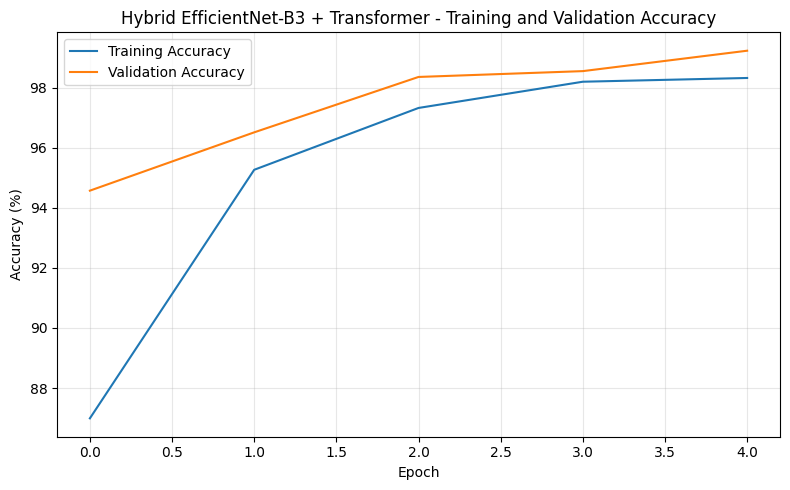

Hybrid loss curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/hybrid_efficientnet_b3_transformer_loss_curve.png
Hybrid accuracy curve saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/hybrid_efficientnet_b3_transformer_accuracy_curve.png


In [ ]:
# ============================================================
# CELL 80: SAVE AND PLOT HYBRID TRAINING CURVES
# ============================================================

hybrid_history_df = pd.DataFrame({
    "epoch": list(range(1, len(hybrid_train_losses) + 1)),
    "train_loss": hybrid_train_losses,
    "val_loss": hybrid_val_losses,
    "train_accuracy": hybrid_train_accuracies,
    "val_accuracy": hybrid_val_accuracies
})

hybrid_history_df.to_csv(hybrid_history_path, index=False)

display(hybrid_history_df)

print("Hybrid training history saved at:", hybrid_history_path)

hybrid_loss_curve_path = FIGURE_DIR / f"{HYBRID_MODEL_NAME}_loss_curve.png"
hybrid_accuracy_curve_path = FIGURE_DIR / f"{HYBRID_MODEL_NAME}_accuracy_curve.png"

plt.figure(figsize=(8, 5))
plt.plot(hybrid_train_losses, label="Training Loss")
plt.plot(hybrid_val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Hybrid EfficientNet-B3 + Transformer - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(hybrid_loss_curve_path, dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(hybrid_train_accuracies, label="Training Accuracy")
plt.plot(hybrid_val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Hybrid EfficientNet-B3 + Transformer - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(hybrid_accuracy_curve_path, dpi=300, bbox_inches="tight")
plt.show()

print("Hybrid loss curve saved at:", hybrid_loss_curve_path)
print("Hybrid accuracy curve saved at:", hybrid_accuracy_curve_path)

In [ ]:
# ============================================================
# CELL 81: TEST HYBRID MODEL
# ============================================================

if not hybrid_best_model_path.exists():
    raise FileNotFoundError("Best Hybrid model not found. Please train the Hybrid model first.")

hybrid_model.load_state_dict(
    torch.load(hybrid_best_model_path, map_location=device)
)

hybrid_test_loss, hybrid_test_acc, hybrid_test_preds, hybrid_test_labels = validate_model(
    hybrid_model,
    hybrid_test_loader,
    hybrid_criterion,
    device
)

print("Hybrid Test Loss:", round(hybrid_test_loss, 4))
print("Hybrid Test Accuracy:", round(hybrid_test_acc, 2), "%")

Hybrid Test Loss: 0.0134
Hybrid Test Accuracy: 99.61 %


Classification Report - Hybrid EfficientNet-B3 + Transformer
                   precision    recall  f1-score   support

     complex_cyst       0.99      1.00      0.99       205
dominant_follicle       1.00      1.00      1.00       194
          healthy       1.00      1.00      1.00       220
        poly_cyst       1.00      1.00      1.00       214
      simple_cyst       0.99      0.98      0.99       199

         accuracy                           1.00      1032
        macro avg       1.00      1.00      1.00      1032
     weighted avg       1.00      1.00      1.00      1032

Hybrid classification report saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_classification_report.txt


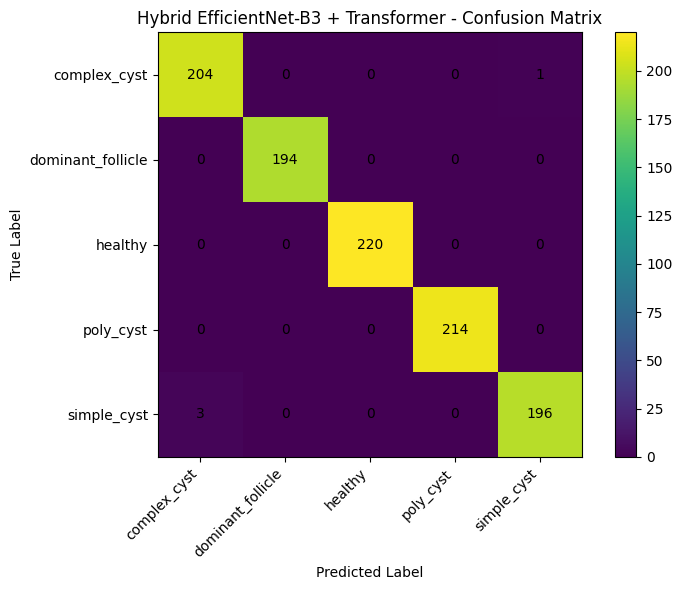

Hybrid confusion matrix saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/hybrid_efficientnet_b3_transformer_confusion_matrix.png


In [ ]:
# ============================================================
# CELL 82: HYBRID CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

print("Classification Report - Hybrid EfficientNet-B3 + Transformer")

hybrid_report_text = classification_report(
    hybrid_test_labels,
    hybrid_test_preds,
    target_names=class_names,
    zero_division=0
)

print(hybrid_report_text)

hybrid_report_path = RESULT_DIR / f"{HYBRID_MODEL_NAME}_classification_report.txt"

with open(hybrid_report_path, "w") as f:
    f.write("Classification Report - Hybrid EfficientNet-B3 + Transformer\n")
    f.write(hybrid_report_text)

print("Hybrid classification report saved at:", hybrid_report_path)

hybrid_cm = confusion_matrix(
    hybrid_test_labels,
    hybrid_test_preds
)

hybrid_confusion_matrix_path = FIGURE_DIR / f"{HYBRID_MODEL_NAME}_confusion_matrix.png"

plt.figure(figsize=(8, 6))
plt.imshow(hybrid_cm)
plt.title("Hybrid EfficientNet-B3 + Transformer - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(
    ticks=np.arange(len(class_names)),
    labels=class_names,
    rotation=45,
    ha="right"
)
plt.yticks(
    ticks=np.arange(len(class_names)),
    labels=class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, hybrid_cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.savefig(hybrid_confusion_matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("Hybrid confusion matrix saved at:", hybrid_confusion_matrix_path)

In [ ]:
# ============================================================
# CELL 83: SAVE HYBRID RESULT SUMMARY
# ============================================================

hybrid_accuracy = accuracy_score(hybrid_test_labels, hybrid_test_preds)
hybrid_precision = precision_score(hybrid_test_labels, hybrid_test_preds, average="weighted", zero_division=0)
hybrid_recall = recall_score(hybrid_test_labels, hybrid_test_preds, average="weighted", zero_division=0)
hybrid_f1 = f1_score(hybrid_test_labels, hybrid_test_preds, average="weighted", zero_division=0)

hybrid_results = pd.DataFrame([{
    "Model": "Hybrid EfficientNet-B3 + Transformer",
    "Image Size": f"{HYBRID_IMG_SIZE}x{HYBRID_IMG_SIZE}",
    "Test Accuracy": hybrid_accuracy,
    "Precision": hybrid_precision,
    "Recall": hybrid_recall,
    "F1 Score": hybrid_f1,
    "Best Validation Accuracy": hybrid_best_val_acc / 100,
    "Total Parameters": hybrid_total_params,
    "Trainable Parameters": hybrid_trainable_params,
    "Epochs Completed": len(hybrid_train_losses),
    "Batch Size": BATCH_SIZE,
    "Pretrained": hybrid_pretrained_loaded,
    "CNN Backbone": "EfficientNet-B3",
    "Transformer Layers": 2,
    "Transformer Heads": 8,
    "Transformer Dimension": 256,
    "Fine-tuning Strategy": "EfficientNet-B3 last blocks + Transformer + classifier"
}])

hybrid_results_path = RESULT_DIR / f"{HYBRID_MODEL_NAME}_results.csv"

hybrid_results.to_csv(hybrid_results_path, index=False)

display(hybrid_results)

print("Hybrid results saved at:", hybrid_results_path)

,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size,Pretrained,CNN Backbone,Transformer Layers,Transformer Heads,Transformer Dimension,Fine-tuning Strategy
0,Hybrid EfficientNet-B3 + Transformer,224x224,0.996124,0.996142,0.996124,0.996124,0.992241,12177965,5358847,5,32,True,EfficientNet-B3,2,8,256,EfficientNet-B3 last blocks + Transformer + cl...


Hybrid results saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_results.csv


In [ ]:
# ============================================================
# CELL 84: VERIFY ALL HYBRID FILES SAVED IN GOOGLE DRIVE
# ============================================================

files_to_check = {
    "Hybrid best model": MODEL_DIR / f"{HYBRID_MODEL_NAME}_best.pth",
    "Hybrid checkpoint": MODEL_DIR / f"{HYBRID_MODEL_NAME}_checkpoint.pth",
    "Hybrid training history": RESULT_DIR / f"{HYBRID_MODEL_NAME}_training_history.csv",
    "Hybrid result summary": RESULT_DIR / f"{HYBRID_MODEL_NAME}_results.csv",
    "Hybrid classification report": RESULT_DIR / f"{HYBRID_MODEL_NAME}_classification_report.txt",
    "Hybrid loss curve": FIGURE_DIR / f"{HYBRID_MODEL_NAME}_loss_curve.png",
    "Hybrid accuracy curve": FIGURE_DIR / f"{HYBRID_MODEL_NAME}_accuracy_curve.png",
    "Hybrid confusion matrix": FIGURE_DIR / f"{HYBRID_MODEL_NAME}_confusion_matrix.png",
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

Hybrid best model: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/hybrid_efficientnet_b3_transformer_best.pth
Hybrid checkpoint: True -> /content/drive/MyDrive/Ovarian_Research_Project/models/hybrid_efficientnet_b3_transformer_checkpoint.pth
Hybrid training history: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_training_history.csv
Hybrid result summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_results.csv
Hybrid classification report: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_classification_report.txt
Hybrid loss curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/hybrid_efficientnet_b3_transformer_loss_curve.png
Hybrid accuracy curve: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/hybrid_efficientnet_b3_transformer_accuracy_curve.png
Hybrid confusion matrix: True -> /

In [ ]:
# ============================================================
# CELL 85: SAVE HYBRID MODEL DETAILS FOR REPORT
# ============================================================

hybrid_model_details = {
    "Model Name": "Hybrid EfficientNet-B3 + Transformer",
    "Model Type": "Hybrid CNN-Transformer Architecture",
    "CNN Backbone": "EfficientNet-B3",
    "Transformer Layers": 2,
    "Transformer Heads": 8,
    "Transformer Dimension": 256,
    "Input Image Size": f"{HYBRID_IMG_SIZE}x{HYBRID_IMG_SIZE}",
    "Input Shape": f"3 x {HYBRID_IMG_SIZE} x {HYBRID_IMG_SIZE}",
    "Number of Classes": len(class_names),
    "Classes": ", ".join(class_names),
    "Batch Size": BATCH_SIZE,
    "Epochs Completed": len(hybrid_train_losses),
    "Optimizer": "Adam",
    "Loss Function": "CrossEntropyLoss",
    "Pretrained": hybrid_pretrained_loaded,
    "Fine-tuning Strategy": "EfficientNet-B3 last blocks + Transformer + classifier",
    "Total Parameters": hybrid_total_params,
    "Trainable Parameters": hybrid_trainable_params,
    "Best Validation Accuracy": hybrid_best_val_acc,
    "Best Model Path": str(hybrid_best_model_path),
    "Checkpoint Path": str(hybrid_checkpoint_path),
    "Training History Path": str(hybrid_history_path),
    "Result Summary Path": str(hybrid_results_path)
}

hybrid_model_details_df = pd.DataFrame([hybrid_model_details])

hybrid_model_details_path = RESULT_DIR / f"{HYBRID_MODEL_NAME}_model_details.csv"

hybrid_model_details_df.to_csv(
    hybrid_model_details_path,
    index=False
)

display(hybrid_model_details_df)

print("Hybrid model details saved at:", hybrid_model_details_path)

,Model Name,Model Type,CNN Backbone,Transformer Layers,Transformer Heads,Transformer Dimension,Input Image Size,Input Shape,Number of Classes,Classes,...,Loss Function,Pretrained,Fine-tuning Strategy,Total Parameters,Trainable Parameters,Best Validation Accuracy,Best Model Path,Checkpoint Path,Training History Path,Result Summary Path
0,Hybrid EfficientNet-B3 + Transformer,Hybrid CNN-Transformer Architecture,EfficientNet-B3,2,8,256,224x224,3 x 224 x 224,5,"complex_cyst, dominant_follicle, healthy, poly...",...,CrossEntropyLoss,True,EfficientNet-B3 last blocks + Transformer + cl...,12177965,5358847,99.224054,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...,/content/drive/MyDrive/Ovarian_Research_Projec...


Hybrid model details saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_model_details.csv


# **GRAD-CAM EXPLANABILITY MODEL**

In [ ]:
# ============================================================
# CELL 86: LOAD EFFICIENTNET-B3 BEST MODEL FOR GRAD-CAM
# ============================================================

from torchvision import models, transforms
from PIL import Image
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path

GRADCAM_MODEL_NAME = "efficientnet_b3"
GRADCAM_IMG_SIZE = 224

gradcam_dir = FIGURE_DIR / "gradcam_efficientnet_b3"
gradcam_dir.mkdir(parents=True, exist_ok=True)

efficientnet_b3_best_model_path = MODEL_DIR / "efficientnet_b3_best.pth"

if not efficientnet_b3_best_model_path.exists():
    raise FileNotFoundError("EfficientNet-B3 best model not found. Please check model path.")

# Rebuild EfficientNet-B3 architecture
gradcam_model = models.efficientnet_b3(weights=None)

# Replace classifier for 5 classes
in_features = gradcam_model.classifier[1].in_features
gradcam_model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

# Load saved trained weights
gradcam_model.load_state_dict(
    torch.load(efficientnet_b3_best_model_path, map_location=device)
)

gradcam_model = gradcam_model.to(device)
gradcam_model.eval()

print("EfficientNet-B3 best model loaded for Grad-CAM.")
print("Model path:", efficientnet_b3_best_model_path)
print("Grad-CAM output folder:", gradcam_dir)

EfficientNet-B3 best model loaded for Grad-CAM.
Model path: /content/drive/MyDrive/Ovarian_Research_Project/models/efficientnet_b3_best.pth
Grad-CAM output folder: /content/drive/MyDrive/Ovarian_Research_Project/figures/gradcam_efficientnet_b3


In [ ]:
# ============================================================
# CELL 87: DEFINE GRAD-CAM FUNCTIONS
# ============================================================

gradcam_transform = transforms.Compose([
    transforms.Resize((GRADCAM_IMG_SIZE, GRADCAM_IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_hook = self.target_layer.register_forward_hook(self.save_activation)
        self.backward_hook = self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, target_class=None):
        self.model.zero_grad()

        output = self.model(input_tensor)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        score = output[:, target_class]
        score.backward()

        gradients = self.gradients
        activations = self.activations

        weights = gradients.mean(dim=(2, 3), keepdim=True)

        cam = (weights * activations).sum(dim=1)
        cam = torch.relu(cam)

        cam = cam.squeeze().cpu().numpy()

        cam = cam - cam.min()
        if cam.max() != 0:
            cam = cam / cam.max()

        return cam, output

    def remove_hooks(self):
        self.forward_hook.remove()
        self.backward_hook.remove()


def create_gradcam_overlay(image_path, cam, alpha=0.45):
    original_image = Image.open(image_path).convert("RGB")
    original_image = original_image.resize((GRADCAM_IMG_SIZE, GRADCAM_IMG_SIZE))

    original_np = np.array(original_image).astype(np.float32) / 255.0

    cam_resized = Image.fromarray(np.uint8(cam * 255)).resize(
        (GRADCAM_IMG_SIZE, GRADCAM_IMG_SIZE)
    )
    cam_resized = np.array(cam_resized).astype(np.float32) / 255.0

    heatmap = cm.jet(cam_resized)[:, :, :3]

    overlay = (1 - alpha) * original_np + alpha * heatmap
    overlay = np.clip(overlay, 0, 1)

    return original_np, heatmap, overlay


def get_image_tensor(image_path):
    image = Image.open(image_path).convert("RGB")
    tensor = gradcam_transform(image).unsqueeze(0)
    return tensor.to(device)


print("Grad-CAM functions are ready.")

Grad-CAM functions are ready.


Generating Grad-CAM images...



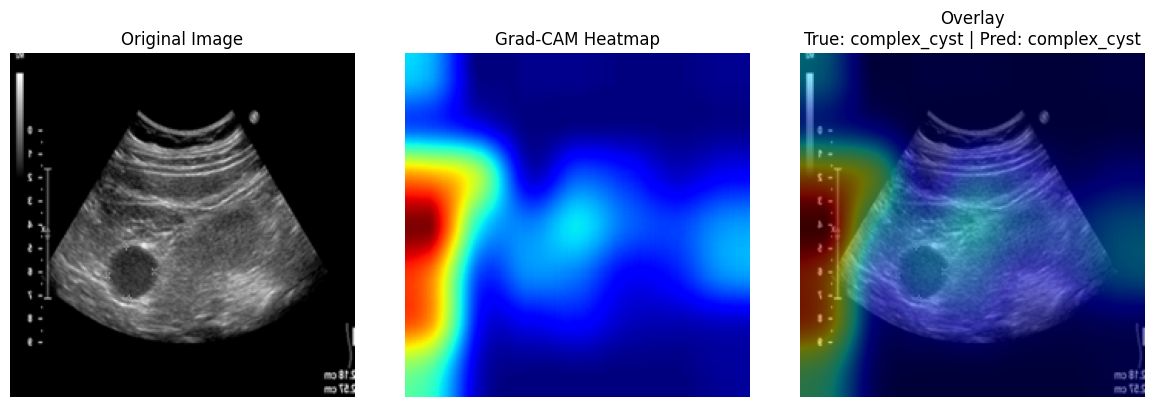

Grad-CAM saved for complex_cyst: /content/drive/MyDrive/Ovarian_Research_Project/figures/gradcam_efficientnet_b3/gradcam_complex_cyst.png


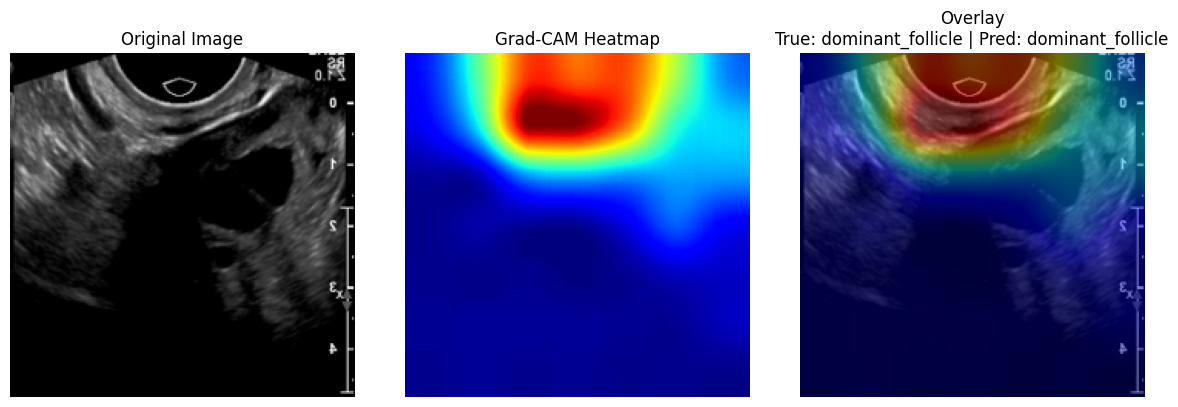

Grad-CAM saved for dominant_follicle: /content/drive/MyDrive/Ovarian_Research_Project/figures/gradcam_efficientnet_b3/gradcam_dominant_follicle.png


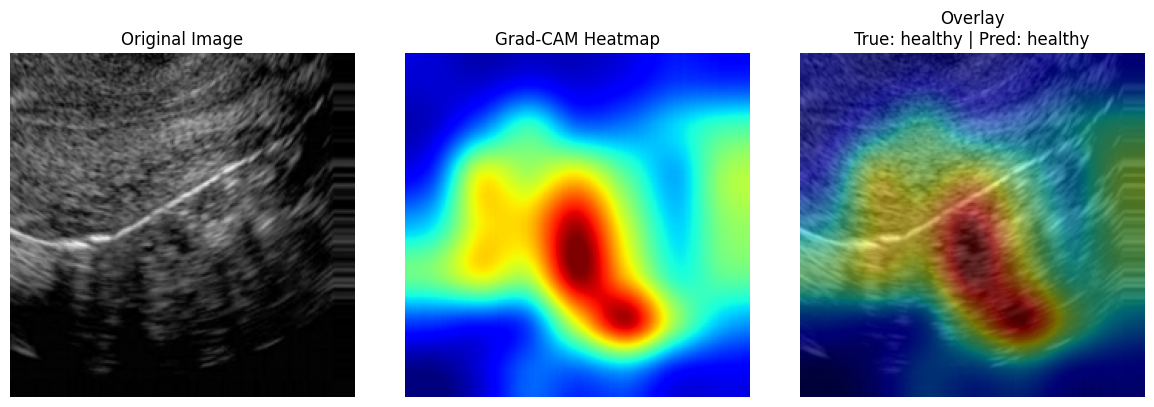

Grad-CAM saved for healthy: /content/drive/MyDrive/Ovarian_Research_Project/figures/gradcam_efficientnet_b3/gradcam_healthy.png


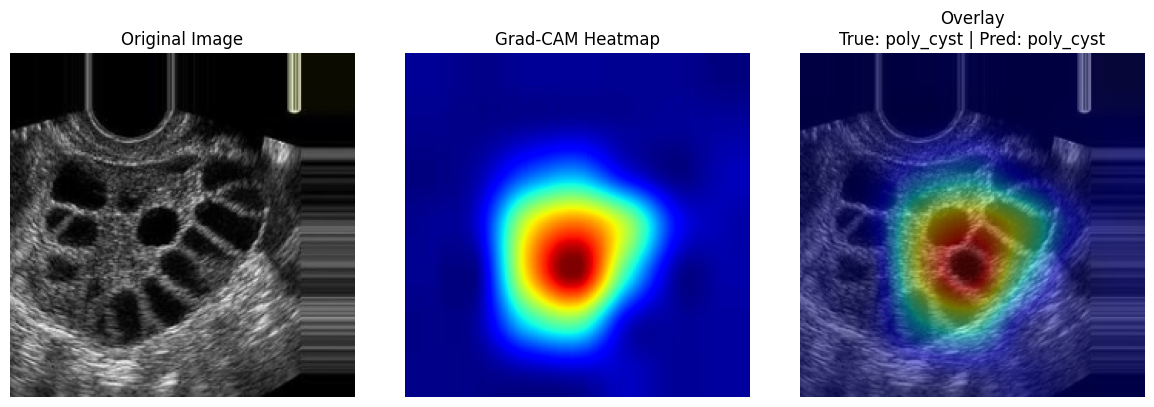

Grad-CAM saved for poly_cyst: /content/drive/MyDrive/Ovarian_Research_Project/figures/gradcam_efficientnet_b3/gradcam_poly_cyst.png


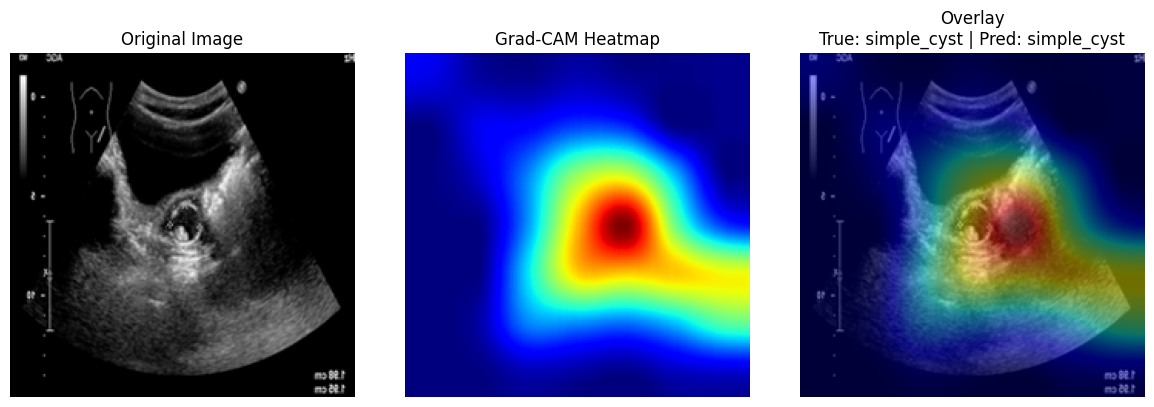

Grad-CAM saved for simple_cyst: /content/drive/MyDrive/Ovarian_Research_Project/figures/gradcam_efficientnet_b3/gradcam_simple_cyst.png


,Class,True Label,Predicted Label,Image Path,GradCAM Path
0,complex_cyst,complex_cyst,complex_cyst,/content/drive/MyDrive/Ovarian_US/complex_cyst...,/content/drive/MyDrive/Ovarian_Research_Projec...
1,dominant_follicle,dominant_follicle,dominant_follicle,/content/drive/MyDrive/Ovarian_US/dominant_fol...,/content/drive/MyDrive/Ovarian_Research_Projec...
2,healthy,healthy,healthy,/content/drive/MyDrive/Ovarian_US/healthy/heal...,/content/drive/MyDrive/Ovarian_Research_Projec...
3,poly_cyst,poly_cyst,poly_cyst,/content/drive/MyDrive/Ovarian_US/poly_cyst/po...,/content/drive/MyDrive/Ovarian_Research_Projec...
4,simple_cyst,simple_cyst,simple_cyst,/content/drive/MyDrive/Ovarian_US/simple_cyst/...,/content/drive/MyDrive/Ovarian_Research_Projec...



Grad-CAM generation completed.
Grad-CAM summary saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_gradcam_summary.csv


In [ ]:
# ============================================================
# CELL 88: GENERATE GRAD-CAM FOR ONE CORRECT IMAGE PER CLASS
# ============================================================

target_layer = gradcam_model.features[-1]
gradcam = GradCAM(gradcam_model, target_layer)

gradcam_records = []

print("Generating Grad-CAM images...\n")

for class_idx, class_name in enumerate(class_names):

    class_df = test_df[test_df["label_id"] == class_idx].reset_index(drop=True)

    selected_row = None
    selected_pred = None

    # Find one correctly predicted image from this class
    for i in range(len(class_df)):
        image_path = class_df.loc[i, "image_path"]

        input_tensor = get_image_tensor(image_path)

        with torch.no_grad():
            output = gradcam_model(input_tensor)
            pred_idx = output.argmax(dim=1).item()

        if pred_idx == class_idx:
            selected_row = class_df.loc[i]
            selected_pred = pred_idx
            break

    if selected_row is None:
        print(f"No correct image found for class: {class_name}")
        continue

    image_path = selected_row["image_path"]

    input_tensor = get_image_tensor(image_path)

    cam, output = gradcam.generate(input_tensor, target_class=selected_pred)

    original_np, heatmap, overlay = create_gradcam_overlay(image_path, cam)

    save_path = gradcam_dir / f"gradcam_{class_name}.png"

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(original_np)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(f"Overlay\nTrue: {class_name} | Pred: {class_names[selected_pred]}")
    plt.axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    gradcam_records.append({
        "Class": class_name,
        "True Label": class_name,
        "Predicted Label": class_names[selected_pred],
        "Image Path": image_path,
        "GradCAM Path": str(save_path)
    })

    print(f"Grad-CAM saved for {class_name}: {save_path}")

gradcam.remove_hooks()

gradcam_df = pd.DataFrame(gradcam_records)

gradcam_summary_path = RESULT_DIR / "efficientnet_b3_gradcam_summary.csv"
gradcam_df.to_csv(gradcam_summary_path, index=False)

display(gradcam_df)

print("\nGrad-CAM generation completed.")
print("Grad-CAM summary saved at:", gradcam_summary_path)

In [ ]:
# ============================================================
# CELL 89: VERIFY GRAD-CAM FILES
# ============================================================

print("Grad-CAM folder:", gradcam_dir)

gradcam_files = list(gradcam_dir.glob("*.png"))

print("Total Grad-CAM images saved:", len(gradcam_files))

for file in gradcam_files:
    print(file.name, "->", file.exists())

print("Grad-CAM summary CSV:", gradcam_summary_path.exists(), "->", gradcam_summary_path)

Grad-CAM folder: /content/drive/MyDrive/Ovarian_Research_Project/figures/gradcam_efficientnet_b3
Total Grad-CAM images saved: 5
gradcam_complex_cyst.png -> True
gradcam_dominant_follicle.png -> True
gradcam_healthy.png -> True
gradcam_poly_cyst.png -> True
gradcam_simple_cyst.png -> True
Grad-CAM summary CSV: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_gradcam_summary.csv


# **FINAL MODEL COMPARISON**

In [ ]:
# ============================================================
# CELL 90: LOAD ALL MODEL RESULT FILES
# ============================================================

comparison_files = {
    "ANN Baseline": RESULT_DIR / "ann_baseline_results.csv",
    "CNN Baseline": RESULT_DIR / "cnn_baseline_results.csv",
    "CNN Deeper": RESULT_DIR / "cnn_deeper_results.csv",
    "LeNet": RESULT_DIR / "lenet_results.csv",
    "VGG16": RESULT_DIR / "vgg16_results.csv",
    "ResNet50": RESULT_DIR / "resnet50_results.csv",
    "EfficientNet-B3": RESULT_DIR / "efficientnet_b3_results.csv",
    "Hybrid EfficientNet-B3 + Transformer": RESULT_DIR / "hybrid_efficientnet_b3_transformer_results.csv"
}

all_model_results = []
missing_files = []

for model_name, file_path in comparison_files.items():
    if file_path.exists():
        df = pd.read_csv(file_path)
        df["Loaded From"] = str(file_path)
        all_model_results.append(df)
        print(f"Loaded: {model_name} -> {file_path}")
    else:
        missing_files.append((model_name, file_path))
        print(f"Missing: {model_name} -> {file_path}")

if len(all_model_results) == 0:
    raise FileNotFoundError("No model result files found. Please check RESULT_DIR.")

final_comparison_raw_df = pd.concat(all_model_results, ignore_index=True)

print("\nAll available model result files loaded successfully.")
display(final_comparison_raw_df.head())

Loaded: ANN Baseline -> /content/drive/MyDrive/Ovarian_Research_Project/results/ann_baseline_results.csv
Loaded: CNN Baseline -> /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_baseline_results.csv
Loaded: CNN Deeper -> /content/drive/MyDrive/Ovarian_Research_Project/results/cnn_deeper_results.csv
Loaded: LeNet -> /content/drive/MyDrive/Ovarian_Research_Project/results/lenet_results.csv
Loaded: VGG16 -> /content/drive/MyDrive/Ovarian_Research_Project/results/vgg16_results.csv
Loaded: ResNet50 -> /content/drive/MyDrive/Ovarian_Research_Project/results/resnet50_results.csv
Loaded: EfficientNet-B3 -> /content/drive/MyDrive/Ovarian_Research_Project/results/efficientnet_b3_results.csv
Loaded: Hybrid EfficientNet-B3 + Transformer -> /content/drive/MyDrive/Ovarian_Research_Project/results/hybrid_efficientnet_b3_transformer_results.csv

All available model result files loaded successfully.


,Model,Image Size,Test Accuracy,Precision,Recall,F1 Score,Best Validation Accuracy,Total Parameters,Trainable Parameters,Epochs Completed,Batch Size,Loaded From,Pretrained,Feature Extractor Frozen,Fine-tuning Strategy,CNN Backbone,Transformer Layers,Transformer Heads,Transformer Dimension
0,ANN Baseline,128x128,0.905039,0.903889,0.905039,0.904356,0.893307,25331205,25331205,10,32,/content/drive/MyDrive/Ovarian_Research_Projec...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,CNN Baseline,224x224,0.963178,0.964405,0.963178,0.963080,0.959263,1733125,1733125,10,32,/content/drive/MyDrive/Ovarian_Research_Projec...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CNN Deeper,224x224,0.999031,0.999036,0.999031,0.999031,0.998060,6682789,6682789,10,32,/content/drive/MyDrive/Ovarian_Research_Projec...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LeNet,224x224,0.813953,0.815459,0.813953,0.804012,0.810863,61581,61581,10,32,/content/drive/MyDrive/Ovarian_Research_Projec...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,VGG16,224x224,1.000000,1.000000,1.000000,1.000000,1.000000,134281029,119566341,10,32,/content/drive/MyDrive/Ovarian_Research_Projec...,True,True,NaN,NaN,NaN,NaN,NaN


In [ ]:
# ============================================================
# CELL 91: CREATE FINAL COMPARISON TABLE
# ============================================================

final_comparison_df = final_comparison_raw_df.copy()

# Standard numeric columns that should exist in results files
numeric_columns = [
    "Test Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Best Validation Accuracy",
    "Total Parameters",
    "Trainable Parameters",
    "Epochs Completed",
    "Batch Size"
]

for col in numeric_columns:
    if col in final_comparison_df.columns:
        final_comparison_df[col] = pd.to_numeric(final_comparison_df[col], errors="coerce")

# Add percentage columns
metric_cols = ["Test Accuracy", "Precision", "Recall", "F1 Score", "Best Validation Accuracy"]

for col in metric_cols:
    if col in final_comparison_df.columns:
        final_comparison_df[col + " (%)"] = final_comparison_df[col] * 100

# Rank models by test accuracy
final_comparison_df["Rank"] = final_comparison_df["Test Accuracy"].rank(
    ascending=False,
    method="dense"
).astype(int)

# Sort by best test accuracy
final_comparison_df = final_comparison_df.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

# Main summary table
summary_columns = [
    "Rank",
    "Model",
    "Image Size",
    "Test Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 Score (%)",
    "Best Validation Accuracy (%)",
    "Total Parameters",
    "Trainable Parameters",
    "Epochs Completed",
    "Batch Size"
]

final_comparison_summary_df = final_comparison_df[summary_columns].copy()

# Round readable columns
round_cols = [
    "Test Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 Score (%)",
    "Best Validation Accuracy (%)"
]

for col in round_cols:
    final_comparison_summary_df[col] = final_comparison_summary_df[col].round(2)

# Save files
final_summary_path = RESULT_DIR / "final_model_comparison_summary.csv"
final_detailed_path = RESULT_DIR / "final_model_comparison_detailed.csv"

final_comparison_summary_df.to_csv(final_summary_path, index=False)
final_comparison_df.to_csv(final_detailed_path, index=False)

print("Final comparison summary saved at:", final_summary_path)
print("Final comparison detailed file saved at:", final_detailed_path)

display(final_comparison_summary_df)

Final comparison summary saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/final_model_comparison_summary.csv
Final comparison detailed file saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/final_model_comparison_detailed.csv


,Rank,Model,Image Size,Test Accuracy (%),Precision (%),Recall (%),F1 Score (%),Best Validation Accuracy (%),Total Parameters,Trainable Parameters,Epochs Completed,Batch Size
0,1,VGG16,224x224,100.00,100.00,100.00,100.00,100.00,134281029,119566341,10,32
1,2,CNN Deeper,224x224,99.90,99.90,99.90,99.90,99.81,6682789,6682789,10,32
2,3,EfficientNet-B3,224x224,99.81,99.81,99.81,99.81,99.90,10703917,3884799,10,32
3,4,Hybrid EfficientNet-B3 + Transformer,224x224,99.61,99.61,99.61,99.61,99.22,12177965,5358847,5,32
4,5,CNN Baseline,224x224,96.32,96.44,96.32,96.31,95.93,1733125,1733125,10,32
5,6,ResNet50,224x224,95.45,95.55,95.45,95.43,94.67,23518277,10245,10,32
6,7,ANN Baseline,128x128,90.50,90.39,90.50,90.44,89.33,25331205,25331205,10,32
7,8,LeNet,224x224,81.40,81.55,81.40,80.40,81.09,61581,61581,10,32


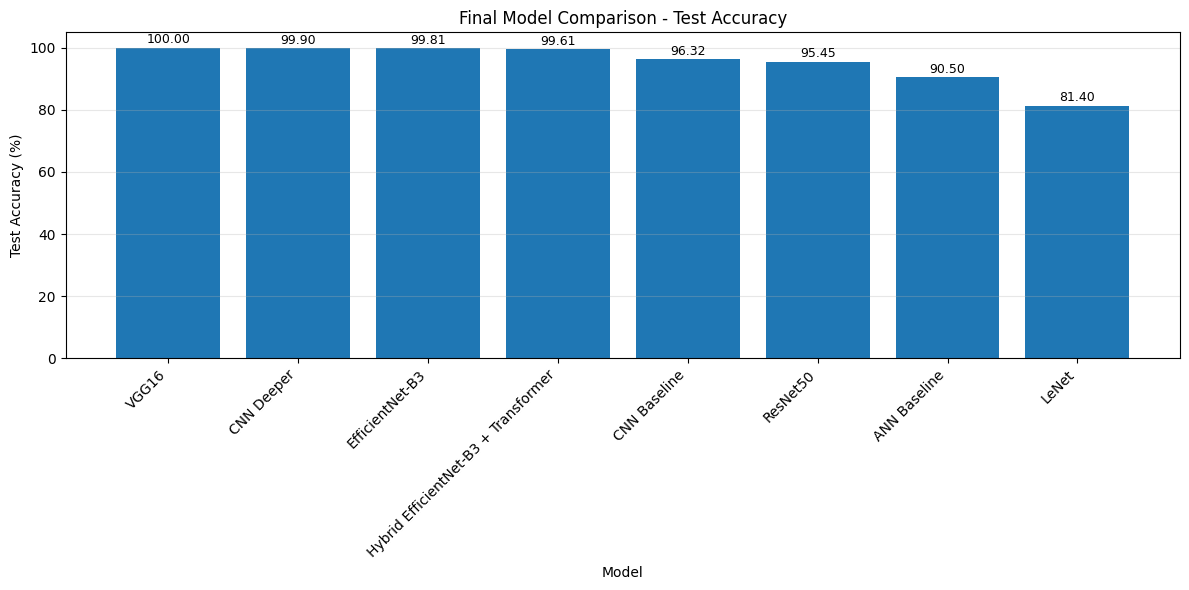

Final test accuracy comparison graph saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/final_model_test_accuracy_comparison.png


In [ ]:
# ============================================================
# CELL 92: FINAL TEST ACCURACY COMPARISON GRAPH
# ============================================================

final_accuracy_plot_path = FIGURE_DIR / "final_model_test_accuracy_comparison.png"

plot_df = final_comparison_summary_df.copy()

plt.figure(figsize=(12, 6))
bars = plt.bar(plot_df["Model"], plot_df["Test Accuracy (%)"])

plt.title("Final Model Comparison - Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_df["Test Accuracy (%)"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(final_accuracy_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Final test accuracy comparison graph saved at:", final_accuracy_plot_path)

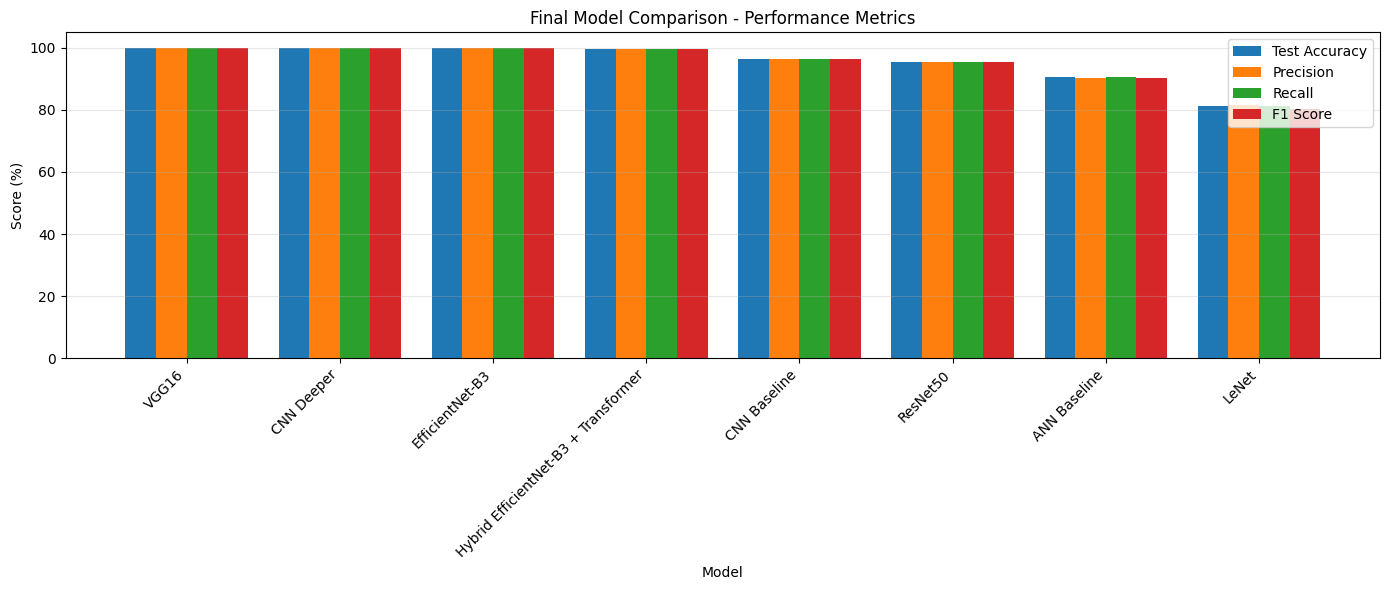

Final performance metric comparison graph saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/final_model_metric_comparison.png


In [ ]:
# ============================================================
# CELL 93: PRECISION, RECALL, F1 SCORE COMPARISON GRAPH
# ============================================================

final_metric_plot_path = FIGURE_DIR / "final_model_metric_comparison.png"

metric_plot_df = final_comparison_summary_df.copy()

x = np.arange(len(metric_plot_df))
width = 0.2

plt.figure(figsize=(14, 6))
plt.bar(x - 1.5 * width, metric_plot_df["Test Accuracy (%)"], width, label="Test Accuracy")
plt.bar(x - 0.5 * width, metric_plot_df["Precision (%)"], width, label="Precision")
plt.bar(x + 0.5 * width, metric_plot_df["Recall (%)"], width, label="Recall")
plt.bar(x + 1.5 * width, metric_plot_df["F1 Score (%)"], width, label="F1 Score")

plt.title("Final Model Comparison - Performance Metrics")
plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.xticks(x, metric_plot_df["Model"], rotation=45, ha="right")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(final_metric_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Final performance metric comparison graph saved at:", final_metric_plot_path)

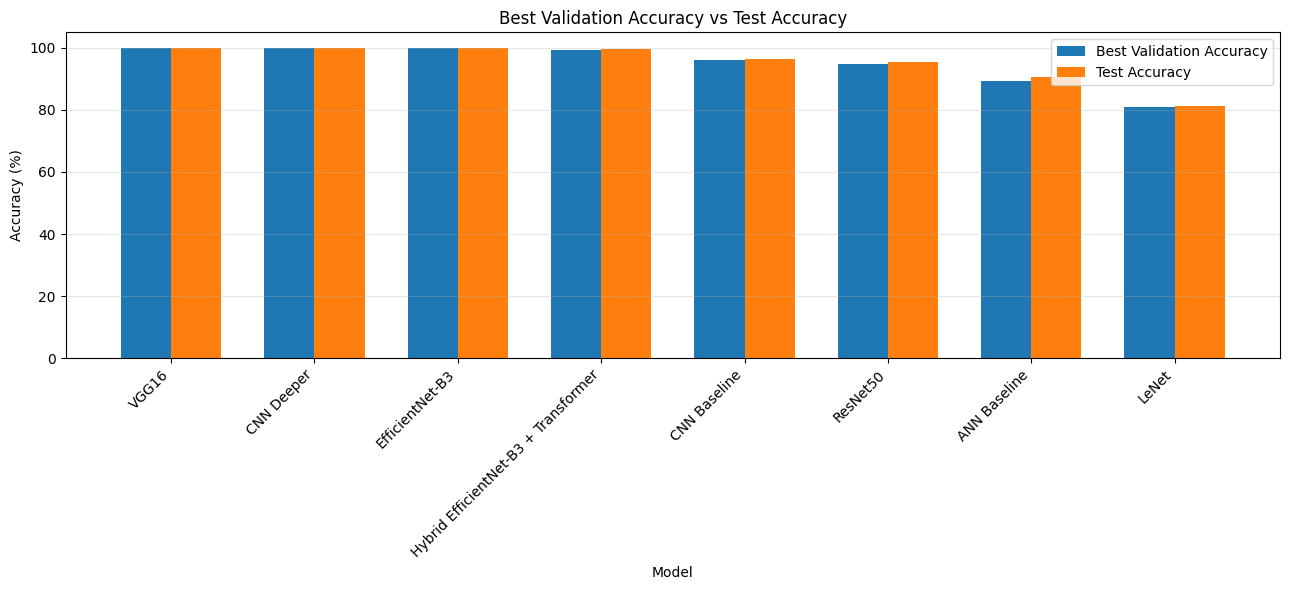

Validation vs test accuracy graph saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/final_validation_vs_test_accuracy.png


In [ ]:
# ============================================================
# CELL 94: BEST VALIDATION VS TEST ACCURACY GRAPH
# ============================================================

final_val_test_plot_path = FIGURE_DIR / "final_validation_vs_test_accuracy.png"

val_test_df = final_comparison_summary_df.copy()

x = np.arange(len(val_test_df))
width = 0.35

plt.figure(figsize=(13, 6))
plt.bar(x - width/2, val_test_df["Best Validation Accuracy (%)"], width, label="Best Validation Accuracy")
plt.bar(x + width/2, val_test_df["Test Accuracy (%)"], width, label="Test Accuracy")

plt.title("Best Validation Accuracy vs Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.xticks(x, val_test_df["Model"], rotation=45, ha="right")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(final_val_test_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Validation vs test accuracy graph saved at:", final_val_test_plot_path)

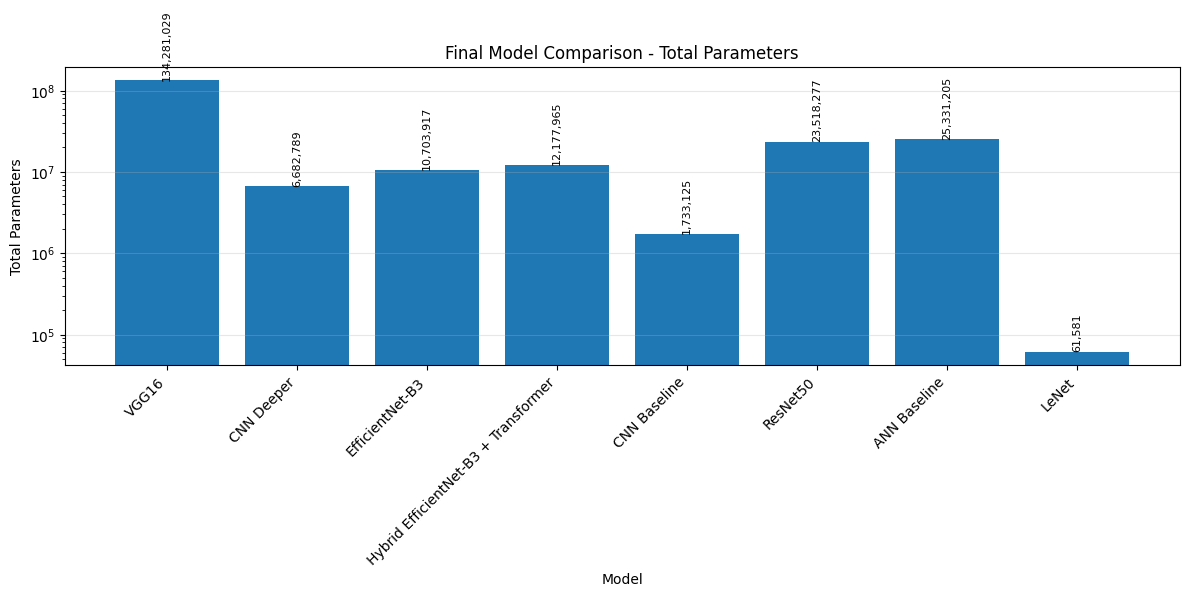

Final parameter comparison graph saved at: /content/drive/MyDrive/Ovarian_Research_Project/figures/final_model_parameter_comparison.png


In [ ]:
# ============================================================
# CELL 95: TOTAL PARAMETERS COMPARISON GRAPH
# ============================================================

final_parameter_plot_path = FIGURE_DIR / "final_model_parameter_comparison.png"

param_df = final_comparison_summary_df.copy()

plt.figure(figsize=(12, 6))
bars = plt.bar(param_df["Model"], param_df["Total Parameters"])

plt.title("Final Model Comparison - Total Parameters")
plt.xlabel("Model")
plt.ylabel("Total Parameters")
plt.xticks(rotation=45, ha="right")
plt.yscale("log")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, param_df["Total Parameters"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(value):,}",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=90
    )

plt.tight_layout()
plt.savefig(final_parameter_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Final parameter comparison graph saved at:", final_parameter_plot_path)

In [ ]:
# ============================================================
# CELL 96: FINAL RANKING TEXT SUMMARY
# ============================================================

best_model_row = final_comparison_summary_df.iloc[0]

summary_text_path = RESULT_DIR / "final_model_comparison_summary.txt"

summary_lines = []
summary_lines.append("FINAL MODEL COMPARISON SUMMARY\n")
summary_lines.append("=" * 60 + "\n")
summary_lines.append(f"Best Model: {best_model_row['Model']}\n")
summary_lines.append(f"Rank: {best_model_row['Rank']}\n")
summary_lines.append(f"Test Accuracy: {best_model_row['Test Accuracy (%)']:.2f}%\n")
summary_lines.append(f"Precision: {best_model_row['Precision (%)']:.2f}%\n")
summary_lines.append(f"Recall: {best_model_row['Recall (%)']:.2f}%\n")
summary_lines.append(f"F1 Score: {best_model_row['F1 Score (%)']:.2f}%\n")
summary_lines.append(f"Best Validation Accuracy: {best_model_row['Best Validation Accuracy (%)']:.2f}%\n")
summary_lines.append(f"Total Parameters: {int(best_model_row['Total Parameters']):,}\n")
summary_lines.append(f"Trainable Parameters: {int(best_model_row['Trainable Parameters']):,}\n")
summary_lines.append(f"Epochs Completed: {int(best_model_row['Epochs Completed'])}\n")
summary_lines.append(f"Batch Size: {int(best_model_row['Batch Size'])}\n")

with open(summary_text_path, "w") as f:
    f.writelines(summary_lines)

print("Final model comparison summary text saved at:", summary_text_path)

print("\nTop Ranked Model")
print("-" * 30)
for line in summary_lines[2:]:
    print(line.strip())

Final model comparison summary text saved at: /content/drive/MyDrive/Ovarian_Research_Project/results/final_model_comparison_summary.txt

Top Ranked Model
------------------------------
Best Model: VGG16
Rank: 1
Test Accuracy: 100.00%
Precision: 100.00%
Recall: 100.00%
F1 Score: 100.00%
Best Validation Accuracy: 100.00%
Total Parameters: 134,281,029
Trainable Parameters: 119,566,341
Epochs Completed: 10
Batch Size: 32


In [ ]:
# ============================================================
# CELL 97: VERIFY ALL FINAL COMPARISON FILES
# ============================================================

files_to_check = {
    "Final comparison summary CSV": RESULT_DIR / "final_model_comparison_summary.csv",
    "Final comparison detailed CSV": RESULT_DIR / "final_model_comparison_detailed.csv",
    "Final comparison text summary": RESULT_DIR / "final_model_comparison_summary.txt",
    "Final test accuracy graph": FIGURE_DIR / "final_model_test_accuracy_comparison.png",
    "Final metric comparison graph": FIGURE_DIR / "final_model_metric_comparison.png",
    "Final validation vs test graph": FIGURE_DIR / "final_validation_vs_test_accuracy.png",
    "Final parameter comparison graph": FIGURE_DIR / "final_model_parameter_comparison.png"
}

for name, path in files_to_check.items():
    print(f"{name}: {path.exists()} -> {path}")

Final comparison summary CSV: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/final_model_comparison_summary.csv
Final comparison detailed CSV: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/final_model_comparison_detailed.csv
Final comparison text summary: True -> /content/drive/MyDrive/Ovarian_Research_Project/results/final_model_comparison_summary.txt
Final test accuracy graph: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/final_model_test_accuracy_comparison.png
Final metric comparison graph: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/final_model_metric_comparison.png
Final validation vs test graph: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/final_validation_vs_test_accuracy.png
Final parameter comparison graph: True -> /content/drive/MyDrive/Ovarian_Research_Project/figures/final_model_parameter_comparison.png


# **TESTING ON REAL TIME DATA**

Using device: cpu
Model path: /content/drive/MyDrive/Ovarian_Research_Project/models/efficientnet_b3_best.pth
EfficientNet-B3 model loaded successfully.


Saving testing one more.jpg to testing one more.jpg

Prediction Result
----------------------------------------
Predicted Class: simple_cyst
Confidence: 88.77 %

Class-wise Probabilities:
complex_cyst: 11.19%
dominant_follicle: 0.01%
healthy: 0.02%
poly_cyst: 0.02%
simple_cyst: 88.77%


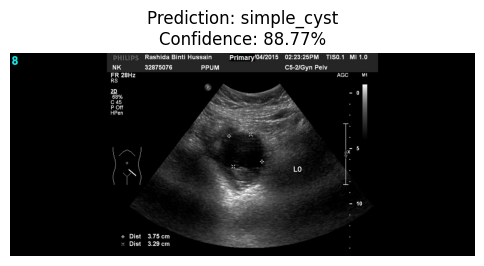

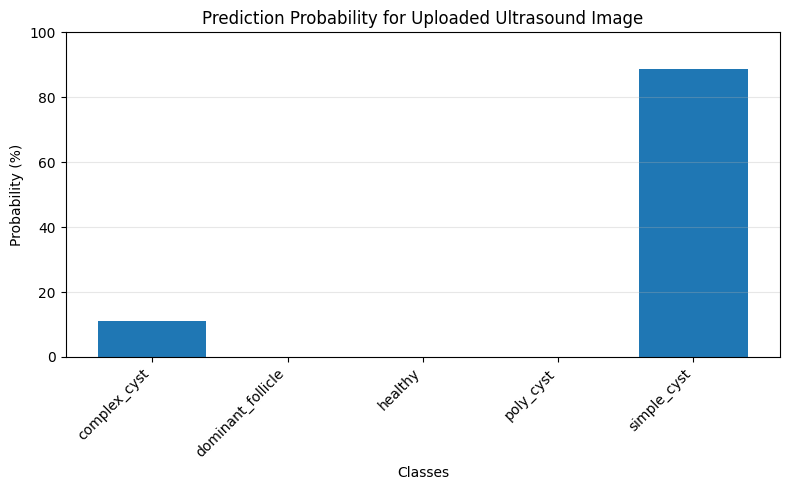

In [ ]:
# ============================================================
# REAL-TIME SINGLE IMAGE PREDICTION USING EFFICIENTNET-B3
# ============================================================

from google.colab import files
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# Basic settings
# ------------------------------------------------------------

PREDICTION_MODEL_NAME = "efficientnet_b3"
IMG_SIZE = 224

class_names = ["complex_cyst", "dominant_follicle", "healthy", "poly_cyst", "simple_cyst"]
NUM_CLASSES = len(class_names)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_DIR = Path("/content/drive/MyDrive/Ovarian_Research_Project/models")
best_model_path = MODEL_DIR / "efficientnet_b3_best.pth"

if not best_model_path.exists():
    raise FileNotFoundError(f"Model file not found: {best_model_path}")

print("Using device:", device)
print("Model path:", best_model_path)

# ------------------------------------------------------------
# Load EfficientNet-B3 model architecture
# ------------------------------------------------------------

prediction_model = models.efficientnet_b3(weights=None)

in_features = prediction_model.classifier[1].in_features
prediction_model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

prediction_model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

prediction_model = prediction_model.to(device)
prediction_model.eval()

print("EfficientNet-B3 model loaded successfully.")

# ------------------------------------------------------------
# Image preprocessing
# ------------------------------------------------------------

predict_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Upload image
# ------------------------------------------------------------

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

image = Image.open(image_path).convert("RGB")

input_tensor = predict_transform(image).unsqueeze(0).to(device)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

with torch.no_grad():
    outputs = prediction_model(input_tensor)
    probabilities = F.softmax(outputs, dim=1)[0]

predicted_index = torch.argmax(probabilities).item()
predicted_class = class_names[predicted_index]
confidence = probabilities[predicted_index].item() * 100

print("\nPrediction Result")
print("-" * 40)
print("Predicted Class:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

print("\nClass-wise Probabilities:")
for cls, prob in zip(class_names, probabilities.cpu().numpy()):
    print(f"{cls}: {prob * 100:.2f}%")

# ------------------------------------------------------------
# Display uploaded image and prediction probabilities
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%")
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(class_names, probabilities.cpu().numpy() * 100)
plt.xlabel("Classes")
plt.ylabel("Probability (%)")
plt.title("Prediction Probability for Uploaded Ultrasound Image")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## If you know the true class of uploaded image

After prediction, run this small cell:

In [ ]:
# ============================================================
# OPTIONAL: CHECK IF PREDICTION IS CORRECT
# ============================================================

true_class = "simple_cyst"   # change this according to your uploaded image

if true_class not in class_names:
    print("Invalid true class. Use one of these:", class_names)
else:
    print("True Class:", true_class)
    print("Predicted Class:", predicted_class)

    if predicted_class == true_class:
        print("Result: Correct prediction")
    else:
        print("Result: Wrong prediction")

True Class: simple_cyst
Predicted Class: simple_cyst
Result: Correct prediction
